In [1]:

# ============================================================
# CELL 1 — Optional dependency installation
# ============================================================
import importlib.util, subprocess, sys

REQUIRED = {
    "lightgbm": "lightgbm",
    "xgboost": "xgboost",
    "catboost": "catboost",
    "shap": "shap",
    "sklearn": "scikit-learn",
    "scipy": "scipy",
    "joblib": "joblib",
}
missing = [pip_name for module, pip_name in REQUIRED.items()
           if importlib.util.find_spec(module) is None]
if missing:
    print("Installing missing packages:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
else:
    print("All required packages are available.")


All required packages are available.


In [2]:
# ============================================================
# CELL 2 — Imports, reproducibility, directories, publication fonts
# ============================================================
import os, gc, json, math, random, shutil, warnings, platform, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    average_precision_score, roc_auc_score, precision_score, recall_score,
    f1_score, confusion_matrix, brier_score_loss, precision_recall_curve,
    silhouette_score, davies_bouldin_score, adjusted_rand_score,
)
from scipy.stats import norm, spearmanr
import joblib

from lightgbm import LGBMRegressor, LGBMClassifier
from xgboost import XGBRegressor, XGBClassifier
from catboost import CatBoostRegressor, CatBoostClassifier
import shap

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
random.seed(SEED)

INPUT_ROOTS = [Path("/kaggle/input"), Path("/mnt/data"), Path(".")]
WORK_ROOT = Path("/kaggle/working/NEM_Q1_COMPLETE") if Path("/kaggle/working").exists() else Path("/mnt/data/NEM_Q1_COMPLETE")

TABLE_DIR = WORK_ROOT / "tables"
FIG_DIR = WORK_ROOT / "figures"
MODEL_DIR = WORK_ROOT / "models"
PRED_DIR = WORK_ROOT / "predictions"
CACHE_DIR = WORK_ROOT / "cache"
LOG_DIR = WORK_ROOT / "logs"
SHAP_DIR = WORK_ROOT / "shap"
for p in [WORK_ROOT, TABLE_DIR, FIG_DIR, MODEL_DIR, PRED_DIR, CACHE_DIR, LOG_DIR, SHAP_DIR]:
    p.mkdir(parents=True, exist_ok=True)

MODEL_START = pd.Timestamp("1964-01-01 00:00:00")
DEV_END = pd.Timestamp("2020-12-31 23:00:00")
CONFIRM_START = pd.Timestamp("2021-01-01 00:00:00")
CONFIRM_END = pd.Timestamp("2025-12-31 23:00:00")
DEPLOY_START = pd.Timestamp("2026-01-01 00:00:00")
DEPLOY_END = pd.Timestamp("2026-01-31 23:00:00")

REG_HORIZONS = [1, 3, 6, 12, 24]
CLS_HORIZONS = [3, 6, 12, 24]
MIN_ACTIVE_NM = 5
MAX_CONTEXT_H = 171
CALIBRATION_YEARS = 2
BOOTSTRAP_REPS = 2000
DM_MIN_HAC_LAG = 24

GMM_K_VALUES = list(range(2, 11))
GMM_MIN_STATE_FRACTION = 0.02
GMM_N_INIT = 3
GMM_MAX_ITER = 300
SILHOUETTE_SAMPLE = 5000  # diagnostic sample only; BIC/GMM fitting still uses full development data

SHAP_GLOBAL_N = 5000
SHAP_STATE_N = 2000
STATE_SHAP_REG_HORIZON = 6
STATE_SHAP_CLS_HORIZON = 12

RESUME = True
USE_GPU = False

plt.rcParams.update({
    "font.size": 15,
    "axes.titlesize": 19,
    "axes.labelsize": 17,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 13,
    "figure.titlesize": 20,
    "lines.linewidth": 2.0,
    "lines.markersize": 7,
})

def save_figure(fig, stem):
    png = FIG_DIR / f"{stem}.png"
    pdf = FIG_DIR / f"{stem}.pdf"
    fig.savefig(png, dpi=300, bbox_inches="tight")
    fig.savefig(pdf, bbox_inches="tight")
    return png, pdf

print("Work root:", WORK_ROOT)


Work root: /kaggle/working/NEM_Q1_COMPLETE


In [3]:

# ============================================================
# CELL 3 — Exact 38-station schema and dataset discovery
# ============================================================
STATIONS = [
    "alert", "apatity", "barentzburg", "calgary", "cape_schmidt", "chicago",
    "churchill", "climax", "deep_river", "durham", "goosebay", "hermanus",
    "inuvik", "jungraufjoch", "kerguelen", "kiel", "kiev", "leeds",
    "lomnicki_stit", "mcmurdo", "mobile_cosmic_ray_lab", "magadan", "moscow",
    "mirny", "mt_wellington", "mt_washington", "mawson", "newark",
    "novosibirsk", "ottawa", "oulu", "peawanuck", "sulphur_mt", "sanae",
    "terre_adelie", "thule", "tixie_bay", "zugspitze"
]
DATE_COLS = ["year", "month", "day", "hour"]
REQUIRED_FILES = {
    "Hourlyphi.csv", "NMdatatable.csv", "kappavariation.csv", "NMRigCutoff.csv"
}

def locate_dataset():
    candidates = []
    for root0 in INPUT_ROOTS:
        if not root0.exists():
            continue
        for root, _, files in os.walk(root0):
            if REQUIRED_FILES.issubset(set(files)):
                candidates.append(Path(root))
    if not candidates:
        raise FileNotFoundError(
            "Add Hourlyphi.csv, NMdatatable.csv, kappavariation.csv and "
            "NMRigCutoff.csv to one Kaggle input folder."
        )
    candidates = sorted(set(candidates), key=lambda p: (0 if "/kaggle/input" in str(p) else 1, len(str(p))))
    print("Candidate dataset folders:")
    for i, p in enumerate(candidates):
        print(f"  {i}: {p}")
    return candidates[0]

DATA_DIR = locate_dataset()
print("Using:", DATA_DIR)


Candidate dataset folders:
  0: /kaggle/input/datasets/sadiajahanmoon/cosmicray/Hourlyphiv3
Using: /kaggle/input/datasets/sadiajahanmoon/cosmicray/Hourlyphiv3


In [4]:

# ============================================================
# CELL 4 — Load and align the four hourly files
# ============================================================
def numericize(df, cols):
    for c in cols:
        df[c] = pd.to_numeric(df[c], errors="coerce")
    return df

def add_datetime(df):
    df = df.copy()
    df["datetime"] = pd.to_datetime({
        "year": df["year"], "month": df["month"],
        "day": df["day"], "hour": df["hour"]
    }, errors="coerce")
    return df

def load_phi(path):
    df = pd.read_csv(path, header=None, low_memory=False)
    if df.shape[1] != 6:
        raise ValueError(f"{path.name}: expected 6 columns, found {df.shape[1]}")
    df.columns = DATE_COLS + ["phi_mv", "phi_fit_metric"]
    return add_datetime(numericize(df, DATE_COLS + ["phi_mv", "phi_fit_metric"]))

def load_station_matrix(path, prefix):
    df = pd.read_csv(path, header=None, low_memory=False)
    expected = 4 + len(STATIONS)
    if df.shape[1] != expected:
        raise ValueError(f"{path.name}: expected {expected} columns, found {df.shape[1]}")
    value_cols = [f"{prefix}_{s}" for s in STATIONS]
    df.columns = DATE_COLS + value_cols
    return add_datetime(numericize(df, DATE_COLS + value_cols))

phi = load_phi(DATA_DIR / "Hourlyphi.csv")
nm = load_station_matrix(DATA_DIR / "NMdatatable.csv", "nm")
kap = load_station_matrix(DATA_DIR / "kappavariation.csv", "kap")
rc = load_station_matrix(DATA_DIR / "NMRigCutoff.csv", "rc")

assert phi["datetime"].equals(nm["datetime"])
assert phi["datetime"].equals(kap["datetime"])
assert phi["datetime"].equals(rc["datetime"])
assert phi["datetime"].notna().all()
assert not phi["datetime"].duplicated().any()

master = phi[["datetime", "phi_mv", "phi_fit_metric"]].copy()
master = master.merge(nm.drop(columns=DATE_COLS), on="datetime", how="left", validate="one_to_one")
master = master.merge(kap.drop(columns=DATE_COLS), on="datetime", how="left", validate="one_to_one")
master = master.merge(rc.drop(columns=DATE_COLS), on="datetime", how="left", validate="one_to_one")
master = master.sort_values("datetime").set_index("datetime").replace([np.inf, -np.inf], np.nan)

full_index = pd.date_range(master.index.min(), master.index.max(), freq="h")
missing_hourly_rows = len(full_index) - len(master)
master = master.reindex(full_index)
master.index.name = "datetime"

NM_COLS = [f"nm_{s}" for s in STATIONS]
KAP_COLS = [f"kap_{s}" for s in STATIONS]
RC_COLS = [f"rc_{s}" for s in STATIONS]
master["n_active_nm_raw"] = master[NM_COLS].notna().sum(axis=1)

audit = {
    "rows": int(len(master)),
    "start": str(master.index.min()),
    "end": str(master.index.max()),
    "missing_hourly_rows_before_reindex": int(missing_hourly_rows),
    "phi_coverage_all": float(master["phi_mv"].notna().mean()),
    "phi_coverage_1964_2025": float(master.loc[MODEL_START:CONFIRM_END, "phi_mv"].notna().mean()),
    "median_active_nm_1964_2025": float(master.loc[MODEL_START:CONFIRM_END, "n_active_nm_raw"].median()),
}
with open(LOG_DIR / "dataset_audit.json", "w") as f:
    json.dump(audit, f, indent=2)
print(audit)


{'rows': 658200, 'start': '1951-01-01 00:00:00', 'end': '2026-01-31 23:00:00', 'missing_hourly_rows_before_reindex': 0, 'phi_coverage_all': 0.9903053783044667, 'phi_coverage_1964_2025': 0.9977939444787894, 'median_active_nm_1964_2025': 23.0}


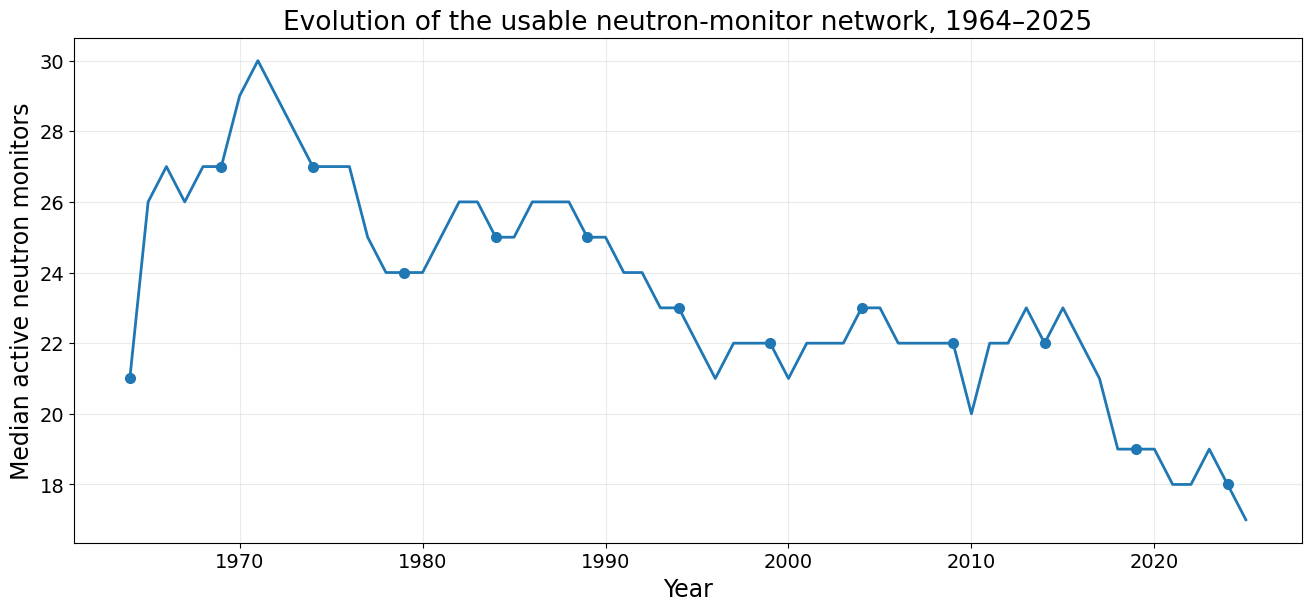

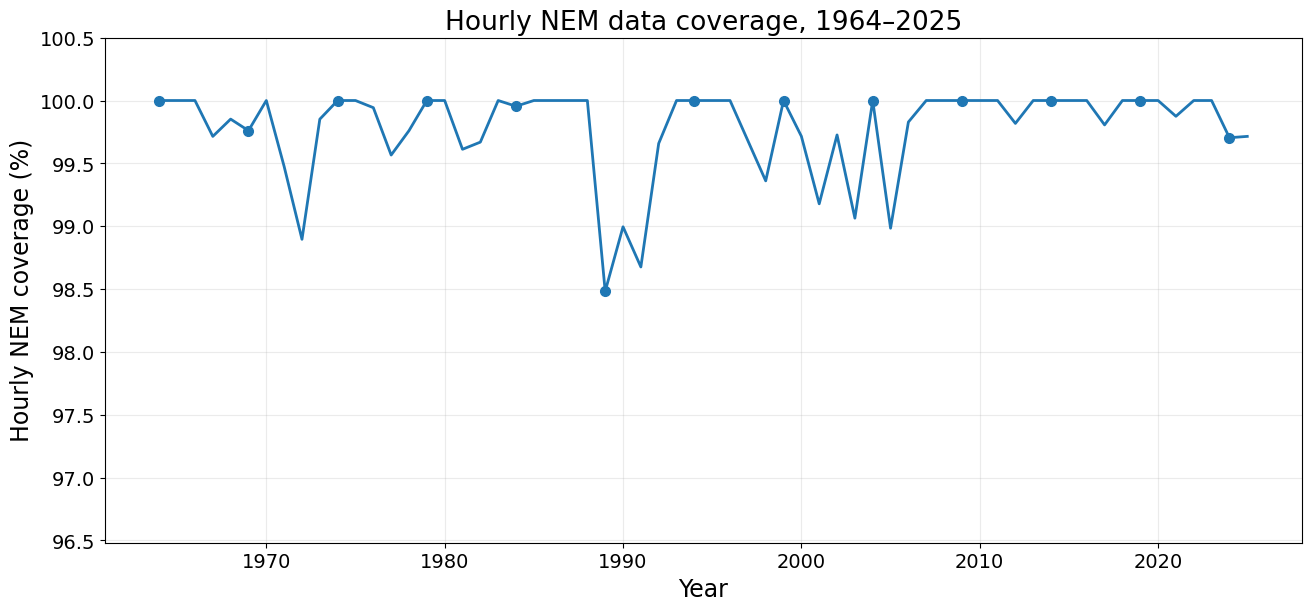

In [5]:

# ============================================================
# CELL 5 — Journal descriptive plots
# ============================================================
period = master.loc[MODEL_START:CONFIRM_END]
annual = pd.DataFrame(index=period.resample("YS").size().index)
annual["phi_coverage_pct"] = period["phi_mv"].resample("YS").apply(lambda s: 100*s.notna().mean())
annual["median_active_nm"] = period["n_active_nm_raw"].resample("YS").median()
annual.index = annual.index.year
annual.index.name = "year"
annual.to_csv(TABLE_DIR / "annual_data_availability.csv")

fig, ax = plt.subplots(figsize=(13, 6), constrained_layout=True)
ax.plot(annual.index, annual["median_active_nm"], marker="o", markevery=5)
ax.set_xlabel("Year")
ax.set_ylabel("Median active neutron monitors")
ax.set_title("Evolution of the usable neutron-monitor network, 1964–2025")
ax.grid(alpha=0.25)
save_figure(fig, "Fig01_annual_active_nm")
plt.show()

fig, ax = plt.subplots(figsize=(13, 6), constrained_layout=True)
ax.plot(annual.index, annual["phi_coverage_pct"], marker="o", markevery=5)
ax.set_xlabel("Year")
ax.set_ylabel("Hourly NEM coverage (%)")
ax.set_ylim(max(0, annual["phi_coverage_pct"].min()-2), 100.5)
ax.set_title("Hourly NEM data coverage, 1964–2025")
ax.grid(alpha=0.25)
save_figure(fig, "Fig02_annual_nem_coverage")
plt.show()


In [6]:

# ============================================================
# CELL 6 — Expanding-window temporal development folds
# ============================================================
FOLDS = [
    dict(fold=1, train_start="1964-01-01 00:00:00", train_end="1990-12-31 23:00:00",
         val_start="1991-01-01 00:00:00", val_end="1995-12-31 23:00:00"),
    dict(fold=2, train_start="1964-01-01 00:00:00", train_end="1995-12-31 23:00:00",
         val_start="1996-01-01 00:00:00", val_end="2000-12-31 23:00:00"),
    dict(fold=3, train_start="1964-01-01 00:00:00", train_end="2000-12-31 23:00:00",
         val_start="2001-01-01 00:00:00", val_end="2005-12-31 23:00:00"),
    dict(fold=4, train_start="1964-01-01 00:00:00", train_end="2005-12-31 23:00:00",
         val_start="2006-01-01 00:00:00", val_end="2010-12-31 23:00:00"),
    dict(fold=5, train_start="1964-01-01 00:00:00", train_end="2010-12-31 23:00:00",
         val_start="2011-01-01 00:00:00", val_end="2015-12-31 23:00:00"),
    dict(fold=6, train_start="1964-01-01 00:00:00", train_end="2015-12-31 23:00:00",
         val_start="2016-01-01 00:00:00", val_end="2020-12-31 23:00:00"),
]
FOLDS = [{k: (pd.Timestamp(v) if k != "fold" else v) for k, v in d.items()} for d in FOLDS]
pd.DataFrame(FOLDS).to_csv(TABLE_DIR / "temporal_cv_folds.csv", index=False)
display(pd.DataFrame(FOLDS))


,fold,train_start,train_end,val_start,val_end
0,1,1964-01-01,1990-12-31 23:00:00,1991-01-01,1995-12-31 23:00:00
1,2,1964-01-01,1995-12-31 23:00:00,1996-01-01,2000-12-31 23:00:00
2,3,1964-01-01,2000-12-31 23:00:00,2001-01-01,2005-12-31 23:00:00
3,4,1964-01-01,2005-12-31 23:00:00,2006-01-01,2010-12-31 23:00:00
4,5,1964-01-01,2010-12-31 23:00:00,2011-01-01,2015-12-31 23:00:00
5,6,1964-01-01,2015-12-31 23:00:00,2016-01-01,2020-12-31 23:00:00


In [7]:

# ============================================================
# CELL 7 — Causal feature functions
# ============================================================
def station_training_baselines(raw, train_start, train_end):
    tr = raw.loc[train_start:train_end]
    nm_base = tr[NM_COLS].median(axis=0, skipna=True).replace(0, np.nan)
    kap_base = tr[KAP_COLS].median(axis=0, skipna=True).replace(0, np.nan)
    return nm_base, kap_base

def row_mad(arr):
    med = np.nanmedian(arr, axis=1)
    return np.nanmedian(np.abs(arr - med[:, None]), axis=1)

def row_iqr(arr):
    return np.nanpercentile(arr, 75, axis=1) - np.nanpercentile(arr, 25, axis=1)

def causal_roll(series, window, stat):
    minp = max(2, int(math.ceil(0.75 * window)))
    r = series.rolling(window=window, min_periods=minp)
    if stat == "mean":
        return r.mean()
    if stat == "std":
        return r.std()
    raise ValueError(stat)

def future_max_abs_excursion(phi_series, h):
    current = phi_series.to_numpy(dtype=np.float64)
    future = np.column_stack([
        phi_series.shift(-s).to_numpy(dtype=np.float64) for s in range(1, h + 1)
    ])
    diffs = np.abs(future - current[:, None])
    valid = np.isfinite(future).all(axis=1) & np.isfinite(current)
    out = np.full(len(phi_series), np.nan, dtype=np.float64)
    out[valid] = np.max(diffs[valid], axis=1)
    return out

def build_feature_frame(raw, train_start, train_end, output_start, output_end):
    train_start, train_end = pd.Timestamp(train_start), pd.Timestamp(train_end)
    output_start, output_end = pd.Timestamp(output_start), pd.Timestamp(output_end)

    nm_base, kap_base = station_training_baselines(raw, train_start, train_end)
    context_start = output_start - pd.Timedelta(hours=MAX_CONTEXT_H)
    xraw = raw.loc[context_start:output_end].copy()
    feat = pd.DataFrame(index=xraw.index)

    feat["phi_t"] = xraw["phi_mv"]
    for lag in [1, 3, 6, 12, 24, 48, 72, 168]:
        feat[f"phi_lag_{lag}"] = xraw["phi_mv"].shift(lag)
    for d in [1, 3, 6, 12, 24]:
        feat[f"phi_diff_{d}"] = xraw["phi_mv"] - xraw["phi_mv"].shift(d)
    for w in [6, 24]:
        feat[f"phi_roll_mean_{w}"] = causal_roll(xraw["phi_mv"], w, "mean")
        feat[f"phi_roll_std_{w}"] = causal_roll(xraw["phi_mv"], w, "std")
        feat[f"phi_slope_{w}"] = (xraw["phi_mv"] - xraw["phi_mv"].shift(w)) / float(w)

    feat["rmse_t"] = xraw["phi_fit_metric"]
    for lag in [1, 6, 24]:
        feat[f"rmse_lag_{lag}"] = xraw["phi_fit_metric"].shift(lag)
    feat["rmse_diff_6"] = xraw["phi_fit_metric"] - xraw["phi_fit_metric"].shift(6)
    feat["rmse_roll_mean_24"] = causal_roll(xraw["phi_fit_metric"], 24, "mean")

    nm_norm = xraw[NM_COLS].divide(nm_base, axis=1)
    nm_arr = nm_norm.to_numpy(dtype=np.float64)
    feat["nm_median"] = np.nanmedian(nm_arr, axis=1)
    feat["nm_std"] = np.nanstd(nm_arr, axis=1, ddof=1)
    feat["nm_mad"] = row_mad(nm_arr)
    feat["nm_iqr"] = row_iqr(nm_arr)
    feat["n_active_nm"] = np.sum(np.isfinite(nm_arr), axis=1)
    feat["nm_median_diff_1"] = feat["nm_median"] - feat["nm_median"].shift(1)
    feat["nm_median_diff_6"] = feat["nm_median"] - feat["nm_median"].shift(6)
    feat["nm_mad_diff_1"] = feat["nm_mad"] - feat["nm_mad"].shift(1)
    feat["nm_mad_diff_6"] = feat["nm_mad"] - feat["nm_mad"].shift(6)

    kap_norm = xraw[KAP_COLS].divide(kap_base, axis=1)
    kap_arr = kap_norm.to_numpy(dtype=np.float64)
    feat["kappa_median"] = np.nanmedian(kap_arr, axis=1)
    feat["kappa_std"] = np.nanstd(kap_arr, axis=1, ddof=1)
    feat["kappa_mad"] = row_mad(kap_arr)
    feat["kappa_iqr"] = row_iqr(kap_arr)
    feat["kappa_mad_diff_1"] = feat["kappa_mad"] - feat["kappa_mad"].shift(1)
    feat["kappa_mad_diff_6"] = feat["kappa_mad"] - feat["kappa_mad"].shift(6)

    rc_arr = xraw[RC_COLS].to_numpy(dtype=np.float64)
    feat["rc_median"] = np.nanmedian(rc_arr, axis=1)
    feat["rc_std"] = np.nanstd(rc_arr, axis=1, ddof=1)
    feat["rc_iqr"] = row_iqr(rc_arr)
    feat["rc_median_diff_3"] = feat["rc_median"] - feat["rc_median"].shift(3)

    feat["rc_median_lag3"] = feat["rc_median"].shift(3)
    feat["rc_std_lag3"] = feat["rc_std"].shift(3)
    feat["rc_iqr_lag3"] = feat["rc_iqr"].shift(3)
    feat["rc_median_diff_3_lag3"] = feat["rc_median_diff_3"].shift(3)

    for h in REG_HORIZONS:
        future_phi = xraw["phi_mv"].shift(-h)
        feat[f"dphi_{h}"] = future_phi - xraw["phi_mv"]
        feat[f"phi_future_{h}"] = future_phi
        feat[f"target_time_{h}"] = feat.index + pd.Timedelta(hours=h)
        feat[f"seasonal24_dphi_{h}"] = xraw["phi_mv"].shift(24-h) - xraw["phi_mv"]

    for h in CLS_HORIZONS:
        feat[f"max_abs_excursion_{h}"] = future_max_abs_excursion(xraw["phi_mv"], h)

    feat = feat.loc[output_start:output_end].copy()
    for c in feat.columns:
        if c.startswith("target_time_"):
            continue
        if pd.api.types.is_numeric_dtype(feat[c]):
            feat[c] = feat[c].astype("float32")
    return feat, nm_base, kap_base


In [8]:

# ============================================================
# CELL 8 — Feature families and pre-specified ablations
# ============================================================
PHI_FEATURES = [
    "phi_t", "phi_lag_1", "phi_lag_3", "phi_lag_6", "phi_lag_12",
    "phi_lag_24", "phi_lag_48", "phi_lag_72", "phi_lag_168",
    "phi_diff_1", "phi_diff_3", "phi_diff_6", "phi_diff_12", "phi_diff_24",
    "phi_roll_mean_6", "phi_roll_std_6", "phi_slope_6",
    "phi_roll_mean_24", "phi_roll_std_24", "phi_slope_24",
]
RMSE_FEATURES = [
    "rmse_t", "rmse_lag_1", "rmse_lag_6", "rmse_lag_24",
    "rmse_diff_6", "rmse_roll_mean_24",
]
NM_FEATURES = [
    "nm_median", "nm_std", "nm_mad", "nm_iqr", "n_active_nm",
    "nm_median_diff_1", "nm_median_diff_6", "nm_mad_diff_1", "nm_mad_diff_6",
]
KAPPA_FEATURES = [
    "kappa_median", "kappa_std", "kappa_mad", "kappa_iqr",
    "kappa_mad_diff_1", "kappa_mad_diff_6",
]
RC_CURRENT = ["rc_median", "rc_std", "rc_iqr", "rc_median_diff_3"]
RC_OPERATIONAL = [
    "rc_median_lag3", "rc_std_lag3", "rc_iqr_lag3", "rc_median_diff_3_lag3"
]

REG_FEATURE_SETS = {
    "A1_phi": PHI_FEATURES,
    "A2_phi_rmse": PHI_FEATURES + RMSE_FEATURES,
    "A3_phi_rmse_nm": PHI_FEATURES + RMSE_FEATURES + NM_FEATURES,
    "A4_phi_rmse_kappa": PHI_FEATURES + RMSE_FEATURES + KAPPA_FEATURES,
    "A5_phi_rmse_rc_op": PHI_FEATURES + RMSE_FEATURES + RC_OPERATIONAL,
    "A6_full_operational": PHI_FEATURES + RMSE_FEATURES + NM_FEATURES + KAPPA_FEATURES + RC_OPERATIONAL,
    "A7_phi_rmse_rc_current": PHI_FEATURES + RMSE_FEATURES + RC_CURRENT,
    "A8_full_current": PHI_FEATURES + RMSE_FEATURES + NM_FEATURES + KAPPA_FEATURES + RC_CURRENT,
}
OPERATIONAL_REG_SETS = [
    "A1_phi", "A2_phi_rmse", "A3_phi_rmse_nm", "A4_phi_rmse_kappa",
    "A5_phi_rmse_rc_op", "A6_full_operational"
]
CLS_FEATURE_SETS = {
    "C1_phi": PHI_FEATURES,
    "C2_phi_rmse": PHI_FEATURES + RMSE_FEATURES,
    "C3_full_operational": PHI_FEATURES + RMSE_FEATURES + NM_FEATURES + KAPPA_FEATURES + RC_OPERATIONAL,
}
FULL_OPERATIONAL = REG_FEATURE_SETS["A6_full_operational"]

STATE_FEATURES = [
    "phi_diff_1", "phi_diff_6", "phi_slope_24", "phi_roll_std_24",
    "rmse_t", "rmse_diff_6", "nm_mad", "nm_median_diff_6",
    "kappa_mad", "kappa_mad_diff_6", "rc_std_lag3", "rc_median_diff_3_lag3",
]

for k, v in REG_FEATURE_SETS.items():
    print(k, len(v))


A1_phi 20
A2_phi_rmse 26
A3_phi_rmse_nm 35
A4_phi_rmse_kappa 32
A5_phi_rmse_rc_op 30
A6_full_operational 45
A7_phi_rmse_rc_current 30
A8_full_current 45


In [9]:

# ============================================================
# CELL 9 — Eligibility and cache helpers
# ============================================================
def reg_eligible_mask(df, h, start, end):
    start, end = pd.Timestamp(start), pd.Timestamp(end)
    return (
        (df.index >= start) & (df.index <= end)
        & df["phi_t"].notna()
        & df[f"dphi_{h}"].notna()
        & (df[f"target_time_{h}"] <= end)
        & (df["n_active_nm"] >= MIN_ACTIVE_NM)
    )

def cls_eligible_mask(df, h, start, end):
    start, end = pd.Timestamp(start), pd.Timestamp(end)
    return (
        (df.index >= start) & (df.index <= end)
        & df["phi_t"].notna()
        & df[f"max_abs_excursion_{h}"].notna()
        & (df[f"target_time_{h}"] <= end)
        & (df["n_active_nm"] >= MIN_ACTIVE_NM)
    )

def save_frame(df, path):
    path = Path(path)
    try:
        df.to_parquet(path, index=True)
        return path
    except Exception:
        alt = path.with_suffix(".pkl")
        df.to_pickle(alt)
        return alt

def load_frame(path):
    path = Path(path)
    if path.exists():
        return pd.read_parquet(path)
    alt = path.with_suffix(".pkl")
    if alt.exists():
        return pd.read_pickle(alt)
    raise FileNotFoundError(path)

def fold_cache_paths(fold_id):
    return (
        CACHE_DIR / f"fold_{fold_id:02d}_train.parquet",
        CACHE_DIR / f"fold_{fold_id:02d}_val.parquet",
    )

def build_all_fold_caches(force=False):
    rows = []
    for f in FOLDS:
        trp, vap = fold_cache_paths(f["fold"])
        exists = (trp.exists() or trp.with_suffix(".pkl").exists())
        exists &= (vap.exists() or vap.with_suffix(".pkl").exists())

        if exists and not force:
            tr, va = load_frame(trp), load_frame(vap)
            print(f"Fold {f['fold']}: using cache.")
        else:
            print(f"Fold {f['fold']}: building train-only normalized features.")
            ff, nm_base, kap_base = build_feature_frame(
                master, f["train_start"], f["train_end"], f["train_start"], f["val_end"]
            )
            tr = ff.loc[f["train_start"]:f["train_end"]].copy()
            va = ff.loc[f["val_start"]:f["val_end"]].copy()
            save_frame(tr, trp); save_frame(va, vap)
            pd.DataFrame({
                "station": STATIONS,
                "nm_training_median": [nm_base[f"nm_{s}"] for s in STATIONS],
                "kappa_training_median": [kap_base[f"kap_{s}"] for s in STATIONS],
            }).to_csv(TABLE_DIR / f"fold_{f['fold']:02d}_station_normalization.csv", index=False)

        rows.append({
            "fold": f["fold"], "train_n": len(tr), "val_n": len(va),
            "train_start": tr.index.min(), "train_end": tr.index.max(),
            "val_start": va.index.min(), "val_end": va.index.max(),
        })
        del tr, va
        gc.collect()

    out = pd.DataFrame(rows)
    out.to_csv(TABLE_DIR / "feature_cache_summary.csv", index=False)
    return out

cache_summary = build_all_fold_caches()
display(cache_summary)


Fold 1: building train-only normalized features.
Fold 2: building train-only normalized features.
Fold 3: building train-only normalized features.
Fold 4: building train-only normalized features.
Fold 5: building train-only normalized features.
Fold 6: building train-only normalized features.


,fold,train_n,val_n,train_start,train_end,val_start,val_end
0,1,236688,43824,1964-01-01,1990-12-31 23:00:00,1991-01-01,1995-12-31 23:00:00
1,2,280512,43848,1964-01-01,1995-12-31 23:00:00,1996-01-01,2000-12-31 23:00:00
2,3,324360,43824,1964-01-01,2000-12-31 23:00:00,2001-01-01,2005-12-31 23:00:00
3,4,368184,43824,1964-01-01,2005-12-31 23:00:00,2006-01-01,2010-12-31 23:00:00
4,5,412008,43824,1964-01-01,2010-12-31 23:00:00,2011-01-01,2015-12-31 23:00:00
5,6,455832,43848,1964-01-01,2015-12-31 23:00:00,2016-01-01,2020-12-31 23:00:00


In [10]:

# ============================================================
# CELL 10 — Regression models and metrics
# ============================================================
def make_regressor(name):
    if name == "ridge":
        return Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", Ridge(alpha=10.0)),
        ])
    if name == "lgbm":
        params = dict(
            objective="regression", n_estimators=600, learning_rate=0.03,
            num_leaves=31, min_child_samples=100, subsample=0.90,
            colsample_bytree=0.85, reg_alpha=0.1, reg_lambda=1.0,
            random_state=SEED, n_jobs=-1, verbosity=-1,
        )
        if USE_GPU:
            params["device"] = "gpu"
        return LGBMRegressor(**params)
    if name == "xgb":
        params = dict(
            objective="reg:squarederror", n_estimators=600, learning_rate=0.03,
            max_depth=6, min_child_weight=5, subsample=0.90,
            colsample_bytree=0.85, reg_alpha=0.1, reg_lambda=1.0,
            tree_method="hist", random_state=SEED, n_jobs=-1,
        )
        if USE_GPU:
            params["device"] = "cuda"
        return XGBRegressor(**params)
    if name == "cat":
        params = dict(
            loss_function="RMSE", iterations=600, learning_rate=0.03,
            depth=7, l2_leaf_reg=5.0, random_seed=SEED,
            verbose=False, allow_writing_files=False, thread_count=-1,
        )
        if USE_GPU:
            params["task_type"] = "GPU"
        return CatBoostRegressor(**params)
    raise ValueError(name)

def regression_metrics(y_delta, pred_delta, phi_t):
    y = np.asarray(y_delta, dtype=float)
    p = np.asarray(pred_delta, dtype=float)
    phi = np.asarray(phi_t, dtype=float)
    ok = np.isfinite(y) & np.isfinite(p) & np.isfinite(phi)
    y, p, phi = y[ok], p[ok], phi[ok]

    true_phi = phi + y
    pred_phi = phi + p
    sse_model = np.sum((y - p)**2)
    sse_pers = np.sum(y**2)
    nz = np.abs(y) > 1e-12
    da = np.mean(np.sign(p[nz]) == np.sign(y[nz])) if nz.any() else np.nan

    return {
        "n": len(y),
        "dphi_mae": mean_absolute_error(y, p),
        "dphi_rmse": math.sqrt(mean_squared_error(y, p)),
        "phi_mae": mean_absolute_error(true_phi, pred_phi),
        "phi_rmse": math.sqrt(mean_squared_error(true_phi, pred_phi)),
        "phi_r2": r2_score(true_phi, pred_phi),
        "skill_mse_vs_persistence": 1 - sse_model/sse_pers if sse_pers > 0 else np.nan,
        "direction_accuracy": da,
    }

def reg_metric_row(model, feature_set, h, df, pred):
    return {
        "model": model, "feature_set": feature_set, "horizon_h": h,
        **regression_metrics(df[f"dphi_{h}"], pred, df["phi_t"])
    }


In [11]:
# ============================================================
# CELL 11 — Classification models, temporal-OOF calibration, metrics
# FINAL Q1 VERSION
# ============================================================

def positive_weight(y):
    y = np.asarray(y, dtype=int)
    pos = max(1, int(y.sum()))
    neg = max(1, int(len(y) - pos))
    return neg / pos


def make_classifier(name, y_train=None):
    spw = positive_weight(y_train) if y_train is not None else 1.0

    if name == "logistic":
        return Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(
                C=1.0,
                class_weight="balanced",
                max_iter=1000,
                random_state=SEED,
            )),
        ])

    if name == "lgbm":
        params = dict(
            objective="binary",
            n_estimators=600,
            learning_rate=0.03,
            num_leaves=31,
            min_child_samples=100,
            subsample=0.90,
            colsample_bytree=0.85,
            reg_alpha=0.1,
            reg_lambda=1.0,
            scale_pos_weight=spw,
            random_state=SEED,
            n_jobs=-1,
            verbosity=-1,
        )
        if USE_GPU:
            params["device"] = "gpu"
        return LGBMClassifier(**params)

    if name == "xgb":
        params = dict(
            objective="binary:logistic",
            eval_metric="logloss",
            n_estimators=600,
            learning_rate=0.03,
            max_depth=6,
            min_child_weight=5,
            subsample=0.90,
            colsample_bytree=0.85,
            reg_alpha=0.1,
            reg_lambda=1.0,
            scale_pos_weight=spw,
            tree_method="hist",
            random_state=SEED,
            n_jobs=-1,
        )
        if USE_GPU:
            params["device"] = "cuda"
        return XGBClassifier(**params)

    if name == "cat":
        params = dict(
            loss_function="Logloss",
            iterations=600,
            learning_rate=0.03,
            depth=7,
            l2_leaf_reg=5.0,
            auto_class_weights="Balanced",
            random_seed=SEED,
            verbose=False,
            allow_writing_files=False,
            thread_count=-1,
        )
        if USE_GPU:
            params["task_type"] = "GPU"
        return CatBoostClassifier(**params)

    raise ValueError(name)


def probability_clip(p):
    return np.clip(np.asarray(p, dtype=float), 1e-6, 1 - 1e-6)


def probability_logit(p):
    p = probability_clip(p)
    return np.log(p / (1 - p))


class PlattCalibrator:
    """Logistic calibration applied to raw model probabilities."""
    def __init__(self):
        self.model = LogisticRegression(max_iter=1000, random_state=SEED)

    def fit(self, raw_prob, y):
        y = np.asarray(y, dtype=int)
        if len(np.unique(y)) < 2:
            raise RuntimeError("Platt calibration requires both classes.")
        z = probability_logit(raw_prob).reshape(-1, 1)
        self.model.fit(z, y)
        return self

    def predict(self, raw_prob):
        z = probability_logit(raw_prob).reshape(-1, 1)
        return self.model.predict_proba(z)[:, 1]


def expected_calibration_error(y, p, n_bins=10):
    y = np.asarray(y, dtype=int)
    p = probability_clip(p)
    edges = np.linspace(0, 1, n_bins + 1)
    ids = np.digitize(p, edges[1:-1], right=True)
    ece = 0.0
    for b in range(n_bins):
        m = ids == b
        if m.any():
            ece += m.mean() * abs(y[m].mean() - p[m].mean())
    return float(ece)


def classification_metrics(y_true, p, threshold=0.5):
    y = np.asarray(y_true, dtype=int)
    p = probability_clip(p)
    pred = (p >= threshold).astype(int)

    pr_auc = average_precision_score(y, p) if len(np.unique(y)) > 1 else np.nan
    roc_auc = roc_auc_score(y, p) if len(np.unique(y)) > 1 else np.nan

    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    specificity = tn / (tn + fp) if (tn + fp) > 0 else np.nan

    return {
        "n": len(y),
        "event_rate": float(y.mean()),
        "decision_threshold": float(threshold),
        "pr_auc": pr_auc,
        "roc_auc": roc_auc,
        "precision": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred, zero_division=0),
        "specificity": specificity,
        "f1": f1_score(y, pred, zero_division=0),
        "brier": brier_score_loss(y, p),
        "ece10": expected_calibration_error(y, p, n_bins=10),
    }


# ------------------------------------------------------------------
# Warning systems used in fair development-CV model selection.
#
# logistic_phi_rmse is retained only as a compact statistical baseline.
# logistic_full is the logistic candidate that uses the same complete
# operational predictor family as the nonlinear models.
# ------------------------------------------------------------------
CLS_PRIMARY_CANDIDATES = [
    "logistic_full",
    "lgbm",
    "xgb",
    "cat",
    "mean_probability_ensemble",
]

def classifier_feature_cols(system_name):
    if system_name == "logistic_phi_rmse":
        return CLS_FEATURE_SETS["C2_phi_rmse"]
    return CLS_FEATURE_SETS["C3_full_operational"]


def fit_raw_warning_system(system_name, train_df, h, event_threshold):
    """
    Fit one warning system with a fixed event threshold.
    No probability calibration is performed here.
    """
    cols = classifier_feature_cols(system_name)
    y_train = (
        train_df[f"max_abs_excursion_{h}"].to_numpy(dtype=float)
        > float(event_threshold)
    ).astype(int)

    if len(np.unique(y_train)) < 2:
        raise RuntimeError(
            f"Degenerate warning labels for system={system_name}, h={h}."
        )

    if system_name in {"logistic_phi_rmse", "logistic_full"}:
        model = make_classifier("logistic", y_train)
        model.fit(train_df[cols], y_train)
        return model

    if system_name in {"lgbm", "xgb", "cat"}:
        model = make_classifier(system_name, y_train)
        model.fit(train_df[cols], y_train)
        return model

    if system_name == "mean_probability_ensemble":
        models = {}
        for name in ["lgbm", "xgb", "cat"]:
            m = make_classifier(name, y_train)
            m.fit(train_df[cols], y_train)
            models[name] = m
        return models

    raise ValueError(system_name)


def predict_raw_warning_system(system_name, fitted_system, X_df):
    cols = classifier_feature_cols(system_name)

    if system_name == "mean_probability_ensemble":
        probs = [
            fitted_system[name].predict_proba(X_df[cols])[:, 1]
            for name in ["lgbm", "xgb", "cat"]
        ]
        return np.mean(np.column_stack(probs), axis=1)

    return fitted_system.predict_proba(X_df[cols])[:, 1]


def select_alert_threshold(y_true, calibrated_prob):
    """
    Development-only operating threshold.
    Pre-specified rule: maximize F1 on temporal OOF predictions.
    """
    y = np.asarray(y_true, dtype=int)
    p = probability_clip(calibrated_prob)

    precision, recall, thresholds = precision_recall_curve(y, p)
    if len(thresholds) == 0:
        return 0.5

    f1_values = (
        2 * precision[:-1] * recall[:-1]
        / np.maximum(precision[:-1] + recall[:-1], 1e-12)
    )
    valid = np.isfinite(f1_values)

    if not valid.any():
        return 0.5

    best = np.nanmax(f1_values[valid])
    # Conservative tie-break: choose the highest threshold among equal-F1 optima.
    candidate_idx = np.where(np.isclose(f1_values, best, rtol=1e-10, atol=1e-12))[0]
    return float(thresholds[candidate_idx[-1]])


def temporal_oof_calibration(
    system_name,
    feature_frame,
    h,
    event_threshold,
    folds,
    audit_label,
):
    """
    Produce strictly temporal out-of-fold raw probabilities across the
    training/development period and fit ONE Platt calibrator on the pooled
    OOF scores.

    IMPORTANT:
    - event_threshold is fixed from the complete training period that is
      available before the subsequent evaluation period;
    - every OOF prediction is generated by a model trained only on earlier
      timestamps;
    - confirmation/deployment observations are never used for calibration.
    """
    parts = []

    for f in folds:
        fold_id = int(f["fold"])

        # Strict fold-specific preprocessing:
        # folds 1..6 reuse feature caches whose NM/kappa station
        # normalization was fitted only on that fold's training period.
        if 1 <= fold_id <= len(FOLDS):
            tr_source = load_frame(
                fold_cache_paths(fold_id)[0]
            )
            va_source = load_frame(
                fold_cache_paths(fold_id)[1]
            )

        # Fold 7 (2021–2025) is used only when calibrating the Jan-2026
        # deployment model. final_features is normalized using 1964–2020,
        # exactly matching fold-7's training period.
        elif (
            fold_id == 7
            and "final_features" in globals()
        ):
            tr_source = final_features.loc[
                pd.Timestamp(f["train_start"]):
                pd.Timestamp(f["train_end"])
            ].copy()
            va_source = final_features.loc[
                pd.Timestamp(f["val_start"]):
                pd.Timestamp(f["val_end"])
            ].copy()

        else:
            # Safe fallback for any future custom fold.
            tr_source = feature_frame.loc[
                pd.Timestamp(f["train_start"]):
                pd.Timestamp(f["train_end"])
            ].copy()
            va_source = feature_frame.loc[
                pd.Timestamp(f["val_start"]):
                pd.Timestamp(f["val_end"])
            ].copy()

        tr = tr_source.loc[
            cls_eligible_mask(
                tr_source, h,
                pd.Timestamp(f["train_start"]),
                pd.Timestamp(f["train_end"])
            )
        ].copy()

        va = va_source.loc[
            cls_eligible_mask(
                va_source, h,
                pd.Timestamp(f["val_start"]),
                pd.Timestamp(f["val_end"])
            )
        ].copy()

        if tr.empty or va.empty:
            continue

        y_tr = (
            tr[f"max_abs_excursion_{h}"].to_numpy(dtype=float)
            > float(event_threshold)
        ).astype(int)

        y_va = (
            va[f"max_abs_excursion_{h}"].to_numpy(dtype=float)
            > float(event_threshold)
        ).astype(int)

        if len(np.unique(y_tr)) < 2:
            continue

        fitted = fit_raw_warning_system(
            system_name=system_name,
            train_df=tr,
            h=h,
            event_threshold=event_threshold,
        )

        raw_prob = predict_raw_warning_system(
            system_name,
            fitted,
            va,
        )

        q = pd.DataFrame(index=va.index)
        q["fold"] = int(f["fold"])
        q["y_event"] = y_va
        q["raw_probability"] = raw_prob
        parts.append(q)

        del fitted, tr, va, tr_source, va_source
        gc.collect()

    if not parts:
        raise RuntimeError(
            f"No temporal OOF calibration predictions generated for {system_name}, h={h}."
        )

    oof = pd.concat(parts).sort_index()

    if len(np.unique(oof["y_event"])) < 2:
        raise RuntimeError(
            f"OOF calibration labels are degenerate for {system_name}, h={h}."
        )

    calibrator = PlattCalibrator().fit(
        oof["raw_probability"].to_numpy(dtype=float),
        oof["y_event"].to_numpy(dtype=int),
    )

    oof["calibrated_probability"] = calibrator.predict(
        oof["raw_probability"].to_numpy(dtype=float)
    )

    alert_threshold = select_alert_threshold(
        oof["y_event"],
        oof["calibrated_probability"],
    )

    audit = {
        "audit_label": audit_label,
        "system": system_name,
        "horizon_h": h,
        "event_threshold_mv": float(event_threshold),
        "oof_n": int(len(oof)),
        "oof_positive": int(oof["y_event"].sum()),
        "oof_negative": int(len(oof) - oof["y_event"].sum()),
        "oof_event_rate": float(oof["y_event"].mean()),
        "oof_raw_pr_auc": float(average_precision_score(
            oof["y_event"], oof["raw_probability"]
        )),
        "oof_calibrated_pr_auc": float(average_precision_score(
            oof["y_event"], oof["calibrated_probability"]
        )),
        "oof_calibrated_brier": float(brier_score_loss(
            oof["y_event"], oof["calibrated_probability"]
        )),
        "oof_calibrated_ece10": float(expected_calibration_error(
            oof["y_event"], oof["calibrated_probability"], 10
        )),
        "selected_alert_threshold": float(alert_threshold),
    }

    return calibrator, alert_threshold, oof, audit


print("Classification utilities loaded: raw temporal CV + temporal-OOF Platt calibration.")


Classification utilities loaded: raw temporal CV + temporal-OOF Platt calibration.


In [12]:

# ============================================================
# CELL 12 — Rolling-CV regression: baselines, ablation, ensembles
# ============================================================
REG_CV_METRICS_PATH = TABLE_DIR / "regression_cv_fold_metrics.csv"
REG_OOF_PATH = PRED_DIR / "regression_oof_full_operational.parquet"
ABLATION_MODELS = ["lgbm", "cat"]

def run_regression_cv(force=False):
    if RESUME and not force and REG_CV_METRICS_PATH.exists() and (
        REG_OOF_PATH.exists() or REG_OOF_PATH.with_suffix(".pkl").exists()
    ):
        return pd.read_csv(REG_CV_METRICS_PATH), load_frame(REG_OOF_PATH)

    metric_rows, oof_parts = [], []

    for f in FOLDS:
        tr = load_frame(fold_cache_paths(f["fold"])[0])
        va = load_frame(fold_cache_paths(f["fold"])[1])

        for h in REG_HORIZONS:
            train_h = tr.loc[reg_eligible_mask(tr, h, f["train_start"], f["train_end"])]
            val_h = va.loc[reg_eligible_mask(va, h, f["val_start"], f["val_end"])]

            r = reg_metric_row("persistence", "baseline", h, val_h, np.zeros(len(val_h)))
            r["fold"] = f["fold"]; metric_rows.append(r)

            seasonal = val_h[f"seasonal24_dphi_{h}"].to_numpy(float)
            r = reg_metric_row("seasonal24", "baseline", h, val_h, seasonal)
            r["fold"] = f["fold"]; metric_rows.append(r)

            ridge_cols = REG_FEATURE_SETS["A2_phi_rmse"]
            ridge = make_regressor("ridge")
            ridge.fit(train_h[ridge_cols], train_h[f"dphi_{h}"])
            pred = ridge.predict(val_h[ridge_cols])
            r = reg_metric_row("ridge", "A2_phi_rmse", h, val_h, pred)
            r["fold"] = f["fold"]; metric_rows.append(r)
            del ridge

            full_preds = {}
            for fs, cols in REG_FEATURE_SETS.items():
                for model_name in ABLATION_MODELS:
                    print(f"Regression CV | fold={f['fold']} h={h} | {model_name} | {fs}")
                    model = make_regressor(model_name)
                    model.fit(train_h[cols], train_h[f"dphi_{h}"])
                    pred = model.predict(val_h[cols])
                    r = reg_metric_row(model_name, fs, h, val_h, pred)
                    r["fold"] = f["fold"]; metric_rows.append(r)
                    if fs == "A6_full_operational":
                        full_preds[model_name] = pred
                    del model
                    gc.collect()

            xgb = make_regressor("xgb")
            xgb.fit(train_h[FULL_OPERATIONAL], train_h[f"dphi_{h}"])
            full_preds["xgb"] = xgb.predict(val_h[FULL_OPERATIONAL])
            r = reg_metric_row("xgb", "A6_full_operational", h, val_h, full_preds["xgb"])
            r["fold"] = f["fold"]; metric_rows.append(r)
            del xgb

            mean_pred = np.mean(np.column_stack([
                full_preds["lgbm"], full_preds["xgb"], full_preds["cat"]
            ]), axis=1)
            r = reg_metric_row("mean_ensemble", "A6_full_operational", h, val_h, mean_pred)
            r["fold"] = f["fold"]; metric_rows.append(r)

            p = pd.DataFrame(index=val_h.index)
            p["fold"] = f["fold"]; p["horizon_h"] = h
            p["phi_t"] = val_h["phi_t"].astype(float)
            p["y_delta"] = val_h[f"dphi_{h}"].astype(float)
            p["pred_lgbm"] = full_preds["lgbm"]
            p["pred_xgb"] = full_preds["xgb"]
            p["pred_cat"] = full_preds["cat"]
            p["pred_mean_ensemble"] = mean_pred
            oof_parts.append(p)
            gc.collect()

        del tr, va
        gc.collect()

    metrics = pd.DataFrame(metric_rows)
    oof = pd.concat(oof_parts).sort_index()
    metrics.to_csv(REG_CV_METRICS_PATH, index=False)
    save_frame(oof, REG_OOF_PATH)
    return metrics, oof

reg_cv_metrics, reg_oof = run_regression_cv()
print("Regression CV rows:", len(reg_cv_metrics))


Regression CV | fold=1 h=1 | lgbm | A1_phi
Regression CV | fold=1 h=1 | cat | A1_phi
Regression CV | fold=1 h=1 | lgbm | A2_phi_rmse
Regression CV | fold=1 h=1 | cat | A2_phi_rmse
Regression CV | fold=1 h=1 | lgbm | A3_phi_rmse_nm
Regression CV | fold=1 h=1 | cat | A3_phi_rmse_nm
Regression CV | fold=1 h=1 | lgbm | A4_phi_rmse_kappa
Regression CV | fold=1 h=1 | cat | A4_phi_rmse_kappa
Regression CV | fold=1 h=1 | lgbm | A5_phi_rmse_rc_op
Regression CV | fold=1 h=1 | cat | A5_phi_rmse_rc_op
Regression CV | fold=1 h=1 | lgbm | A6_full_operational
Regression CV | fold=1 h=1 | cat | A6_full_operational
Regression CV | fold=1 h=1 | lgbm | A7_phi_rmse_rc_current
Regression CV | fold=1 h=1 | cat | A7_phi_rmse_rc_current
Regression CV | fold=1 h=1 | lgbm | A8_full_current
Regression CV | fold=1 h=1 | cat | A8_full_current
Regression CV | fold=1 h=3 | lgbm | A1_phi
Regression CV | fold=1 h=3 | cat | A1_phi
Regression CV | fold=1 h=3 | lgbm | A2_phi_rmse
Regression CV | fold=1 h=3 | cat | A2_phi

In [13]:

# ============================================================
# CELL 13 — Temporal OOF stacking
# ============================================================
META_FOLDS = [
    dict(train_end=pd.Timestamp("2000-12-31 23:00:00"),
         val_start=pd.Timestamp("2001-01-01"), val_end=pd.Timestamp("2005-12-31 23:00:00")),
    dict(train_end=pd.Timestamp("2005-12-31 23:00:00"),
         val_start=pd.Timestamp("2006-01-01"), val_end=pd.Timestamp("2010-12-31 23:00:00")),
    dict(train_end=pd.Timestamp("2010-12-31 23:00:00"),
         val_start=pd.Timestamp("2011-01-01"), val_end=pd.Timestamp("2015-12-31 23:00:00")),
    dict(train_end=pd.Timestamp("2015-12-31 23:00:00"),
         val_start=pd.Timestamp("2016-01-01"), val_end=pd.Timestamp("2020-12-31 23:00:00")),
]
STACK_COLS = ["pred_lgbm", "pred_xgb", "pred_cat"]
stack_parts, stack_rows = [], []

for h in REG_HORIZONS:
    d = reg_oof[reg_oof["horizon_h"] == h].sort_index()
    for i, mf in enumerate(META_FOLDS, 1):
        mtr = d.loc[d.index <= mf["train_end"]].dropna(subset=STACK_COLS + ["y_delta"])
        mva = d.loc[(d.index >= mf["val_start"]) & (d.index <= mf["val_end"])].dropna(subset=STACK_COLS + ["y_delta"])
        if mtr.empty or mva.empty:
            continue
        meta = Ridge(alpha=1.0).fit(mtr[STACK_COLS], mtr["y_delta"])
        pred = meta.predict(mva[STACK_COLS])
        q = mva.copy(); q["meta_fold"] = i; q["pred_stack"] = pred
        stack_parts.append(q)

        fake = pd.DataFrame({"phi_t": mva["phi_t"], f"dphi_{h}": mva["y_delta"]}, index=mva.index)
        r = reg_metric_row("stack", "A6_full_operational", h, fake, pred)
        r["fold"] = i; stack_rows.append(r)

stack_oof = pd.concat(stack_parts).sort_index()
stack_cv_metrics = pd.DataFrame(stack_rows)
save_frame(stack_oof, PRED_DIR / "regression_stack_meta_oof.parquet")
stack_cv_metrics.to_csv(TABLE_DIR / "regression_stack_meta_cv.csv", index=False)
display(stack_cv_metrics)


,model,feature_set,horizon_h,n,dphi_mae,dphi_rmse,phi_mae,phi_rmse,phi_r2,skill_mse_vs_persistence,direction_accuracy,fold
0,stack,A6_full_operational,1,43548,2.827169,4.143448,2.827169,4.143448,0.998593,0.179459,0.587298,1
1,stack,A6_full_operational,1,43807,2.120037,2.780962,2.120037,2.780962,0.997074,0.071291,0.590700,2
2,stack,A6_full_operational,1,43805,2.580148,3.489056,2.580148,3.489056,0.997241,0.083213,0.573796,3
3,stack,A6_full_operational,1,43829,2.290142,2.999880,2.290142,2.999880,0.995912,0.087548,0.603351,4
4,stack,A6_full_operational,3,43530,5.064161,8.479334,5.064161,8.479334,0.994090,0.198527,0.621339,1
5,stack,A6_full_operational,3,43803,3.248498,4.392905,3.248498,4.392905,0.992692,0.132200,0.638481,2
6,stack,A6_full_operational,3,43799,4.561680,6.600642,4.561680,6.600642,0.990125,0.136618,0.624115,3
7,stack,A6_full_operational,3,43825,3.562458,4.813082,3.562458,4.813082,0.989467,0.158399,0.656793,4
8,stack,A6_full_operational,6,43503,7.627702,13.713442,7.627702,13.713442,0.984472,0.175138,0.648287,1
9,stack,A6_full_operational,6,43797,4.413142,6.125689,4.413142,6.125689,0.985772,0.204345,0.694585,2


In [14]:

# ============================================================
# CELL 14 — Development summaries and primary continuous model selection
# ============================================================
reg_cv_summary = (
    reg_cv_metrics.groupby(["model", "feature_set", "horizon_h"])
    .agg(
        mean_skill=("skill_mse_vs_persistence", "mean"),
        std_skill=("skill_mse_vs_persistence", "std"),
        mean_dphi_rmse=("dphi_rmse", "mean"),
        mean_dphi_mae=("dphi_mae", "mean"),
        folds=("fold", "nunique"),
    ).reset_index()
)
reg_cv_summary.to_csv(TABLE_DIR / "regression_cv_summary.csv", index=False)

single = reg_cv_summary[
    reg_cv_summary["model"].isin(["lgbm", "cat"])
    & reg_cv_summary["feature_set"].isin(OPERATIONAL_REG_SETS)
]
single_rank = (
    single.groupby(["model", "feature_set"])
    .agg(
        mean_skill_all_horizons=("mean_skill", "mean"),
        min_skill_any_horizon=("mean_skill", "min"),
    ).reset_index()
    .sort_values(["mean_skill_all_horizons", "min_skill_any_horizon"], ascending=False)
)
PRIMARY_REG_MODEL = str(single_rank.iloc[0]["model"])
PRIMARY_REG_FEATURE_SET = str(single_rank.iloc[0]["feature_set"])
single_rank.to_csv(TABLE_DIR / "regression_primary_operational_ranking.csv", index=False)

print("Primary continuous model:", PRIMARY_REG_MODEL, PRIMARY_REG_FEATURE_SET)
display(single_rank)


Primary continuous model: cat A5_phi_rmse_rc_op


,model,feature_set,mean_skill_all_horizons,min_skill_any_horizon
4,cat,A5_phi_rmse_rc_op,0.113494,0.018452
5,cat,A6_full_operational,0.108567,0.013837
10,lgbm,A5_phi_rmse_rc_op,0.104205,-0.016119
1,cat,A2_phi_rmse,0.084804,0.026965
11,lgbm,A6_full_operational,0.084371,-0.015459
0,cat,A1_phi,0.083685,0.032305
6,lgbm,A1_phi,0.081880,0.020976
7,lgbm,A2_phi_rmse,0.081087,0.015619
2,cat,A3_phi_rmse_nm,0.080962,0.021356
3,cat,A4_phi_rmse_kappa,0.078110,0.017549


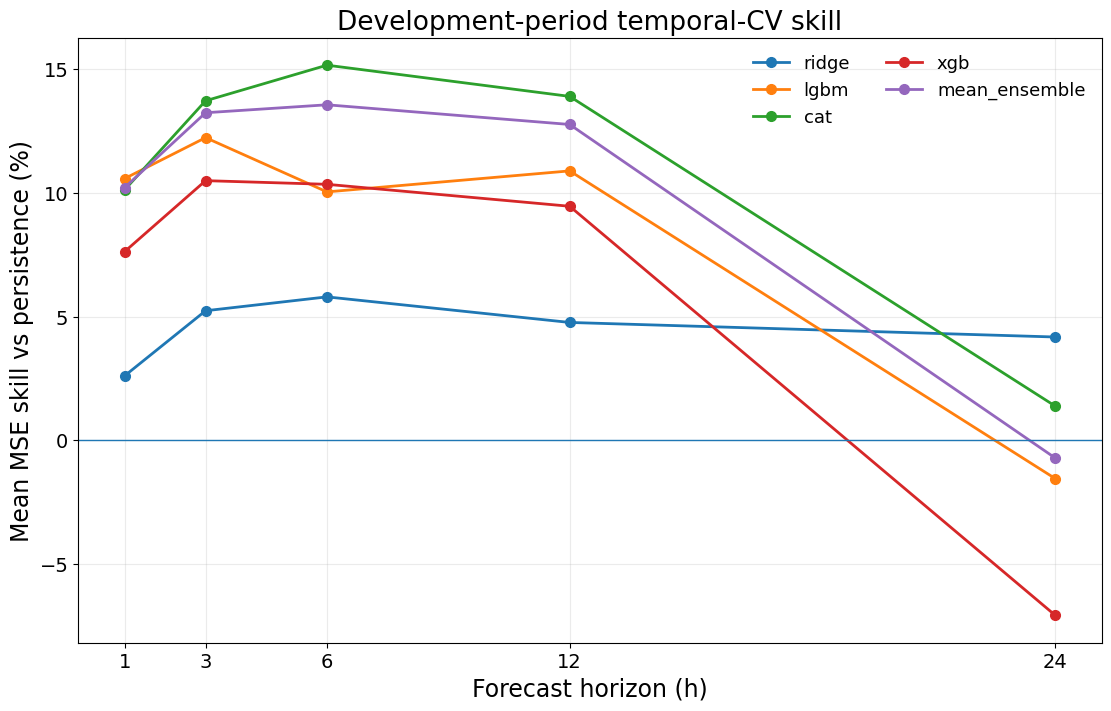

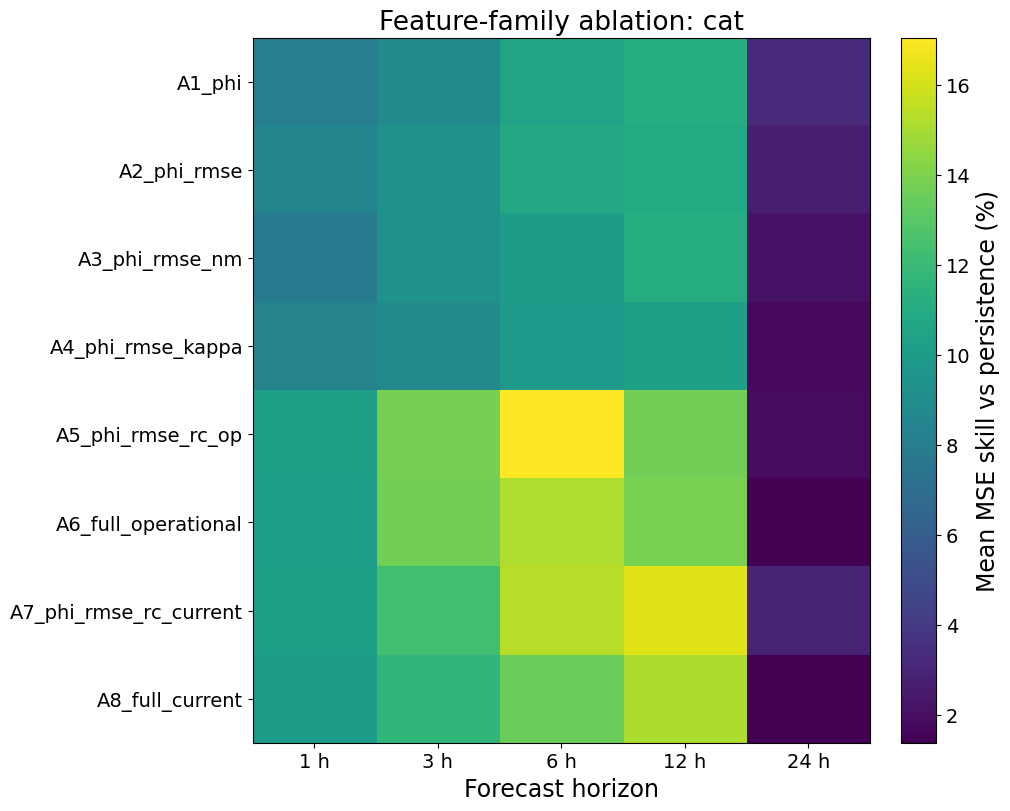

In [15]:

# ============================================================
# CELL 15 — Journal plots: regression CV and ablation
# ============================================================
fig, ax = plt.subplots(figsize=(11,7), constrained_layout=True)
for model_name, fs in [
    ("ridge","A2_phi_rmse"), ("lgbm","A6_full_operational"),
    ("cat","A6_full_operational"), ("xgb","A6_full_operational"),
    ("mean_ensemble","A6_full_operational")
]:
    d = reg_cv_summary[
        (reg_cv_summary["model"] == model_name) & (reg_cv_summary["feature_set"] == fs)
    ].sort_values("horizon_h")
    if not d.empty:
        ax.plot(d["horizon_h"], 100*d["mean_skill"], marker="o", label=model_name)
ax.axhline(0, linewidth=1)
ax.set_xlabel("Forecast horizon (h)")
ax.set_ylabel("Mean MSE skill vs persistence (%)")
ax.set_title("Development-period temporal-CV skill")
ax.set_xticks(REG_HORIZONS)
ax.legend(ncol=2, frameon=False)
ax.grid(alpha=0.25)
save_figure(fig, "Fig03_regression_cv_skill")
plt.show()

ab = reg_cv_summary[
    (reg_cv_summary["model"] == PRIMARY_REG_MODEL)
    & reg_cv_summary["feature_set"].isin(REG_FEATURE_SETS)
]
heat = ab.pivot(index="feature_set", columns="horizon_h", values="mean_skill").reindex(REG_FEATURE_SETS)
fig, ax = plt.subplots(figsize=(10,8), constrained_layout=True)
im = ax.imshow(100*heat.values, aspect="auto")
ax.set_xticks(range(len(heat.columns))); ax.set_xticklabels([f"{h} h" for h in heat.columns])
ax.set_yticks(range(len(heat.index))); ax.set_yticklabels(heat.index)
ax.set_xlabel("Forecast horizon")
ax.set_title(f"Feature-family ablation: {PRIMARY_REG_MODEL}")
cbar = fig.colorbar(im, ax=ax); cbar.set_label("Mean MSE skill vs persistence (%)")
save_figure(fig, "Fig04_regression_feature_ablation")
plt.show()


In [16]:
# ============================================================
# CELL 16 — Rolling-CV rapid-transition classification
# FINAL Q1 VERSION: raw probabilities for unbiased model ranking
# ============================================================
CLS_CV_METRICS_PATH = TABLE_DIR / "classification_cv_fold_metrics.csv"
CLS_OOF_PATH = PRED_DIR / "classification_oof_raw.parquet"
CLS_THRESHOLD_PATH = TABLE_DIR / "classification_fold_event_thresholds.csv"

def run_classification_cv(force=False):
    if RESUME and not force and CLS_CV_METRICS_PATH.exists() and (
        CLS_OOF_PATH.exists() or CLS_OOF_PATH.with_suffix(".pkl").exists()
    ):
        print("Loading cached classification CV results.")
        return (
            pd.read_csv(CLS_CV_METRICS_PATH),
            load_frame(CLS_OOF_PATH),
            pd.read_csv(CLS_THRESHOLD_PATH),
        )

    metric_rows = []
    oof_parts = []
    threshold_rows = []

    for f in FOLDS:
        tr = load_frame(fold_cache_paths(f["fold"])[0])
        va = load_frame(fold_cache_paths(f["fold"])[1])

        for h in CLS_HORIZONS:
            train_all = tr.loc[
                cls_eligible_mask(tr, h, f["train_start"], f["train_end"])
            ].copy()

            val_h = va.loc[
                cls_eligible_mask(va, h, f["val_start"], f["val_end"])
            ].copy()

            event_threshold = float(
                train_all[f"max_abs_excursion_{h}"].quantile(0.95)
            )

            y_val = (
                val_h[f"max_abs_excursion_{h}"].to_numpy(dtype=float)
                > event_threshold
            ).astype(int)

            threshold_rows.append({
                "fold": f["fold"],
                "horizon_h": h,
                "event_threshold_mv": event_threshold,
                "train_event_rate": float(
                    (train_all[f"max_abs_excursion_{h}"] > event_threshold).mean()
                ),
                "val_event_rate": float(y_val.mean()),
            })

            pred_store = {}

            # ----------------------------------------------------------
            # Compact logistic baseline: phi + RMSE only.
            # ----------------------------------------------------------
            baseline = fit_raw_warning_system(
                "logistic_phi_rmse",
                train_all,
                h,
                event_threshold,
            )
            pred_store["logistic_phi_rmse"] = predict_raw_warning_system(
                "logistic_phi_rmse",
                baseline,
                val_h,
            )
            r = {
                "model": "logistic_phi_rmse",
                "feature_set": "C2_phi_rmse",
                "horizon_h": h,
                **classification_metrics(
                    y_val,
                    pred_store["logistic_phi_rmse"],
                    threshold=0.5,
                ),
            }
            r["fold"] = f["fold"]
            metric_rows.append(r)
            del baseline

            # ----------------------------------------------------------
            # Full-feature logistic candidate.
            # This is included in the SAME primary ranking as tree models.
            # ----------------------------------------------------------
            logistic_full = fit_raw_warning_system(
                "logistic_full",
                train_all,
                h,
                event_threshold,
            )
            pred_store["logistic_full"] = predict_raw_warning_system(
                "logistic_full",
                logistic_full,
                val_h,
            )
            r = {
                "model": "logistic_full",
                "feature_set": "C3_full_operational",
                "horizon_h": h,
                **classification_metrics(
                    y_val,
                    pred_store["logistic_full"],
                    threshold=0.5,
                ),
            }
            r["fold"] = f["fold"]
            metric_rows.append(r)
            del logistic_full

            # ----------------------------------------------------------
            # LightGBM feature-family ablation.
            # ----------------------------------------------------------
            for feature_set, cols in CLS_FEATURE_SETS.items():
                print(
                    f"Classification CV | fold={f['fold']} h={h:2d} "
                    f"| lgbm | {feature_set}"
                )

                y_train = (
                    train_all[f"max_abs_excursion_{h}"].to_numpy(dtype=float)
                    > event_threshold
                ).astype(int)

                model = make_classifier("lgbm", y_train)
                model.fit(train_all[cols], y_train)
                prob = model.predict_proba(val_h[cols])[:, 1]

                r = {
                    "model": "lgbm",
                    "feature_set": feature_set,
                    "horizon_h": h,
                    **classification_metrics(y_val, prob, threshold=0.5),
                }
                r["fold"] = f["fold"]
                metric_rows.append(r)

                if feature_set == "C3_full_operational":
                    pred_store["lgbm"] = prob

                del model
                gc.collect()

            # ----------------------------------------------------------
            # XGBoost and CatBoost on full operational predictors.
            # ----------------------------------------------------------
            for model_name in ["xgb", "cat"]:
                print(
                    f"Classification CV | fold={f['fold']} h={h:2d} "
                    f"| {model_name} | C3_full_operational"
                )

                fitted = fit_raw_warning_system(
                    model_name,
                    train_all,
                    h,
                    event_threshold,
                )
                prob = predict_raw_warning_system(
                    model_name,
                    fitted,
                    val_h,
                )
                pred_store[model_name] = prob

                r = {
                    "model": model_name,
                    "feature_set": "C3_full_operational",
                    "horizon_h": h,
                    **classification_metrics(y_val, prob, threshold=0.5),
                }
                r["fold"] = f["fold"]
                metric_rows.append(r)

                del fitted
                gc.collect()

            # ----------------------------------------------------------
            # Simple mean of the three tree probabilities.
            # ----------------------------------------------------------
            ensemble_prob = np.mean(
                np.column_stack([
                    pred_store["lgbm"],
                    pred_store["xgb"],
                    pred_store["cat"],
                ]),
                axis=1,
            )

            pred_store["mean_probability_ensemble"] = ensemble_prob

            r = {
                "model": "mean_probability_ensemble",
                "feature_set": "C3_full_operational",
                "horizon_h": h,
                **classification_metrics(y_val, ensemble_prob, threshold=0.5),
            }
            r["fold"] = f["fold"]
            metric_rows.append(r)

            # ----------------------------------------------------------
            # Honest fold-wise OOF file for discrimination diagnostics.
            # ----------------------------------------------------------
            p = pd.DataFrame(index=val_h.index)
            p["fold"] = f["fold"]
            p["horizon_h"] = h
            p["event_threshold_mv"] = event_threshold
            p["y_event"] = y_val
            p["max_abs_excursion"] = val_h[f"max_abs_excursion_{h}"].astype(float)
            p["prob_logistic_phi_rmse"] = pred_store["logistic_phi_rmse"]
            p["prob_logistic_full"] = pred_store["logistic_full"]
            p["prob_lgbm"] = pred_store["lgbm"]
            p["prob_xgb"] = pred_store["xgb"]
            p["prob_cat"] = pred_store["cat"]
            p["prob_mean_probability_ensemble"] = pred_store["mean_probability_ensemble"]
            oof_parts.append(p)

            gc.collect()

        del tr, va
        gc.collect()

    metrics = pd.DataFrame(metric_rows)
    oof = pd.concat(oof_parts).sort_index()
    thresholds = pd.DataFrame(threshold_rows)

    metrics.to_csv(CLS_CV_METRICS_PATH, index=False)
    save_frame(oof, CLS_OOF_PATH)
    thresholds.to_csv(CLS_THRESHOLD_PATH, index=False)

    return metrics, oof, thresholds


# FORCE=True prevents old calibrated-CV cache files from being reused.
cls_cv_metrics, cls_oof, cls_fold_thresholds = run_classification_cv(force=True)
print("Classification CV rows:", len(cls_cv_metrics))


Classification CV | fold=1 h= 3 | lgbm | C1_phi
Classification CV | fold=1 h= 3 | lgbm | C2_phi_rmse
Classification CV | fold=1 h= 3 | lgbm | C3_full_operational
Classification CV | fold=1 h= 3 | xgb | C3_full_operational
Classification CV | fold=1 h= 3 | cat | C3_full_operational
Classification CV | fold=1 h= 6 | lgbm | C1_phi
Classification CV | fold=1 h= 6 | lgbm | C2_phi_rmse
Classification CV | fold=1 h= 6 | lgbm | C3_full_operational
Classification CV | fold=1 h= 6 | xgb | C3_full_operational
Classification CV | fold=1 h= 6 | cat | C3_full_operational
Classification CV | fold=1 h=12 | lgbm | C1_phi
Classification CV | fold=1 h=12 | lgbm | C2_phi_rmse
Classification CV | fold=1 h=12 | lgbm | C3_full_operational
Classification CV | fold=1 h=12 | xgb | C3_full_operational
Classification CV | fold=1 h=12 | cat | C3_full_operational
Classification CV | fold=1 h=24 | lgbm | C1_phi
Classification CV | fold=1 h=24 | lgbm | C2_phi_rmse
Classification CV | fold=1 h=24 | lgbm | C3_full_oper

In [17]:
# ============================================================
# CELL 17 — Classification summaries and FAIR primary warning-model selection
# ============================================================
cls_cv_summary = (
    cls_cv_metrics
    .groupby(["model", "feature_set", "horizon_h"])
    .agg(
        mean_pr_auc=("pr_auc", "mean"),
        std_pr_auc=("pr_auc", "std"),
        mean_roc_auc=("roc_auc", "mean"),
        mean_brier_raw=("brier", "mean"),
        mean_ece10_raw=("ece10", "mean"),
        folds=("fold", "nunique"),
    )
    .reset_index()
)
cls_cv_summary.to_csv(
    TABLE_DIR / "classification_cv_summary.csv",
    index=False,
)

# ------------------------------------------------------------
# Primary candidates are compared on the SAME development-CV
# primary metric: PR-AUC.
#
# logistic_full is now included fairly in this ranking.
# ------------------------------------------------------------
candidate_rows = cls_cv_summary[
    (
        (
            cls_cv_summary["model"].isin([
                "logistic_full",
                "lgbm",
                "xgb",
                "cat",
                "mean_probability_ensemble",
            ])
        )
        & (cls_cv_summary["feature_set"] == "C3_full_operational")
    )
].copy()

cls_rank = (
    candidate_rows
    .groupby(["model", "feature_set"])
    .agg(
        mean_pr_auc_all_horizons=("mean_pr_auc", "mean"),
        min_pr_auc_any_horizon=("mean_pr_auc", "min"),
        mean_roc_auc_all_horizons=("mean_roc_auc", "mean"),
    )
    .reset_index()
    .sort_values(
        ["mean_pr_auc_all_horizons", "min_pr_auc_any_horizon"],
        ascending=False,
    )
)

PRIMARY_CLS_MODEL = str(cls_rank.iloc[0]["model"])
PRIMARY_CLS_FEATURE_SET = "C3_full_operational"

# Horizon-specific winners are reported for transparency only.
# The main paper uses one uniform system selected by mean CV PR-AUC.
horizon_winners = (
    candidate_rows
    .sort_values(
        ["horizon_h", "mean_pr_auc", "mean_roc_auc"],
        ascending=[True, False, False],
    )
    .groupby("horizon_h", as_index=False)
    .first()
    [["horizon_h", "model", "feature_set", "mean_pr_auc", "mean_roc_auc"]]
)

cls_rank.to_csv(
    TABLE_DIR / "classification_primary_model_ranking.csv",
    index=False,
)
horizon_winners.to_csv(
    TABLE_DIR / "classification_horizon_winners_development.csv",
    index=False,
)

print("Primary warning system chosen ONLY from 1964–2020 development CV:")
print("  system =", PRIMARY_CLS_MODEL)
print("  primary selection metric = mean PR-AUC across horizons")
display(cls_rank)
display(horizon_winners)


Primary warning system chosen ONLY from 1964–2020 development CV:
  system = logistic_full
  primary selection metric = mean PR-AUC across horizons


,model,feature_set,mean_pr_auc_all_horizons,min_pr_auc_any_horizon,mean_roc_auc_all_horizons
2,logistic_full,C3_full_operational,0.271748,0.264778,0.809312
1,lgbm,C3_full_operational,0.271731,0.248370,0.809475
3,mean_probability_ensemble,C3_full_operational,0.266162,0.238982,0.812764
0,cat,C3_full_operational,0.266144,0.244761,0.810692
4,xgb,C3_full_operational,0.252191,0.219236,0.801494


,horizon_h,model,feature_set,mean_pr_auc,mean_roc_auc
0,3,lgbm,C3_full_operational,0.279905,0.843974
1,6,lgbm,C3_full_operational,0.290829,0.836021
2,12,logistic_full,C3_full_operational,0.273245,0.799189
3,24,logistic_full,C3_full_operational,0.270457,0.774511


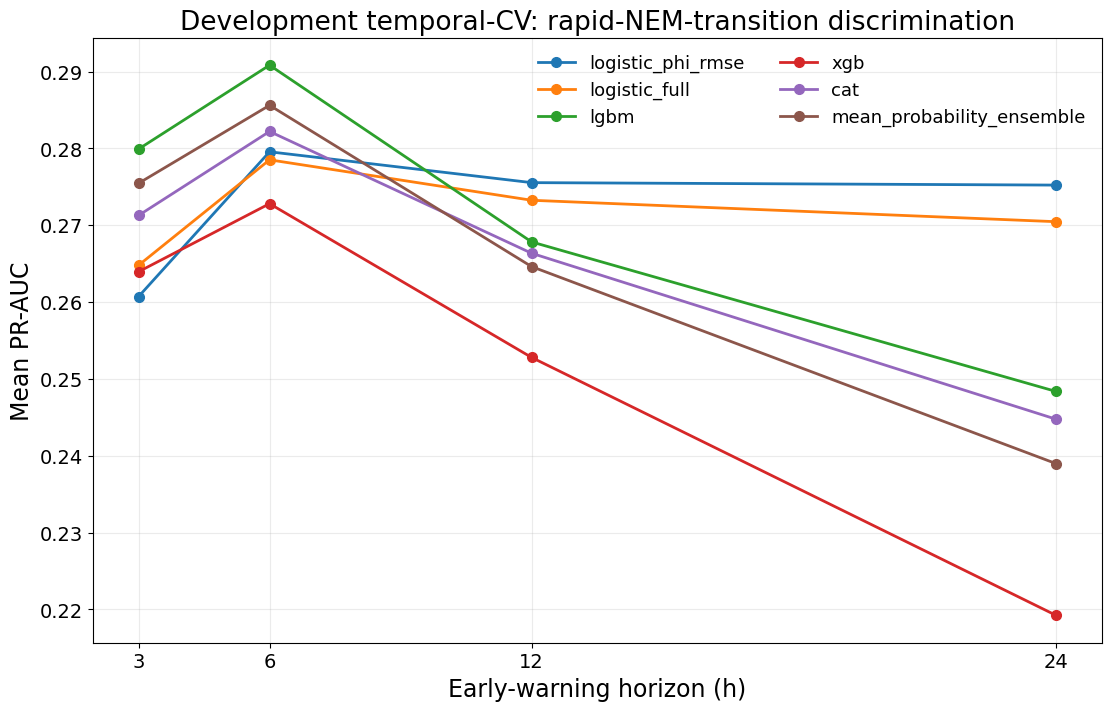

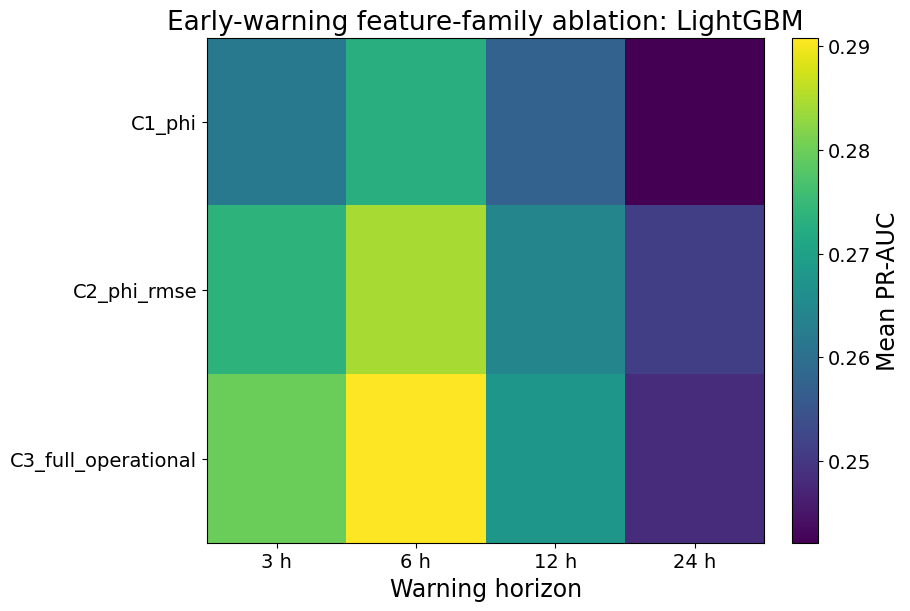

In [18]:
# ============================================================
# CELL 18 — Journal plots: warning PR-AUC and feature ablation
# ============================================================
fig, ax = plt.subplots(figsize=(11, 7), constrained_layout=True)

for model_name, fs in [
    ("logistic_phi_rmse", "C2_phi_rmse"),
    ("logistic_full", "C3_full_operational"),
    ("lgbm", "C3_full_operational"),
    ("xgb", "C3_full_operational"),
    ("cat", "C3_full_operational"),
    ("mean_probability_ensemble", "C3_full_operational"),
]:
    d = cls_cv_summary[
        (cls_cv_summary["model"] == model_name)
        & (cls_cv_summary["feature_set"] == fs)
    ].sort_values("horizon_h")

    if not d.empty:
        ax.plot(
            d["horizon_h"],
            d["mean_pr_auc"],
            marker="o",
            label=model_name,
        )

ax.set_xlabel("Early-warning horizon (h)")
ax.set_ylabel("Mean PR-AUC")
ax.set_title("Development temporal-CV: rapid-NEM-transition discrimination")
ax.set_xticks(CLS_HORIZONS)
ax.legend(ncol=2, frameon=False)
ax.grid(alpha=0.25)
save_figure(fig, "Fig05_transition_warning_pr_auc_cv")
plt.show()

# LightGBM warning feature-family ablation.
cab = cls_cv_summary[
    (cls_cv_summary["model"] == "lgbm")
    & cls_cv_summary["feature_set"].isin(CLS_FEATURE_SETS.keys())
].copy()

cheat = (
    cab
    .pivot(index="feature_set", columns="horizon_h", values="mean_pr_auc")
    .reindex(list(CLS_FEATURE_SETS.keys()))
)

fig, ax = plt.subplots(figsize=(9, 6), constrained_layout=True)
im = ax.imshow(cheat.values, aspect="auto")
ax.set_xticks(range(len(cheat.columns)))
ax.set_xticklabels([f"{h} h" for h in cheat.columns])
ax.set_yticks(range(len(cheat.index)))
ax.set_yticklabels(cheat.index)
ax.set_xlabel("Warning horizon")
ax.set_title("Early-warning feature-family ablation: LightGBM")
cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Mean PR-AUC")
save_figure(fig, "Fig06_transition_warning_feature_ablation")
plt.show()


In [19]:

# ============================================================
# CELL 19 — Build development + 2021–2025 confirmation features
# ============================================================
FINAL_FEATURE_PATH = CACHE_DIR / "features_train1964_2020_confirm2021_2025.parquet"
if RESUME and (FINAL_FEATURE_PATH.exists() or FINAL_FEATURE_PATH.with_suffix(".pkl").exists()):
    final_features = load_frame(FINAL_FEATURE_PATH)
else:
    final_features, final_nm_base, final_kap_base = build_feature_frame(
        master, MODEL_START, DEV_END, MODEL_START, CONFIRM_END
    )
    save_frame(final_features, FINAL_FEATURE_PATH)
    pd.DataFrame({
        "station": STATIONS,
        "nm_training_median_1964_2020": [final_nm_base[f"nm_{s}"] for s in STATIONS],
        "kappa_training_median_1964_2020": [final_kap_base[f"kap_{s}"] for s in STATIONS],
    }).to_csv(TABLE_DIR / "final_station_normalization_1964_2020.csv", index=False)
print(final_features.shape)


(543504, 73)


In [20]:

# ============================================================
# CELL 20 — Final continuous models and 2021–2025 confirmation
# ============================================================
final_reg_models = {}
final_reg_predictions, reg_confirm_rows = [], []
final_stackers = {}

for h in REG_HORIZONS:
    d = reg_oof[reg_oof["horizon_h"] == h].dropna(subset=STACK_COLS + ["y_delta"])
    meta = Ridge(alpha=1.0).fit(d[STACK_COLS], d["y_delta"])
    final_stackers[h] = meta
    joblib.dump(meta, MODEL_DIR / f"reg_stack_meta_h{h}.joblib")

for h in REG_HORIZONS:
    dev = final_features.loc[reg_eligible_mask(final_features, h, MODEL_START, DEV_END)]
    test = final_features.loc[reg_eligible_mask(final_features, h, CONFIRM_START, CONFIRM_END)]

    p = pd.DataFrame(index=test.index)
    p["horizon_h"] = h; p["phi_t"] = test["phi_t"].astype(float)
    p["y_delta"] = test[f"dphi_{h}"].astype(float)
    p["pred_persistence"] = 0.0
    p["pred_seasonal24"] = test[f"seasonal24_dphi_{h}"].astype(float)

    reg_confirm_rows.append(reg_metric_row("persistence","baseline",h,test,p["pred_persistence"]))
    reg_confirm_rows.append(reg_metric_row("seasonal24","baseline",h,test,p["pred_seasonal24"]))

    cols_primary = REG_FEATURE_SETS[PRIMARY_REG_FEATURE_SET]
    primary = make_regressor(PRIMARY_REG_MODEL)
    primary.fit(dev[cols_primary], dev[f"dphi_{h}"])
    p["pred_primary_single"] = primary.predict(test[cols_primary])
    final_reg_models[("primary",h)] = primary
    joblib.dump(primary, MODEL_DIR / f"reg_primary_{PRIMARY_REG_MODEL}_h{h}.joblib")
    reg_confirm_rows.append(reg_metric_row(PRIMARY_REG_MODEL,PRIMARY_REG_FEATURE_SET,h,test,p["pred_primary_single"]))

    base = {}
    for model_name in ["lgbm","xgb","cat"]:
        model = make_regressor(model_name)
        model.fit(dev[FULL_OPERATIONAL], dev[f"dphi_{h}"])
        base[model_name] = model.predict(test[FULL_OPERATIONAL])
        p[f"pred_{model_name}_fullop"] = base[model_name]
        final_reg_models[(model_name,h)] = model
        joblib.dump(model, MODEL_DIR / f"reg_fullop_{model_name}_h{h}.joblib")
        reg_confirm_rows.append(reg_metric_row(model_name,"A6_full_operational",h,test,base[model_name]))

    p["pred_mean_ensemble"] = np.mean(np.column_stack([base["lgbm"],base["xgb"],base["cat"]]),axis=1)
    reg_confirm_rows.append(reg_metric_row("mean_ensemble","A6_full_operational",h,test,p["pred_mean_ensemble"]))

    stack_X = p[["pred_lgbm_fullop","pred_xgb_fullop","pred_cat_fullop"]].copy()
    stack_X.columns = STACK_COLS
    p["pred_stack"] = final_stackers[h].predict(stack_X)
    reg_confirm_rows.append(reg_metric_row("stack","A6_full_operational",h,test,p["pred_stack"]))
    final_reg_predictions.append(p)
    gc.collect()

reg_confirm_pred = pd.concat(final_reg_predictions).sort_index()
reg_confirm_metrics = pd.DataFrame(reg_confirm_rows)
save_frame(reg_confirm_pred, PRED_DIR / "regression_confirmation_2021_2025.parquet")
reg_confirm_metrics.to_csv(TABLE_DIR / "regression_confirmation_2021_2025.csv", index=False)
display(reg_confirm_metrics)


,model,feature_set,horizon_h,n,dphi_mae,dphi_rmse,phi_mae,phi_rmse,phi_r2,skill_mse_vs_persistence,direction_accuracy
0,persistence,baseline,1,43757,3.007505,4.359773,3.007505,4.359773,0.999450,0.000000,0.000000
1,seasonal24,baseline,1,43697,15.243234,26.305288,15.243234,26.305288,0.979868,-35.548806,0.503844
2,cat,A5_phi_rmse_rc_op,1,43757,2.885515,4.058243,2.885515,4.058243,0.999523,0.133541,0.590801
3,lgbm,A6_full_operational,1,43757,2.887383,4.063950,2.887383,4.063950,0.999522,0.131102,0.586361
4,xgb,A6_full_operational,1,43757,2.890264,4.108344,2.890264,4.108344,0.999512,0.112015,0.590015
5,cat,A6_full_operational,1,43757,2.888313,4.064966,2.888313,4.064966,0.999522,0.130667,0.585089
6,mean_ensemble,A6_full_operational,1,43757,2.883157,4.064420,2.883157,4.064420,0.999522,0.130901,0.589090
7,stack,A6_full_operational,1,43757,2.889094,4.066336,2.889094,4.066336,0.999522,0.130081,0.582221
8,persistence,baseline,3,43747,5.454504,8.667553,5.454504,8.667553,0.997825,0.000000,0.000000
9,seasonal24,baseline,3,43689,15.231406,26.239816,15.231406,26.239816,0.979963,-8.211376,0.520004


In [21]:
# ============================================================
# CELL 21 — Final warning systems and 2021–2025 confirmation
# FINAL Q1 VERSION: temporal-OOF calibration + frozen alert threshold
# ============================================================
final_cls_models = {}
final_cls_calibrators = {}
cls_confirm_parts = []
cls_confirm_rows = []
threshold_rows = []
calibration_audit_rows = []
calibration_oof_parts = []

ALERT_THRESHOLDS = {}

for h in CLS_HORIZONS:
    dev = final_features.loc[
        cls_eligible_mask(final_features, h, MODEL_START, DEV_END)
    ].copy()

    test = final_features.loc[
        cls_eligible_mask(final_features, h, CONFIRM_START, CONFIRM_END)
    ].copy()

    # ------------------------------------------------------------
    # Fixed NEM-native event definition from ALL development data.
    # Confirmation data never affect this threshold.
    # ------------------------------------------------------------
    event_threshold = float(
        dev[f"max_abs_excursion_{h}"].quantile(0.95)
    )

    y_test = (
        test[f"max_abs_excursion_{h}"].to_numpy(dtype=float)
        > event_threshold
    ).astype(int)

    threshold_rows.append({
        "horizon_h": h,
        "event_threshold_mv": event_threshold,
        "development_event_rate": float(
            (dev[f"max_abs_excursion_{h}"] > event_threshold).mean()
        ),
        "confirmation_event_rate": float(y_test.mean()),
    })

    p = pd.DataFrame(index=test.index)
    p["horizon_h"] = h
    p["y_event"] = y_test
    p["event_threshold_mv"] = event_threshold
    p["max_abs_excursion"] = test[f"max_abs_excursion_{h}"].astype(float)

    # ------------------------------------------------------------
    # Fit all fair primary candidates on 1964–2020 and obtain RAW
    # confirmation probabilities. PR-AUC/ROC-AUC compare discrimination.
    # ------------------------------------------------------------
    fitted_individual = {}

    # Logistic full
    fitted_individual["logistic_full"] = fit_raw_warning_system(
        "logistic_full", dev, h, event_threshold
    )
    p["prob_raw_logistic_full"] = predict_raw_warning_system(
        "logistic_full",
        fitted_individual["logistic_full"],
        test,
    )

    # Compact baseline retained separately
    compact_baseline = fit_raw_warning_system(
        "logistic_phi_rmse", dev, h, event_threshold
    )
    p["prob_raw_logistic_phi_rmse"] = predict_raw_warning_system(
        "logistic_phi_rmse",
        compact_baseline,
        test,
    )

    for model_name in ["lgbm", "xgb", "cat"]:
        fitted_individual[model_name] = fit_raw_warning_system(
            model_name, dev, h, event_threshold
        )
        p[f"prob_raw_{model_name}"] = predict_raw_warning_system(
            model_name,
            fitted_individual[model_name],
            test,
        )

    p["prob_raw_mean_probability_ensemble"] = np.mean(
        np.column_stack([
            p["prob_raw_lgbm"],
            p["prob_raw_xgb"],
            p["prob_raw_cat"],
        ]),
        axis=1,
    )

    # Save fitted full-development individual models.
    joblib.dump(
        compact_baseline,
        MODEL_DIR / f"cls_logistic_phi_rmse_h{h}.joblib",
    )
    for model_name, fitted in fitted_individual.items():
        joblib.dump(
            fitted,
            MODEL_DIR / f"cls_{model_name}_h{h}.joblib",
        )
        final_cls_models[(model_name, h)] = fitted

    # Raw discrimination rows.
    for model_name, prob_col, fs in [
        ("logistic_phi_rmse", "prob_raw_logistic_phi_rmse", "C2_phi_rmse"),
        ("logistic_full", "prob_raw_logistic_full", "C3_full_operational"),
        ("lgbm", "prob_raw_lgbm", "C3_full_operational"),
        ("xgb", "prob_raw_xgb", "C3_full_operational"),
        ("cat", "prob_raw_cat", "C3_full_operational"),
        (
            "mean_probability_ensemble",
            "prob_raw_mean_probability_ensemble",
            "C3_full_operational",
        ),
    ]:
        row = {
            "model": model_name,
            "feature_set": fs,
            "probability_status": "raw_discrimination_score",
            "horizon_h": h,
            **classification_metrics(
                y_test,
                p[prob_col],
                threshold=0.5,
            ),
        }
        cls_confirm_rows.append(row)

    # ------------------------------------------------------------
    # Temporal-OOF calibration of the development-selected PRIMARY
    # system. This replaces the unstable tiny recent calibration block.
    # ------------------------------------------------------------
    calibrator, alert_thr, cal_oof, cal_audit = temporal_oof_calibration(
        system_name=PRIMARY_CLS_MODEL,
        feature_frame=final_features.loc[MODEL_START:DEV_END],
        h=h,
        event_threshold=event_threshold,
        folds=FOLDS,
        audit_label="development_1964_2020",
    )

    ALERT_THRESHOLDS[h] = float(alert_thr)
    final_cls_calibrators[(PRIMARY_CLS_MODEL, h)] = calibrator

    joblib.dump(
        calibrator,
        MODEL_DIR / f"cls_primary_{PRIMARY_CLS_MODEL}_h{h}_oof_platt.joblib",
    )

    cal_oof = cal_oof.copy()
    cal_oof["horizon_h"] = h
    calibration_oof_parts.append(cal_oof)
    calibration_audit_rows.append(cal_audit)

    # Raw primary probability from final 1964–2020 model.
    if PRIMARY_CLS_MODEL == "mean_probability_ensemble":
        raw_primary = p["prob_raw_mean_probability_ensemble"].to_numpy(dtype=float)
    else:
        raw_primary = p[f"prob_raw_{PRIMARY_CLS_MODEL}"].to_numpy(dtype=float)

    p["prob_primary_warning"] = calibrator.predict(raw_primary)
    p["alert_threshold"] = float(alert_thr)
    p["alert_primary"] = (
        p["prob_primary_warning"].to_numpy(dtype=float) >= float(alert_thr)
    ).astype(int)

    cls_confirm_rows.append({
        "model": PRIMARY_CLS_MODEL,
        "feature_set": PRIMARY_CLS_FEATURE_SET,
        "probability_status": "temporal_oof_calibrated_primary",
        "horizon_h": h,
        **classification_metrics(
            y_test,
            p["prob_primary_warning"],
            threshold=float(alert_thr),
        ),
    })

    cls_confirm_parts.append(p)

    del dev, test, compact_baseline, fitted_individual
    gc.collect()


cls_confirm_pred = pd.concat(cls_confirm_parts).sort_index()
cls_confirm_metrics = pd.DataFrame(cls_confirm_rows)
final_event_thresholds = pd.DataFrame(threshold_rows)
classification_calibration_audit = pd.DataFrame(calibration_audit_rows)
classification_calibration_oof = pd.concat(calibration_oof_parts).sort_index()

save_frame(
    cls_confirm_pred,
    PRED_DIR / "classification_confirmation_2021_2025.parquet",
)
save_frame(
    classification_calibration_oof,
    PRED_DIR / "classification_primary_temporal_oof_calibration.parquet",
)

cls_confirm_metrics.to_csv(
    TABLE_DIR / "classification_confirmation_2021_2025.csv",
    index=False,
)
final_event_thresholds.to_csv(
    TABLE_DIR / "classification_final_event_thresholds_1964_2020.csv",
    index=False,
)
classification_calibration_audit.to_csv(
    TABLE_DIR / "classification_temporal_oof_calibration_audit.csv",
    index=False,
)

pd.DataFrame({
    "horizon_h": list(ALERT_THRESHOLDS.keys()),
    "alert_probability_threshold": list(ALERT_THRESHOLDS.values()),
}).to_csv(
    TABLE_DIR / "classification_alert_thresholds_development.csv",
    index=False,
)

print("Primary classification system:", PRIMARY_CLS_MODEL)
display(final_event_thresholds)
display(classification_calibration_audit)
display(
    cls_confirm_metrics[
        cls_confirm_metrics["probability_status"].isin([
            "raw_discrimination_score",
            "temporal_oof_calibrated_primary",
        ])
    ]
)


Primary classification system: logistic_full


,horizon_h,event_threshold_mv,development_event_rate,confirmation_event_rate
0,3,13.500000,0.049897,0.062747
1,6,20.600000,0.049442,0.069148
2,12,31.799999,0.049896,0.065512
3,24,48.900002,0.049998,0.058636


,audit_label,system,horizon_h,event_threshold_mv,oof_n,oof_positive,oof_negative,oof_event_rate,oof_raw_pr_auc,oof_calibrated_pr_auc,oof_calibrated_brier,oof_calibrated_ece10,selected_alert_threshold
0,development_1964_2020,logistic_full,3,13.500000,262347,10676,251671,0.040694,0.303461,0.303061,0.033437,0.005120,0.127362
1,development_1964_2020,logistic_full,6,20.600000,262272,11113,251159,0.042372,0.324233,0.323431,0.034165,0.005909,0.123948
2,development_1964_2020,logistic_full,12,31.799999,262122,11251,250871,0.042923,0.330194,0.329726,0.034413,0.005726,0.128133
3,development_1964_2020,logistic_full,24,48.900002,261822,11178,250644,0.042693,0.339300,0.339219,0.033828,0.004573,0.157883


,model,feature_set,probability_status,horizon_h,n,event_rate,decision_threshold,pr_auc,roc_auc,precision,recall,specificity,f1,brier,ece10
0,logistic_phi_rmse,C2_phi_rmse,raw_discrimination_score,3,43747,0.062747,0.500000,0.263445,0.757780,0.144520,0.669217,0.734793,0.237707,0.206940,0.369659
1,logistic_full,C3_full_operational,raw_discrimination_score,3,43747,0.062747,0.500000,0.270612,0.761650,0.199710,0.502368,0.865226,0.285803,0.138489,0.263049
2,lgbm,C3_full_operational,raw_discrimination_score,3,43747,0.062747,0.500000,0.291086,0.781189,0.157357,0.656831,0.764524,0.253890,0.167116,0.280261
3,xgb,C3_full_operational,raw_discrimination_score,3,43747,0.062747,0.500000,0.290484,0.777223,0.180151,0.590528,0.820082,0.276079,0.140799,0.242018
4,cat,C3_full_operational,raw_discrimination_score,3,43747,0.062747,0.500000,0.292857,0.780293,0.162421,0.655009,0.773865,0.260297,0.166657,0.289137
5,mean_probability_ensemble,C3_full_operational,raw_discrimination_score,3,43747,0.062747,0.500000,0.296492,0.782818,0.169901,0.637887,0.791352,0.268332,0.155925,0.270472
6,logistic_full,C3_full_operational,temporal_oof_calibrated_primary,3,43747,0.062747,0.127362,0.270612,0.761650,0.364650,0.250273,0.970806,0.296824,0.053589,0.021035
7,logistic_phi_rmse,C2_phi_rmse,raw_discrimination_score,6,43732,0.069148,0.500000,0.279435,0.746587,0.152409,0.647487,0.732510,0.246739,0.202852,0.354284
8,logistic_full,C3_full_operational,raw_discrimination_score,6,43732,0.069148,0.500000,0.285357,0.751831,0.175586,0.594577,0.792621,0.271110,0.173181,0.309658
9,lgbm,C3_full_operational,raw_discrimination_score,6,43732,0.069148,0.500000,0.309000,0.769154,0.154206,0.675926,0.724600,0.251121,0.185910,0.301650


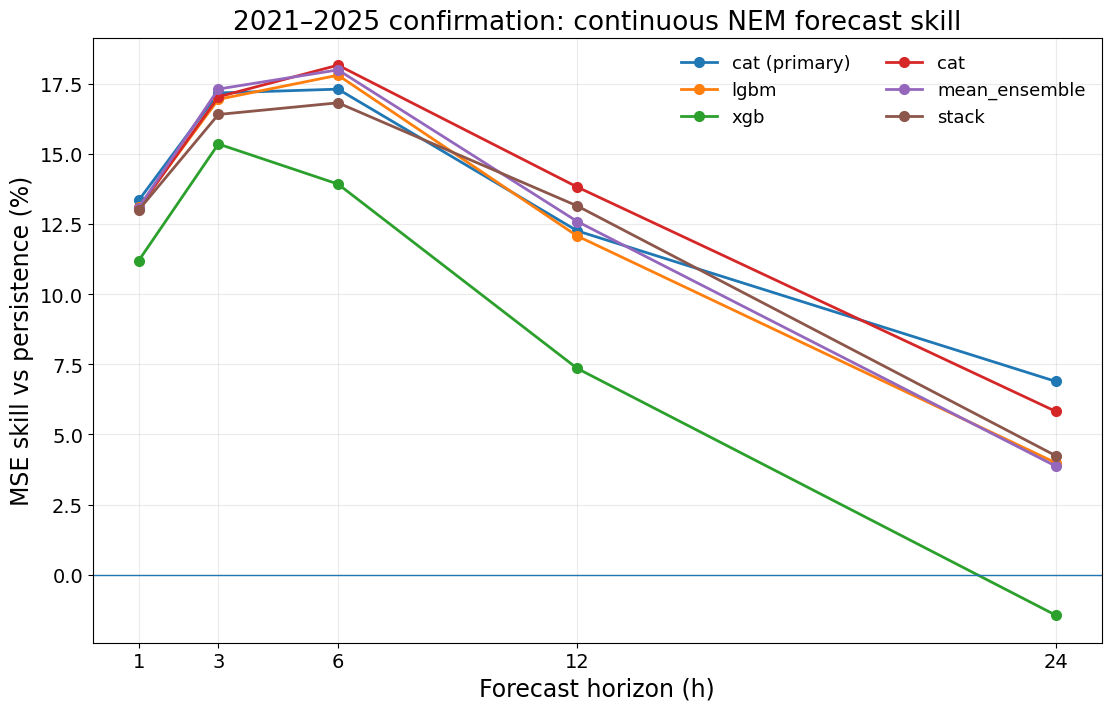

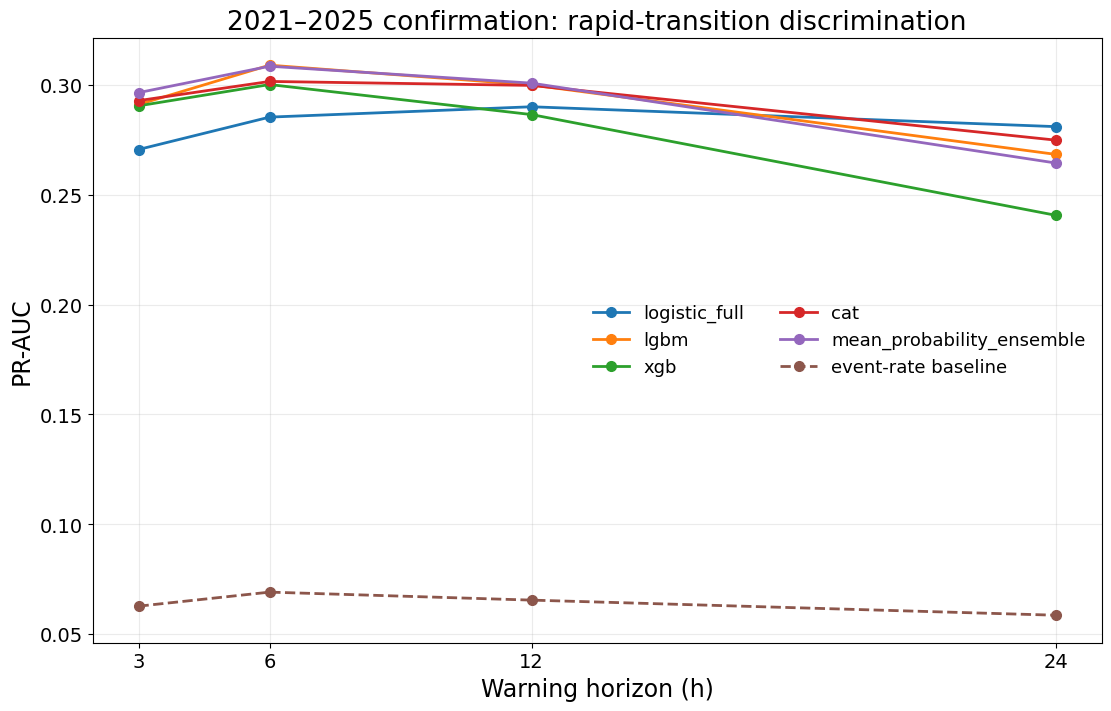

In [22]:
# ============================================================
# CELL 22 — Journal plots: confirmation skill and warning discrimination
# ============================================================
fig, ax = plt.subplots(figsize=(11, 7), constrained_layout=True)

for model_name, fs in [
    (PRIMARY_REG_MODEL, PRIMARY_REG_FEATURE_SET),
    ("lgbm", "A6_full_operational"),
    ("xgb", "A6_full_operational"),
    ("cat", "A6_full_operational"),
    ("mean_ensemble", "A6_full_operational"),
    ("stack", "A6_full_operational"),
]:
    d = reg_confirm_metrics[
        (reg_confirm_metrics["model"] == model_name)
        & (reg_confirm_metrics["feature_set"] == fs)
    ].sort_values("horizon_h")

    if not d.empty:
        label = (
            f"{model_name} (primary)"
            if model_name == PRIMARY_REG_MODEL and fs == PRIMARY_REG_FEATURE_SET
            else model_name
        )
        ax.plot(
            d["horizon_h"],
            100 * d["skill_mse_vs_persistence"],
            marker="o",
            label=label,
        )

ax.axhline(0, linewidth=1)
ax.set_xlabel("Forecast horizon (h)")
ax.set_ylabel("MSE skill vs persistence (%)")
ax.set_title("2021–2025 confirmation: continuous NEM forecast skill")
ax.set_xticks(REG_HORIZONS)
ax.legend(ncol=2, frameon=False)
ax.grid(alpha=0.25)
save_figure(fig, "Fig07_confirmation_regression_skill")
plt.show()


# ------------------------------------------------------------
# Confirmation discrimination.
# PR-AUC is invariant to monotonic Platt scaling, so candidate
# comparison uses raw probabilities and the calibrated primary
# is shown separately for operational interpretation.
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 7), constrained_layout=True)

for model_name in [
    "logistic_full",
    "lgbm",
    "xgb",
    "cat",
    "mean_probability_ensemble",
]:
    d = cls_confirm_metrics[
        (cls_confirm_metrics["model"] == model_name)
        & (cls_confirm_metrics["probability_status"] == "raw_discrimination_score")
        & (cls_confirm_metrics["feature_set"] == "C3_full_operational")
    ].sort_values("horizon_h")

    if not d.empty:
        ax.plot(
            d["horizon_h"],
            d["pr_auc"],
            marker="o",
            label=model_name,
        )

baseline = (
    final_event_thresholds
    .set_index("horizon_h")["confirmation_event_rate"]
    .sort_index()
)

ax.plot(
    baseline.index,
    baseline.values,
    marker="o",
    linestyle="--",
    label="event-rate baseline",
)

ax.set_xlabel("Warning horizon (h)")
ax.set_ylabel("PR-AUC")
ax.set_title("2021–2025 confirmation: rapid-transition discrimination")
ax.set_xticks(CLS_HORIZONS)
ax.legend(ncol=2, frameon=False)
ax.grid(alpha=0.25)
save_figure(fig, "Fig08_confirmation_transition_pr_auc")
plt.show()


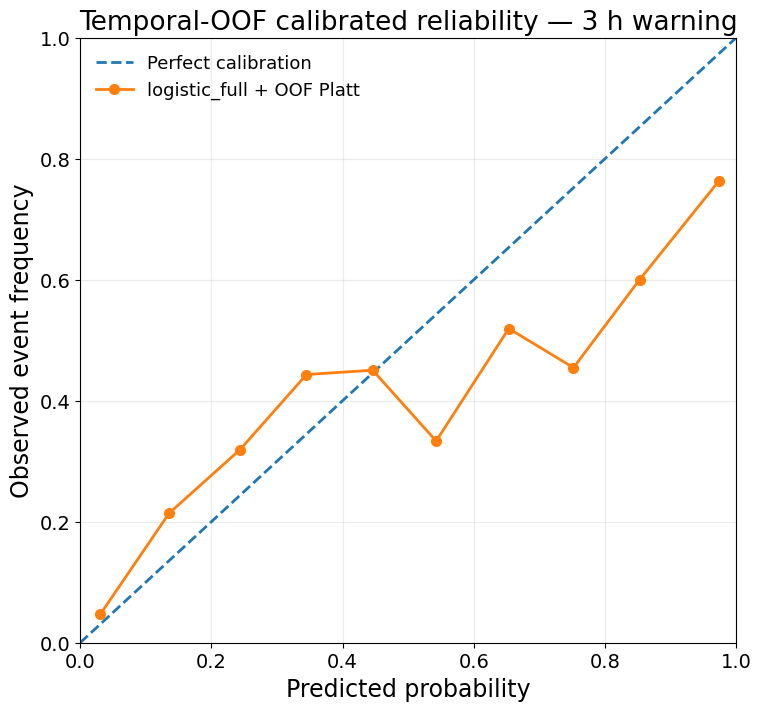

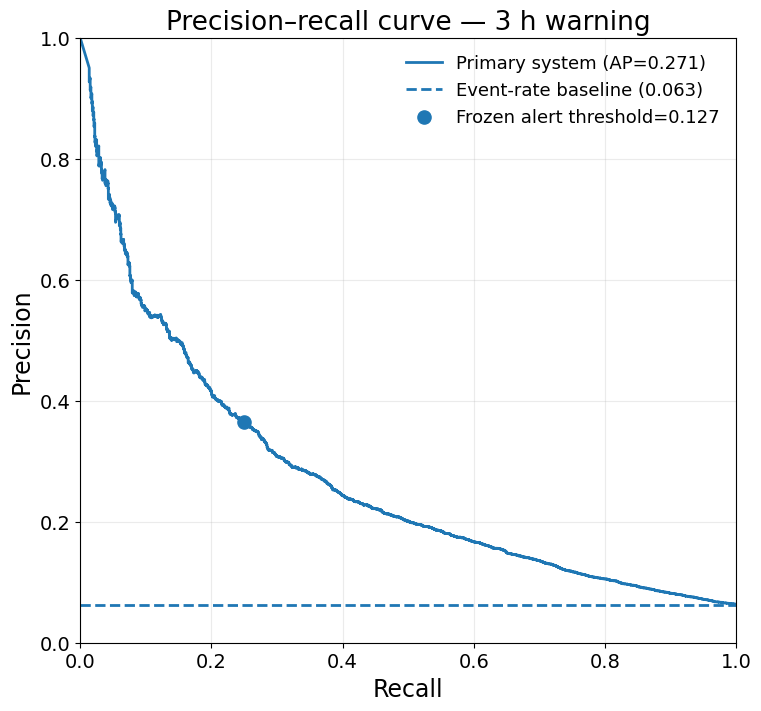

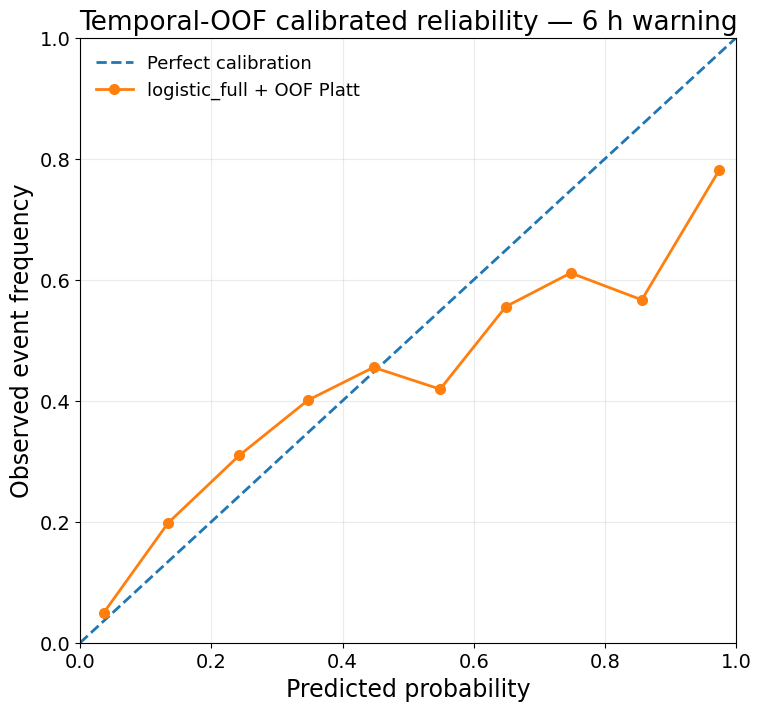

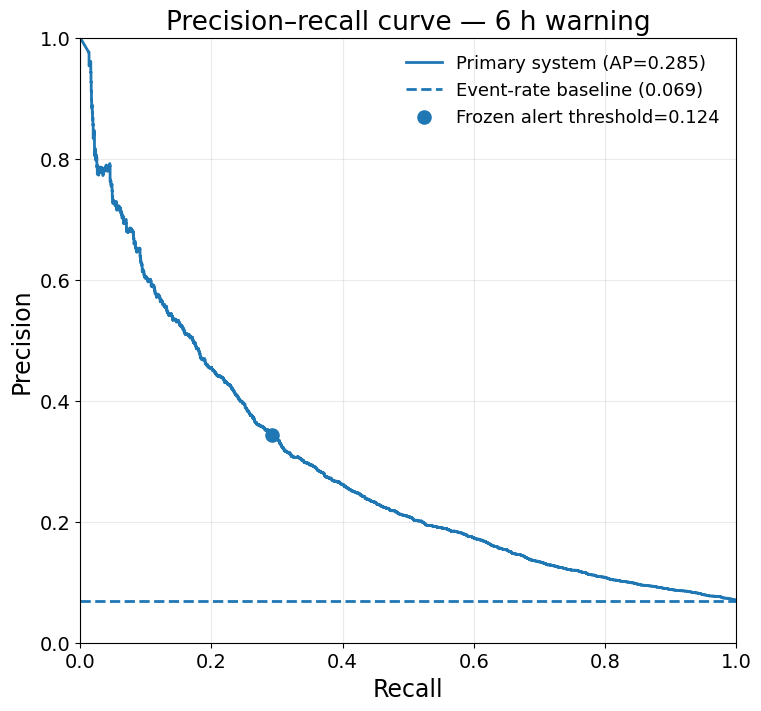

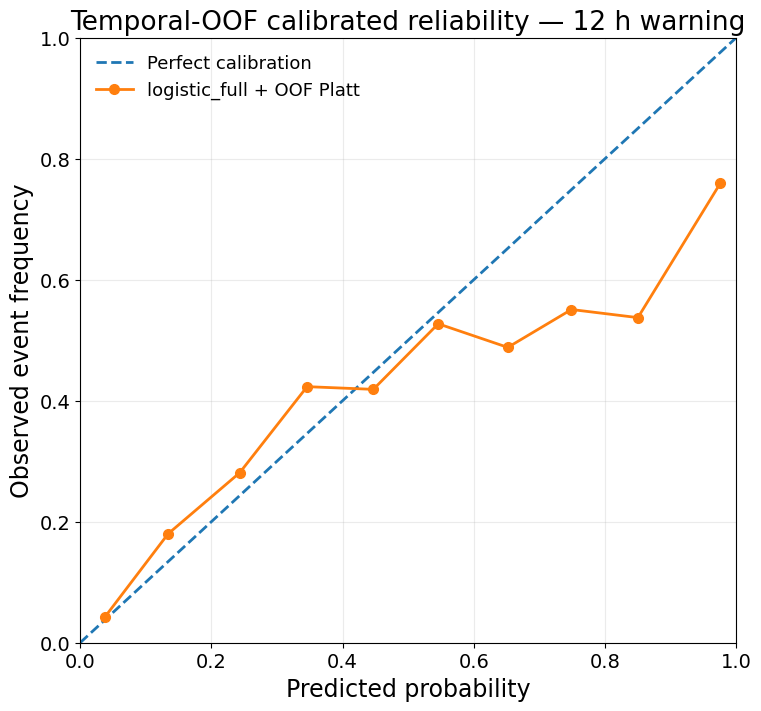

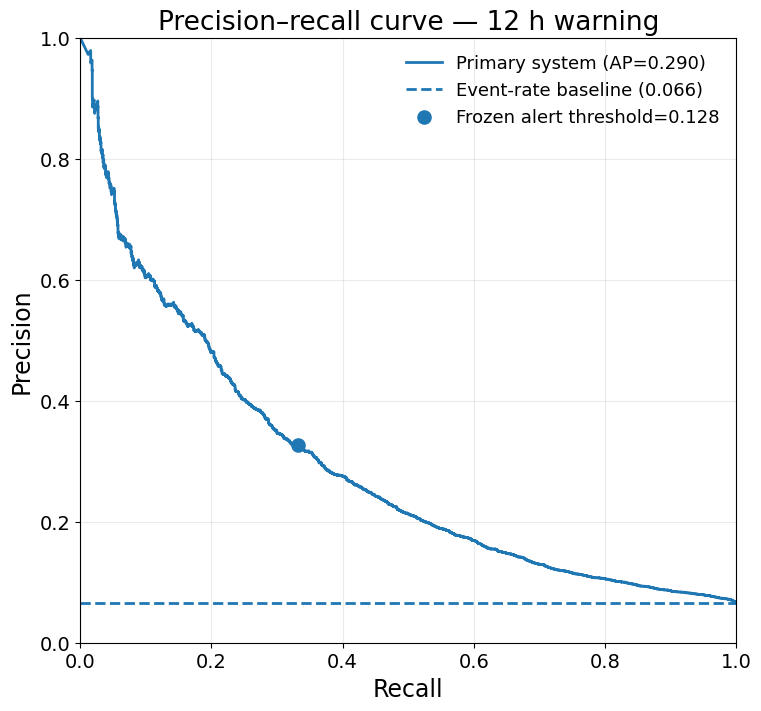

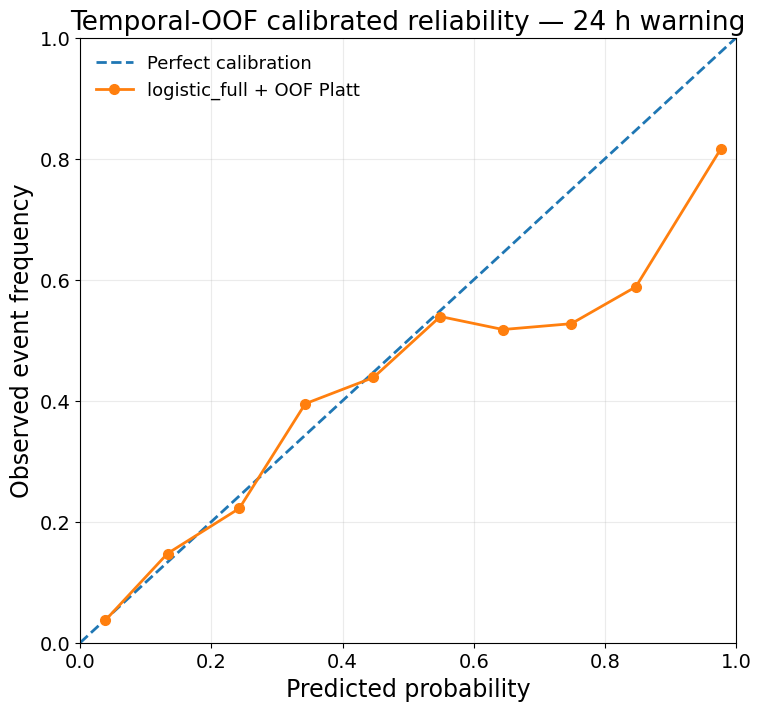

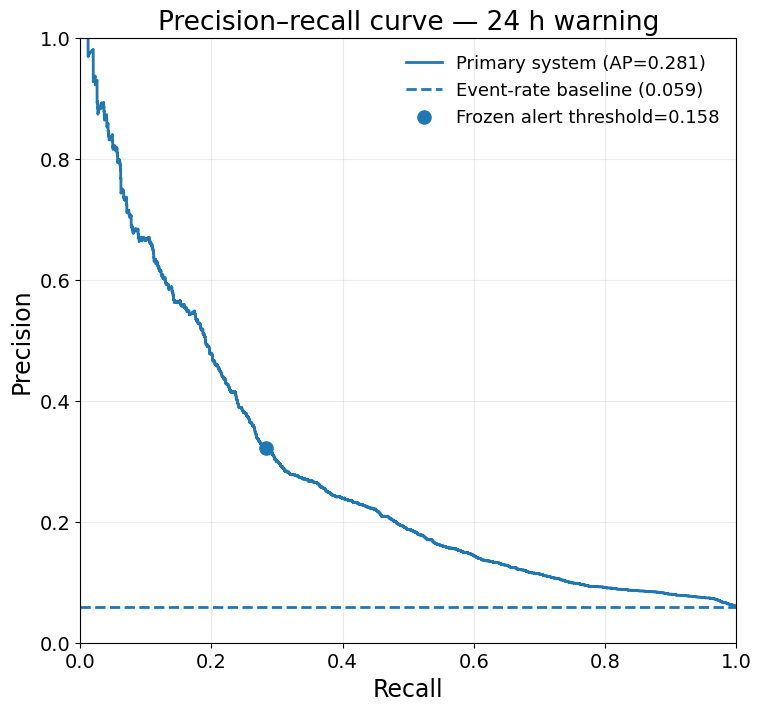

In [23]:
# ============================================================
# CELL 23 — Temporal-OOF calibrated reliability and precision-recall figures
# ============================================================
def calibration_bins(y, p, n_bins=10):
    y = np.asarray(y, dtype=int)
    p = probability_clip(p)
    edges = np.linspace(0, 1, n_bins + 1)
    ids = np.digitize(p, edges[1:-1], right=True)

    rows = []
    for b in range(n_bins):
        m = ids == b
        if m.any():
            rows.append({
                "bin": b + 1,
                "mean_predicted_probability": float(p[m].mean()),
                "observed_event_frequency": float(y[m].mean()),
                "n": int(m.sum()),
            })
    return pd.DataFrame(rows)


cal_tables = []

for h in CLS_HORIZONS:
    d = cls_confirm_pred[
        cls_confirm_pred["horizon_h"] == h
    ].copy()

    y = d["y_event"].to_numpy(dtype=int)
    p = d["prob_primary_warning"].to_numpy(dtype=float)
    alert_thr = float(ALERT_THRESHOLDS[h])

    cal = calibration_bins(y, p, n_bins=10)
    cal["horizon_h"] = h
    cal_tables.append(cal)

    # Reliability diagram
    fig, ax = plt.subplots(figsize=(7.5, 7), constrained_layout=True)
    ax.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        label="Perfect calibration",
    )
    ax.plot(
        cal["mean_predicted_probability"],
        cal["observed_event_frequency"],
        marker="o",
        label=f"{PRIMARY_CLS_MODEL} + OOF Platt",
    )
    ax.set_xlabel("Predicted probability")
    ax.set_ylabel("Observed event frequency")
    ax.set_title(f"Temporal-OOF calibrated reliability — {h} h warning")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.legend(frameon=False)
    ax.grid(alpha=0.25)
    save_figure(fig, f"Fig09_calibration_h{h}")
    plt.show()

    # Precision-recall curve
    precision, recall, _ = precision_recall_curve(y, p)

    fig, ax = plt.subplots(figsize=(7.5, 7), constrained_layout=True)
    ax.plot(
        recall,
        precision,
        label=f"Primary system (AP={average_precision_score(y, p):.3f})",
    )
    ax.axhline(
        y.mean(),
        linestyle="--",
        label=f"Event-rate baseline ({y.mean():.3f})",
    )

    # Mark the frozen development-selected operating threshold.
    alert_pred = (p >= alert_thr).astype(int)
    alert_precision = precision_score(y, alert_pred, zero_division=0)
    alert_recall = recall_score(y, alert_pred, zero_division=0)

    ax.scatter(
        [alert_recall],
        [alert_precision],
        s=90,
        label=f"Frozen alert threshold={alert_thr:.3f}",
        zorder=5,
    )

    ax.set_xlabel("Recall")
    ax.set_ylabel("Precision")
    ax.set_title(f"Precision–recall curve — {h} h warning")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.legend(frameon=False)
    ax.grid(alpha=0.25)
    save_figure(fig, f"Fig10_precision_recall_h{h}")
    plt.show()


pd.concat(cal_tables, ignore_index=True).to_csv(
    TABLE_DIR / "classification_calibration_bins.csv",
    index=False,
)


,horizon_h,event_threshold_mv,alert_probability_threshold,n_transition_events,n_detected_events,n_missed_events,event_detection_rate,n_alert_episodes,n_false_alert_episodes,false_alarm_ratio,median_lead_time_h,lead_time_q25_h,lead_time_q75_h
0,3,13.500000,0.127362,1115,48,1067,0.043049,338,288,0.852071,2.0,1.0,3.0
1,6,20.600000,0.123948,742,105,637,0.141509,491,380,0.773931,2.0,1.0,5.0
2,12,31.799999,0.128133,376,121,255,0.321809,533,369,0.692308,5.0,1.0,10.0
3,24,48.900002,0.157883,155,81,74,0.522581,365,244,0.668493,5.0,2.0,13.0


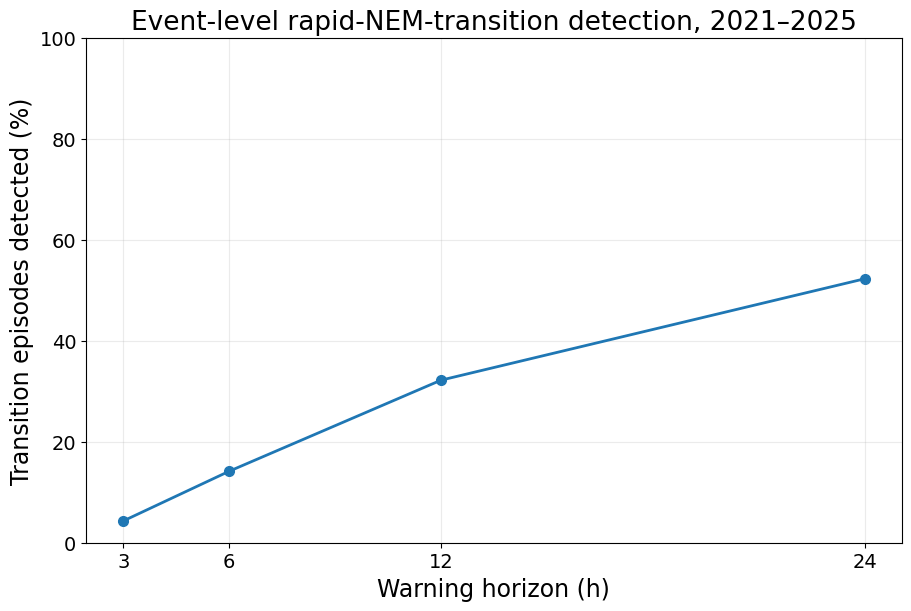

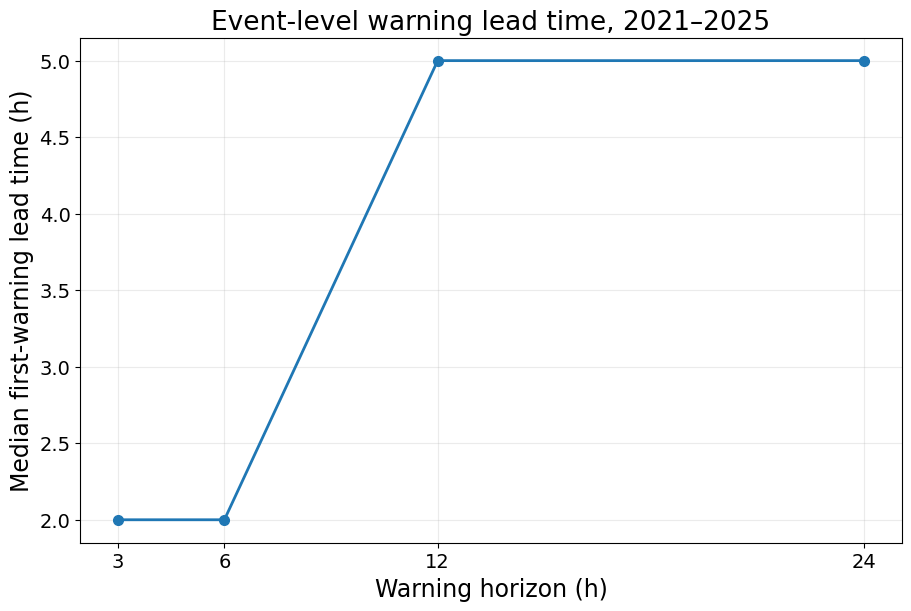

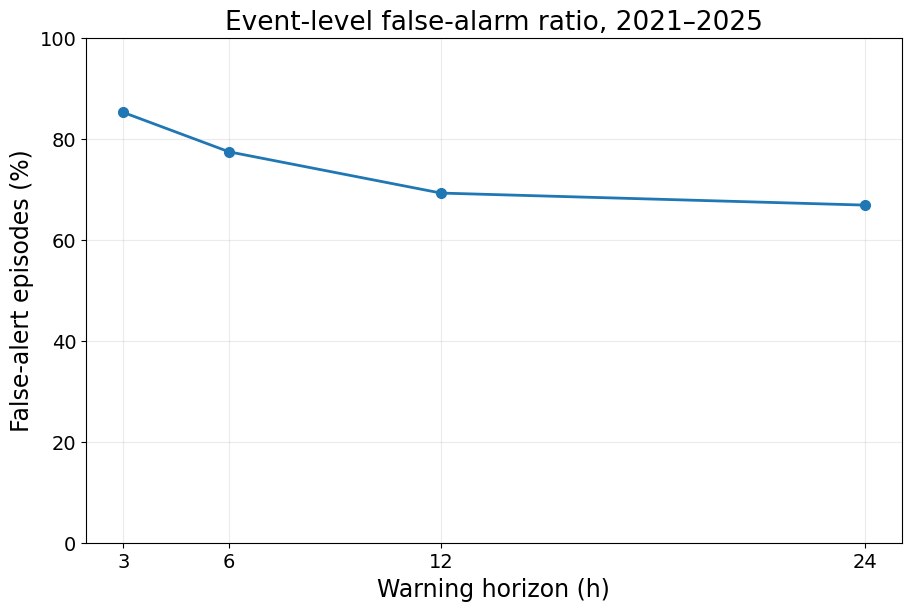

In [24]:
# ============================================================
# CELL 23B — Event-level early-warning evaluation
# ============================================================
def backward_max_abs_excursion(phi_series, h):
    current = phi_series.to_numpy(dtype=float)
    past = np.column_stack([
        phi_series.shift(s).to_numpy(dtype=float)
        for s in range(1, h + 1)
    ])
    diffs = np.abs(current[:, None] - past)
    valid = np.isfinite(current) & np.isfinite(past).all(axis=1)

    out = np.full(len(phi_series), np.nan, dtype=float)
    out[valid] = np.max(diffs[valid], axis=1)
    return pd.Series(out, index=phi_series.index)


def derive_transition_event_onsets(
    phi_series,
    h,
    event_threshold,
    start,
    end,
):
    """
    Independent event onsets based on the backward analogue of the
    forecasting target. Consecutive threshold exceedances form one episode.
    Candidate onsets occurring within h hours are merged.
    """
    start = pd.Timestamp(start)
    end = pd.Timestamp(end)

    context_start = start - pd.Timedelta(hours=h)
    s = phi_series.loc[context_start:end].copy()

    excursion = backward_max_abs_excursion(s, h)
    signal = excursion > float(event_threshold)
    signal = signal.fillna(False)

    onset_mask = signal & (~signal.shift(1, fill_value=False))
    candidates = list(signal.index[onset_mask])

    merged = []
    for t in candidates:
        if not merged:
            merged.append(t)
            continue

        if (t - merged[-1]) <= pd.Timedelta(hours=h):
            # Same broad transition episode.
            continue

        merged.append(t)

    merged = [t for t in merged if start <= t <= end]

    return pd.DataFrame({
        "event_onset": merged,
        "horizon_h": h,
        "event_threshold_mv": float(event_threshold),
    })


def derive_alert_episode_starts(prob_series, alert_threshold):
    alert = (prob_series >= float(alert_threshold)).fillna(False)
    onset = alert & (~alert.shift(1, fill_value=False))
    return list(alert.index[onset])


def evaluate_event_level_warning(
    pred_df,
    h,
    event_threshold,
    alert_threshold,
    phi_series,
    period_start,
    period_end,
):
    """
    Greedy one-to-one matching:
      alert -> event if alert occurs within [event_onset-h, event_onset-1h].

    The earliest eligible alert is used, so lead time represents the first
    operational warning for that event.
    """
    events = derive_transition_event_onsets(
        phi_series=phi_series,
        h=h,
        event_threshold=event_threshold,
        start=period_start,
        end=period_end,
    )

    d = pred_df.sort_index().copy()
    alerts = derive_alert_episode_starts(
        d["prob_primary_warning"],
        alert_threshold,
    )

    associated_alerts = set()
    event_rows = []

    for event_time in events["event_onset"]:
        window_start = event_time - pd.Timedelta(hours=h)
        window_end = event_time - pd.Timedelta(hours=1)

        eligible = [
            a for a in alerts
            if window_start <= a <= window_end
        ]

        # All alerts inside a legitimate pre-event window are associated
        # with that event and are therefore not counted as false alarms.
        associated_alerts.update(eligible)

        if eligible:
            first_alert = min(eligible)
            lead_h = (
                event_time - first_alert
            ).total_seconds() / 3600.0

            event_rows.append({
                "event_onset": event_time,
                "detected": 1,
                "first_alert": first_alert,
                "lead_time_h": lead_h,
            })
        else:
            event_rows.append({
                "event_onset": event_time,
                "detected": 0,
                "first_alert": pd.NaT,
                "lead_time_h": np.nan,
            })

    event_detail = pd.DataFrame(event_rows)

    # An alert episode is false only if it is not within the valid
    # pre-event window of any transition episode.
    n_alerts = len(alerts)
    n_false_alerts = n_alerts - len(associated_alerts)
    n_events = len(event_detail)
    n_detected = int(event_detail["detected"].sum()) if n_events else 0

    lead = (
        event_detail.loc[event_detail["detected"] == 1, "lead_time_h"]
        if n_events
        else pd.Series(dtype=float)
    )

    summary = {
        "horizon_h": h,
        "event_threshold_mv": float(event_threshold),
        "alert_probability_threshold": float(alert_threshold),
        "n_transition_events": int(n_events),
        "n_detected_events": int(n_detected),
        "n_missed_events": int(n_events - n_detected),
        "event_detection_rate": (
            n_detected / n_events if n_events > 0 else np.nan
        ),
        "n_alert_episodes": int(n_alerts),
        "n_false_alert_episodes": int(n_false_alerts),
        "false_alarm_ratio": (
            n_false_alerts / n_alerts if n_alerts > 0 else np.nan
        ),
        "median_lead_time_h": float(lead.median()) if len(lead) else np.nan,
        "lead_time_q25_h": float(lead.quantile(0.25)) if len(lead) else np.nan,
        "lead_time_q75_h": float(lead.quantile(0.75)) if len(lead) else np.nan,
    }

    return summary, event_detail


event_warning_rows = []
event_detail_parts = []

for h in CLS_HORIZONS:
    d = cls_confirm_pred[
        cls_confirm_pred["horizon_h"] == h
    ].copy()

    event_threshold = float(
        final_event_thresholds
        .set_index("horizon_h")
        .loc[h, "event_threshold_mv"]
    )
    alert_threshold = float(ALERT_THRESHOLDS[h])

    summary, detail = evaluate_event_level_warning(
        pred_df=d,
        h=h,
        event_threshold=event_threshold,
        alert_threshold=alert_threshold,
        phi_series=master["phi_mv"],
        period_start=CONFIRM_START,
        period_end=CONFIRM_END,
    )

    event_warning_rows.append(summary)

    if not detail.empty:
        detail["horizon_h"] = h
        event_detail_parts.append(detail)


event_warning_summary = pd.DataFrame(event_warning_rows)

if event_detail_parts:
    event_warning_detail = pd.concat(
        event_detail_parts,
        ignore_index=True,
    )
else:
    event_warning_detail = pd.DataFrame()

event_warning_summary.to_csv(
    TABLE_DIR / "event_level_early_warning_2021_2025.csv",
    index=False,
)
event_warning_detail.to_csv(
    TABLE_DIR / "event_level_transition_details_2021_2025.csv",
    index=False,
)

display(event_warning_summary)


# Journal figure: event detection rate
fig, ax = plt.subplots(figsize=(9, 6), constrained_layout=True)
ax.plot(
    event_warning_summary["horizon_h"],
    100 * event_warning_summary["event_detection_rate"],
    marker="o",
)
ax.set_xlabel("Warning horizon (h)")
ax.set_ylabel("Transition episodes detected (%)")
ax.set_title("Event-level rapid-NEM-transition detection, 2021–2025")
ax.set_xticks(CLS_HORIZONS)
ax.set_ylim(0, 100)
ax.grid(alpha=0.25)
save_figure(fig, "Fig10B_event_level_detection_rate")
plt.show()


# Journal figure: median warning lead time
fig, ax = plt.subplots(figsize=(9, 6), constrained_layout=True)
ax.plot(
    event_warning_summary["horizon_h"],
    event_warning_summary["median_lead_time_h"],
    marker="o",
)
ax.set_xlabel("Warning horizon (h)")
ax.set_ylabel("Median first-warning lead time (h)")
ax.set_title("Event-level warning lead time, 2021–2025")
ax.set_xticks(CLS_HORIZONS)
ax.grid(alpha=0.25)
save_figure(fig, "Fig10C_event_level_lead_time")
plt.show()


# Journal figure: false-alarm ratio
fig, ax = plt.subplots(figsize=(9, 6), constrained_layout=True)
ax.plot(
    event_warning_summary["horizon_h"],
    100 * event_warning_summary["false_alarm_ratio"],
    marker="o",
)
ax.set_xlabel("Warning horizon (h)")
ax.set_ylabel("False-alert episodes (%)")
ax.set_title("Event-level false-alarm ratio, 2021–2025")
ax.set_xticks(CLS_HORIZONS)
ax.set_ylim(0, 100)
ax.grid(alpha=0.25)
save_figure(fig, "Fig10D_event_level_false_alarm_ratio")
plt.show()


Fitting GMM K = 2
Fitting GMM K = 3
Fitting GMM K = 4
Fitting GMM K = 5
Fitting GMM K = 6
Fitting GMM K = 7
Fitting GMM K = 8
Fitting GMM K = 9
Fitting GMM K = 10


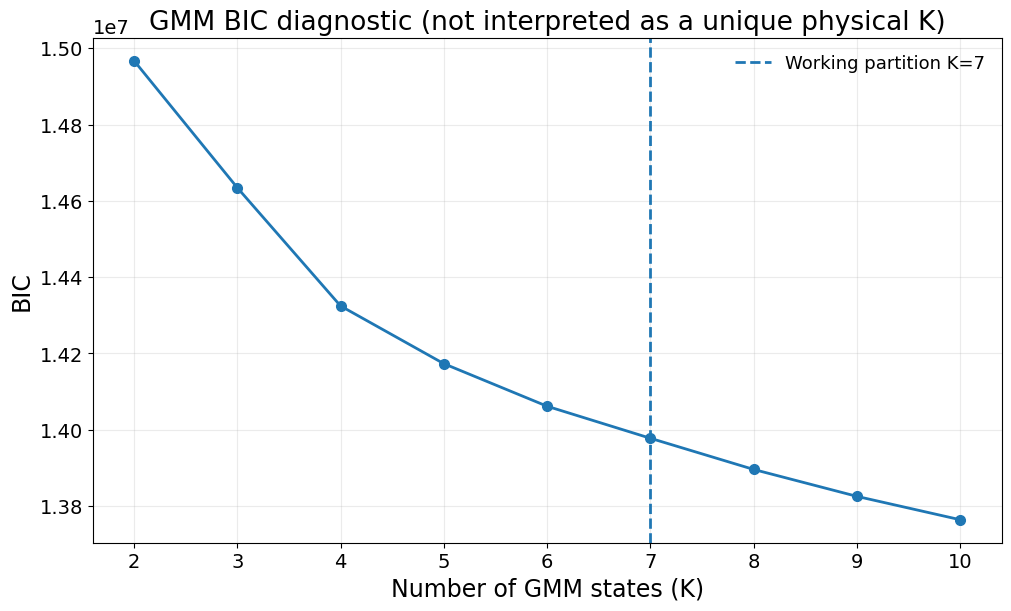

,k,bic,aic,silhouette,davies_bouldin,min_state_fraction,max_state_fraction,valid_min_fraction,converged,selected
0,2,1.496755e+07,1.496701e+07,0.285552,3.726623,0.149578,0.850422,True,True,False
1,3,1.463442e+07,1.463360e+07,0.105375,3.384620,0.126003,0.456159,True,True,False
2,4,1.432430e+07,1.432320e+07,0.077627,3.647054,0.046915,0.366947,True,True,False
3,5,1.417287e+07,1.417149e+07,0.061633,3.103549,0.050497,0.345156,True,True,False
4,6,1.406124e+07,1.405959e+07,0.044382,2.874026,0.047500,0.334033,True,True,False
5,7,1.397725e+07,1.397531e+07,0.055422,2.648578,0.039024,0.240750,True,True,True
6,8,1.389548e+07,1.389327e+07,0.018558,2.957052,0.025045,0.206137,True,True,False
7,9,1.382489e+07,1.382240e+07,0.019556,2.859918,0.011467,0.158363,False,True,False
8,10,1.376361e+07,1.376084e+07,0.014885,2.915640,0.014763,0.141920,False,True,False


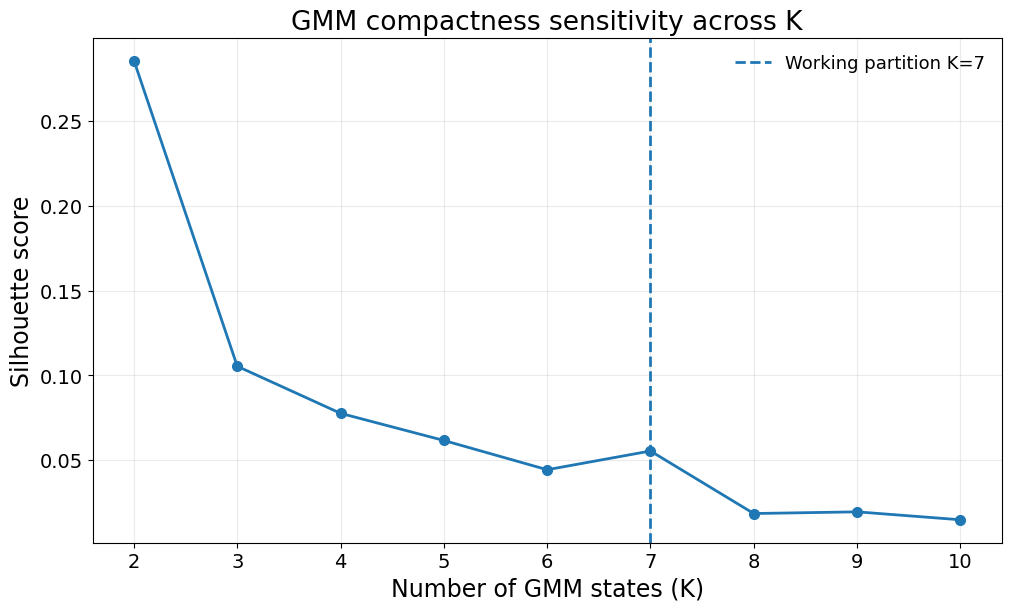

In [25]:
# ============================================================
# CELL 24 — GMM K diagnostics and selection
# ============================================================
dev_state_mask=(
    (final_features.index>=MODEL_START)&(final_features.index<=DEV_END)
    &(final_features["n_active_nm"]>=MIN_ACTIVE_NM)
)
state_dev=final_features.loc[dev_state_mask,STATE_FEATURES].copy()

state_imputer=SimpleImputer(strategy="median")
state_scaler=StandardScaler()
Z_dev=state_imputer.fit_transform(state_dev)
Z_dev_scaled=state_scaler.fit_transform(Z_dev)

rng=np.random.default_rng(SEED)
if len(Z_dev_scaled)>SILHOUETTE_SAMPLE:
    score_idx=rng.choice(len(Z_dev_scaled),SILHOUETTE_SAMPLE,replace=False)
else:
    score_idx=np.arange(len(Z_dev_scaled))
Z_score=Z_dev_scaled[score_idx]

gmm_rows=[]; gmm_models={}
for k in GMM_K_VALUES:
    print("Fitting GMM K =",k)
    gmm=GaussianMixture(
        n_components=k,covariance_type="diag",n_init=GMM_N_INIT,
        max_iter=GMM_MAX_ITER,reg_covar=1e-5,random_state=SEED
    )
    gmm.fit(Z_dev_scaled)
    hard=gmm.predict(Z_dev_scaled)
    frac=np.bincount(hard,minlength=k)/len(hard)
    hs=hard[score_idx]
    sil=silhouette_score(Z_score,hs) if len(np.unique(hs))>1 else np.nan
    db=davies_bouldin_score(Z_score,hs) if len(np.unique(hs))>1 else np.nan
    gmm_rows.append({
        "k":k,"bic":gmm.bic(Z_dev_scaled),"aic":gmm.aic(Z_dev_scaled),
        "silhouette":sil,"davies_bouldin":db,
        "min_state_fraction":float(frac.min()),"max_state_fraction":float(frac.max()),
        "valid_min_fraction":bool(frac.min()>=GMM_MIN_STATE_FRACTION),
        "converged":bool(gmm.converged_)
    })
    gmm_models[k]=gmm

gmm_diag=pd.DataFrame(gmm_rows)
valid=gmm_diag[gmm_diag["valid_min_fraction"]&gmm_diag["converged"]].copy()
if valid.empty:
    valid=gmm_diag[gmm_diag["converged"]].copy()
valid["rank_bic"]=valid["bic"].rank(ascending=True,method="min")
valid["rank_silhouette"]=valid["silhouette"].rank(ascending=False,method="min")
valid["rank_db"]=valid["davies_bouldin"].rank(ascending=True,method="min")
valid["rank_sum"]=valid[["rank_bic","rank_silhouette","rank_db"]].sum(axis=1)

SELECTED_K=int(valid.sort_values(["rank_sum","bic"]).iloc[0]["k"])
final_gmm=gmm_models[SELECTED_K]
gmm_diag["selected"]=gmm_diag["k"]==SELECTED_K
gmm_diag.to_csv(TABLE_DIR/"gmm_k_diagnostics.csv",index=False)
joblib.dump(state_imputer,MODEL_DIR/"state_imputer.joblib")
joblib.dump(state_scaler,MODEL_DIR/"state_scaler.joblib")
joblib.dump(final_gmm,MODEL_DIR/"state_gmm.joblib")

fig,ax=plt.subplots(figsize=(10,6),constrained_layout=True)
ax.plot(gmm_diag["k"],gmm_diag["bic"],marker="o")
ax.axvline(SELECTED_K,linestyle="--",label=f"Working partition K={SELECTED_K}")
ax.set_xlabel("Number of GMM states (K)")
ax.set_ylabel("BIC")
ax.set_title("GMM BIC diagnostic (not interpreted as a unique physical K)")
ax.set_xticks(GMM_K_VALUES)
ax.legend(frameon=False); ax.grid(alpha=0.25)
save_figure(fig,"Fig11_gmm_bic_diagnostic")
plt.show()
display(gmm_diag)


fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
ax.plot(
    gmm_diag["k"],
    gmm_diag["silhouette"],
    marker="o",
)
ax.axvline(
    SELECTED_K,
    linestyle="--",
    label=f"Working partition K={SELECTED_K}",
)
ax.set_xlabel("Number of GMM states (K)")
ax.set_ylabel("Silhouette score")
ax.set_title("GMM compactness sensitivity across K")
ax.set_xticks(GMM_K_VALUES)
ax.legend(frameon=False)
ax.grid(alpha=0.25)
save_figure(fig, "Fig11B_gmm_silhouette_diagnostic")
plt.show()


In [26]:

# ============================================================
# CELL 25 — KMeans robustness, state labels, characterization
# ============================================================
kmeans=KMeans(n_clusters=SELECTED_K,n_init=20,random_state=SEED).fit(Z_dev_scaled)
gmm_hard_dev=final_gmm.predict(Z_dev_scaled)
kmeans_hard_dev=kmeans.predict(Z_dev_scaled)
ari=adjusted_rand_score(gmm_hard_dev,kmeans_hard_dev)
pd.DataFrame([{"selected_k":SELECTED_K,"gmm_vs_kmeans_ari":ari}]).to_csv(
    TABLE_DIR/"gmm_kmeans_robustness.csv",index=False
)
joblib.dump(kmeans,MODEL_DIR/"state_kmeans_sensitivity.joblib")

tmp=final_features.loc[state_dev.index,["phi_roll_std_24"]].copy()
tmp["raw_state"]=gmm_hard_dev
order=tmp.groupby("raw_state")["phi_roll_std_24"].median().sort_values().index
RAW_TO_STATE={int(raw):f"S{i+1}" for i,raw in enumerate(order)}
with open(LOG_DIR/"state_label_mapping.json","w") as f:
    json.dump({str(k):v for k,v in RAW_TO_STATE.items()},f,indent=2)

dev_char=final_features.loc[state_dev.index,STATE_FEATURES+["phi_t","n_active_nm"]].copy()
dev_char["raw_state"]=gmm_hard_dev
dev_char["state"]=[RAW_TO_STATE[int(x)] for x in gmm_hard_dev]
state_profile=dev_char.groupby("state").median(numeric_only=True)
state_profile["n_hours"]=dev_char.groupby("state").size()
state_profile["fraction"]=state_profile["n_hours"]/state_profile["n_hours"].sum()
state_profile.to_csv(TABLE_DIR/"state_characterization_development.csv")
print("GMM/KMeans ARI:",ari)
display(state_profile)


GMM/KMeans ARI: 0.4352918130789516


,phi_diff_1,phi_diff_6,phi_slope_24,phi_roll_std_24,rmse_t,rmse_diff_6,nm_mad,nm_median_diff_6,kappa_mad,kappa_mad_diff_6,rc_std_lag3,rc_median_diff_3_lag3,phi_t,n_active_nm,raw_state,n_hours,fraction
state,,,,,,,,,,,,,,,,,
S1,0.0,0.1,-0.100000,3.986333,0.011239,0.000229,0.010121,0.000038,0.007606,0.000361,1.317251,-0.005,500.500000,22.0,5.0,117782,0.236252
S2,-0.2,-1.8,-0.166667,4.407169,0.012043,-0.000128,0.009046,0.000640,0.007354,-0.000214,1.364432,0.005,550.900024,26.0,4.0,74657,0.149750
S3,-0.3,-1.4,-0.170833,4.551348,0.009018,-0.000465,0.007020,0.000501,0.005329,-0.000641,1.328274,0.000,598.099976,23.0,1.0,120024,0.240750
S4,-0.5,-1.8,-0.175000,5.912698,0.013909,0.001400,0.010579,0.000285,0.009814,0.002195,1.341352,0.005,564.700012,24.0,2.0,47196,0.094668
S5,2.5,10.6,0.645833,7.756735,0.011455,0.000116,0.008633,-0.003259,0.007200,-0.000039,1.323721,-0.015,631.900024,23.0,3.0,58071,0.116481
S6,-1.8,-8.6,-0.683333,10.222032,0.011140,-0.000446,0.008148,0.002474,0.007008,-0.000450,1.327353,0.010,714.700012,24.0,0.0,61358,0.123075
S7,1.2,13.5,2.183333,24.044195,0.013998,0.000397,0.009103,-0.003952,0.009077,0.000469,1.313372,-0.005,831.400024,24.0,6.0,19455,0.039024


In [27]:
# ============================================================
# CELL 26 — Assign 2021–2025 states and compute state-conditioned results
# ============================================================
confirm_state_mask=(
    (final_features.index>=CONFIRM_START)&(final_features.index<=CONFIRM_END)
    &(final_features["n_active_nm"]>=MIN_ACTIVE_NM)
)
state_confirm=final_features.loc[confirm_state_mask,STATE_FEATURES]
Z_conf=state_scaler.transform(state_imputer.transform(state_confirm))
gmm_probs_conf=final_gmm.predict_proba(Z_conf)
gmm_raw_conf=gmm_probs_conf.argmax(axis=1)

state_assignment=pd.DataFrame(index=state_confirm.index)
state_assignment["raw_state"]=gmm_raw_conf
state_assignment["state"]=[RAW_TO_STATE[int(x)] for x in gmm_raw_conf]
state_assignment["state_confidence"]=gmm_probs_conf.max(axis=1)
for k in range(SELECTED_K):
    state_assignment[f"prob_raw{k}"]=gmm_probs_conf[:,k]
save_frame(state_assignment,PRED_DIR/"state_assignments_2021_2025.parquet")

state_reg_rows=[]
for h in REG_HORIZONS:
    d=reg_confirm_pred[reg_confirm_pred["horizon_h"]==h].join(
        state_assignment[["state"]],how="left"
    ).dropna(subset=["state"])
    for state,ds in d.groupby("state"):
        m=regression_metrics(ds["y_delta"],ds["pred_primary_single"],ds["phi_t"])
        state_reg_rows.append({
            "state":state,"horizon_h":h,"model":PRIMARY_REG_MODEL,
            "feature_set":PRIMARY_REG_FEATURE_SET,**m
        })

state_cls_rows=[]
for h in CLS_HORIZONS:
    d=cls_confirm_pred[cls_confirm_pred["horizon_h"]==h].join(
        state_assignment[["state"]],how="left"
    ).dropna(subset=["state"])
    for state,ds in d.groupby("state"):
        m=classification_metrics(
            ds["y_event"],
            ds["prob_primary_warning"],
            threshold=float(ALERT_THRESHOLDS[h]),
        )
        state_cls_rows.append({
            "state":state,"horizon_h":h,"model":PRIMARY_CLS_MODEL,
            "mean_predicted_probability":float(ds["prob_primary_warning"].mean()),**m
        })

state_reg_results=pd.DataFrame(state_reg_rows)
state_cls_results=pd.DataFrame(state_cls_rows)
state_reg_results.to_csv(TABLE_DIR/"state_conditioned_regression_skill.csv",index=False)
state_cls_results.to_csv(TABLE_DIR/"state_conditioned_transition_risk_and_warning.csv",index=False)
display(state_reg_results)
display(state_cls_results)


,state,horizon_h,model,feature_set,n,dphi_mae,dphi_rmse,phi_mae,phi_rmse,phi_r2,skill_mse_vs_persistence,direction_accuracy
0,S1,1,cat,A5_phi_rmse_rc_op,15674,2.503762,3.216780,2.503762,3.216780,0.999649,0.062557,0.594144
1,S3,1,cat,A5_phi_rmse_rc_op,2956,2.507802,3.216749,2.507802,3.216749,0.999670,0.072466,0.596233
2,S4,1,cat,A5_phi_rmse_rc_op,8705,2.721138,3.594214,2.721138,3.594214,0.999625,0.052989,0.580960
3,S5,1,cat,A5_phi_rmse_rc_op,6829,3.191490,4.235914,3.191490,4.235914,0.999404,0.055332,0.579976
4,S6,1,cat,A5_phi_rmse_rc_op,7032,2.912349,3.844842,2.912349,3.844842,0.999541,0.064953,0.594020
5,S7,1,cat,A5_phi_rmse_rc_op,2561,5.327079,8.589116,5.327079,8.589116,0.998150,0.289987,0.617473
6,S1,3,cat,A5_phi_rmse_rc_op,15673,3.975063,5.218676,3.975063,5.218676,0.999074,0.140538,0.647743
7,S3,3,cat,A5_phi_rmse_rc_op,2956,3.984130,5.180709,3.984130,5.180709,0.999141,0.160525,0.646054
8,S4,3,cat,A5_phi_rmse_rc_op,8702,4.635316,6.410152,4.635316,6.410152,0.998806,0.131261,0.647590
9,S5,3,cat,A5_phi_rmse_rc_op,6827,5.867086,8.285168,5.867086,8.285168,0.997727,0.100355,0.628462


,state,horizon_h,model,mean_predicted_probability,n,event_rate,decision_threshold,pr_auc,roc_auc,precision,recall,specificity,f1,brier,ece10
0,S1,3,logistic_full,0.022262,15673,0.022714,0.127362,0.041290,0.612924,0.000000,0.000000,0.999935,0.000000,0.022083,0.000483
1,S3,3,logistic_full,0.020220,2956,0.021989,0.127362,0.059676,0.644169,0.000000,0.000000,1.000000,0.000000,0.021356,0.001769
2,S4,3,logistic_full,0.035251,8702,0.050908,0.127362,0.132019,0.692412,0.237288,0.031603,0.994551,0.055777,0.047256,0.016080
3,S5,3,logistic_full,0.051714,6827,0.091548,0.127362,0.177739,0.660396,0.294118,0.136000,0.967107,0.185996,0.082186,0.040123
4,S6,3,logistic_full,0.037925,7031,0.068554,0.127362,0.118509,0.635646,0.219512,0.037344,0.990228,0.063830,0.063849,0.030829
5,S7,3,logistic_full,0.257139,2558,0.302580,0.127362,0.533866,0.685826,0.392292,0.736434,0.505045,0.511899,0.200898,0.110149
6,S1,6,logistic_full,0.026489,15672,0.025715,0.123948,0.041994,0.610371,0.000000,0.000000,0.999869,0.000000,0.024940,0.000774
7,S3,6,logistic_full,0.024505,2956,0.023342,0.123948,0.040644,0.622204,0.000000,0.000000,1.000000,0.000000,0.022700,0.001163
8,S4,6,logistic_full,0.043436,8695,0.060725,0.123948,0.137558,0.663442,0.219512,0.051136,0.988245,0.082949,0.055748,0.017907
9,S5,6,logistic_full,0.060142,6824,0.094812,0.123948,0.187501,0.650023,0.253669,0.187017,0.942367,0.215302,0.084126,0.034851


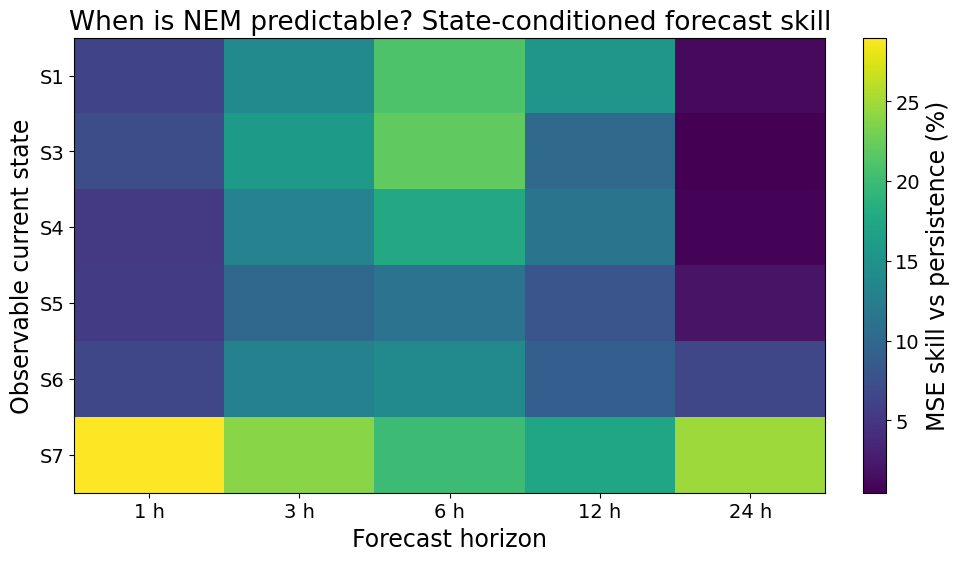

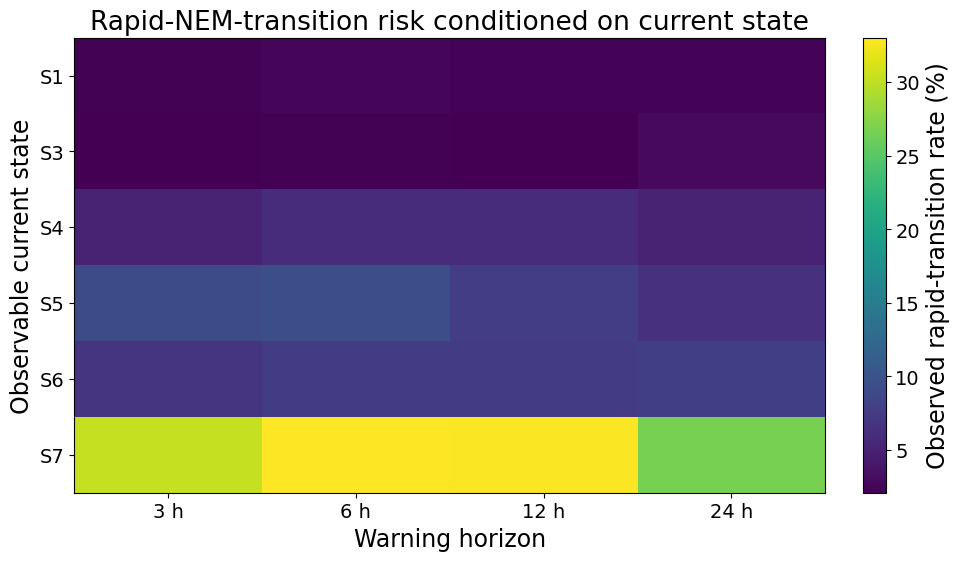

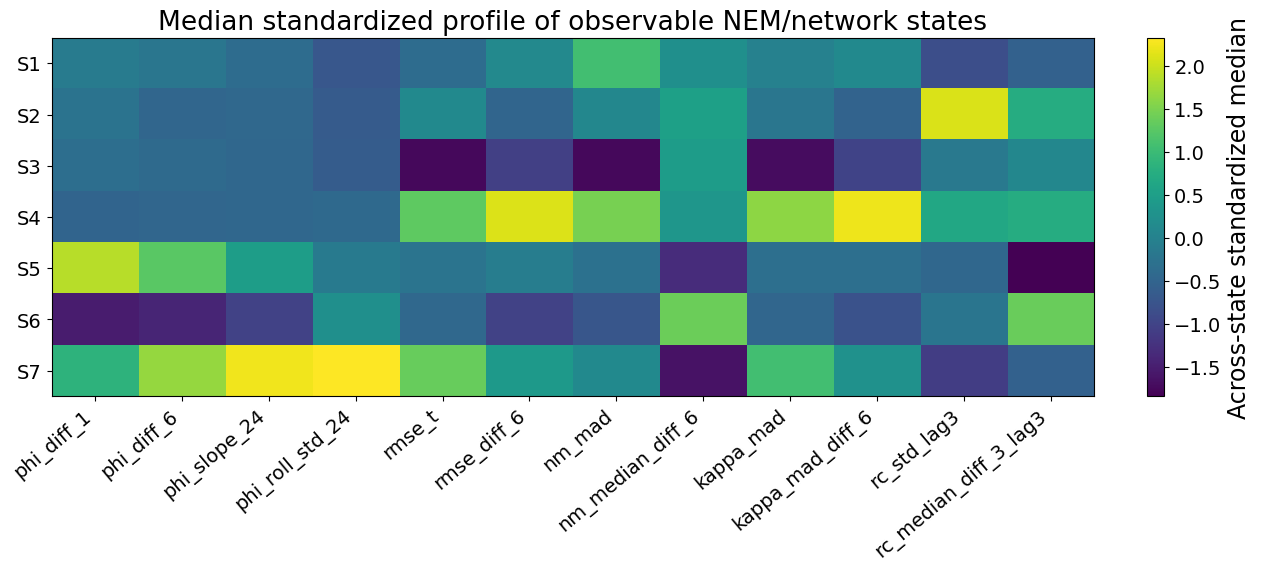

In [28]:

# ============================================================
# CELL 27 — Journal plots: state-conditioned skill, risk, profile
# ============================================================
reg_heat=state_reg_results.pivot(index="state",columns="horizon_h",
                                 values="skill_mse_vs_persistence").sort_index()
fig,ax=plt.subplots(figsize=(9.5,max(5.5,0.8*len(reg_heat))),constrained_layout=True)
im=ax.imshow(100*reg_heat.values,aspect="auto")
ax.set_xticks(range(len(reg_heat.columns))); ax.set_xticklabels([f"{h} h" for h in reg_heat.columns])
ax.set_yticks(range(len(reg_heat.index))); ax.set_yticklabels(reg_heat.index)
ax.set_xlabel("Forecast horizon"); ax.set_ylabel("Observable current state")
ax.set_title("When is NEM predictable? State-conditioned forecast skill")
cbar=fig.colorbar(im,ax=ax); cbar.set_label("MSE skill vs persistence (%)")
save_figure(fig,"Fig12_state_conditioned_forecast_skill")
plt.show()

risk_heat=state_cls_results.pivot(index="state",columns="horizon_h",values="event_rate").sort_index()
fig,ax=plt.subplots(figsize=(9.5,max(5.5,0.8*len(risk_heat))),constrained_layout=True)
im=ax.imshow(100*risk_heat.values,aspect="auto")
ax.set_xticks(range(len(risk_heat.columns))); ax.set_xticklabels([f"{h} h" for h in risk_heat.columns])
ax.set_yticks(range(len(risk_heat.index))); ax.set_yticklabels(risk_heat.index)
ax.set_xlabel("Warning horizon"); ax.set_ylabel("Observable current state")
ax.set_title("Rapid-NEM-transition risk conditioned on current state")
cbar=fig.colorbar(im,ax=ax); cbar.set_label("Observed rapid-transition rate (%)")
save_figure(fig,"Fig13_state_conditioned_transition_risk")
plt.show()

profile=state_profile[STATE_FEATURES].copy()
profile_z=((profile-profile.mean())/profile.std(ddof=0)).replace([np.inf,-np.inf],np.nan).fillna(0)
fig,ax=plt.subplots(figsize=(12.5,max(5.5,0.8*len(profile_z))),constrained_layout=True)
im=ax.imshow(profile_z.values,aspect="auto")
ax.set_xticks(range(len(profile_z.columns))); ax.set_xticklabels(profile_z.columns,rotation=40,ha="right")
ax.set_yticks(range(len(profile_z.index))); ax.set_yticklabels(profile_z.index)
ax.set_title("Median standardized profile of observable NEM/network states")
cbar=fig.colorbar(im,ax=ax); cbar.set_label("Across-state standardized median")
save_figure(fig,"Fig14_state_profile_heatmap")
plt.show()


,k,high_volatility_state_rank,high_volatility_state_skill_6h,high_volatility_state_transition_rate_12h,skill_range_6h,transition_rate_range_12h,spearman_volatility_rank_vs_skill_6h,spearman_volatility_rank_vs_transition_rate_12h,min_confirmation_state_fraction
0,2,2,0.174676,0.176402,0.003240,0.141484,NaN,NaN,0.216603
1,3,3,0.176641,0.196764,0.021927,0.167364,-0.500000,1.000000,0.174261
2,4,4,0.194560,0.294569,0.091642,0.271492,-0.400000,1.000000,0.074814
3,5,5,0.199426,0.297331,0.099212,0.271951,-0.500000,0.900000,0.073054
4,6,6,0.195926,0.298095,0.109366,0.279235,-0.542857,0.885714,0.056944
5,7,7,0.200487,0.327978,0.107614,0.307004,-0.542857,0.885714,0.000000
6,8,8,0.239339,0.380176,0.143714,0.363662,-0.500000,0.642857,0.000114
7,9,9,0.250431,0.506550,0.132511,0.489164,-0.238095,0.880952,0.000000
8,10,10,0.243384,0.454545,0.142119,0.440687,-0.316667,0.900000,0.000000


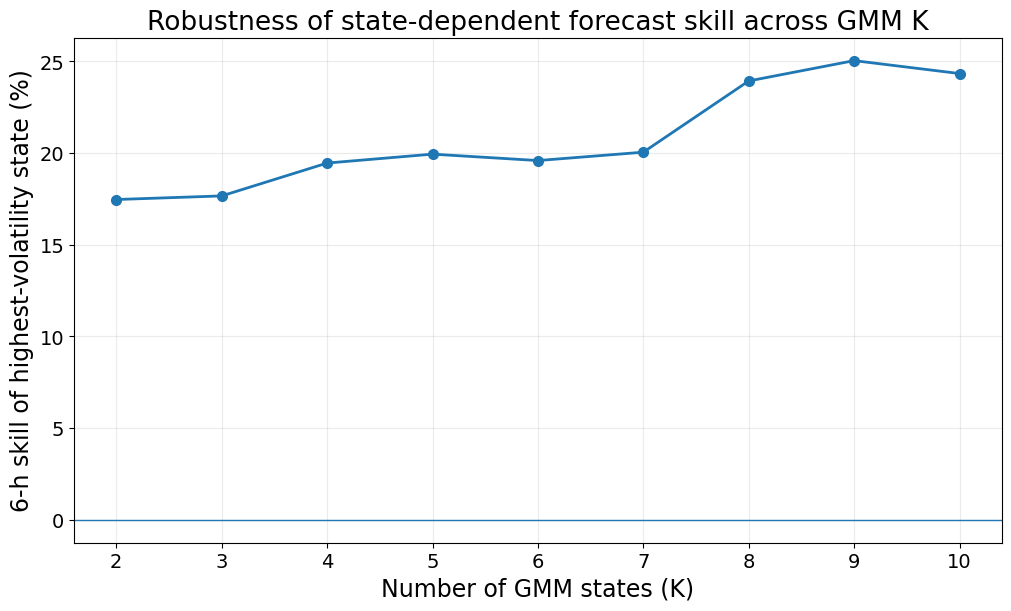

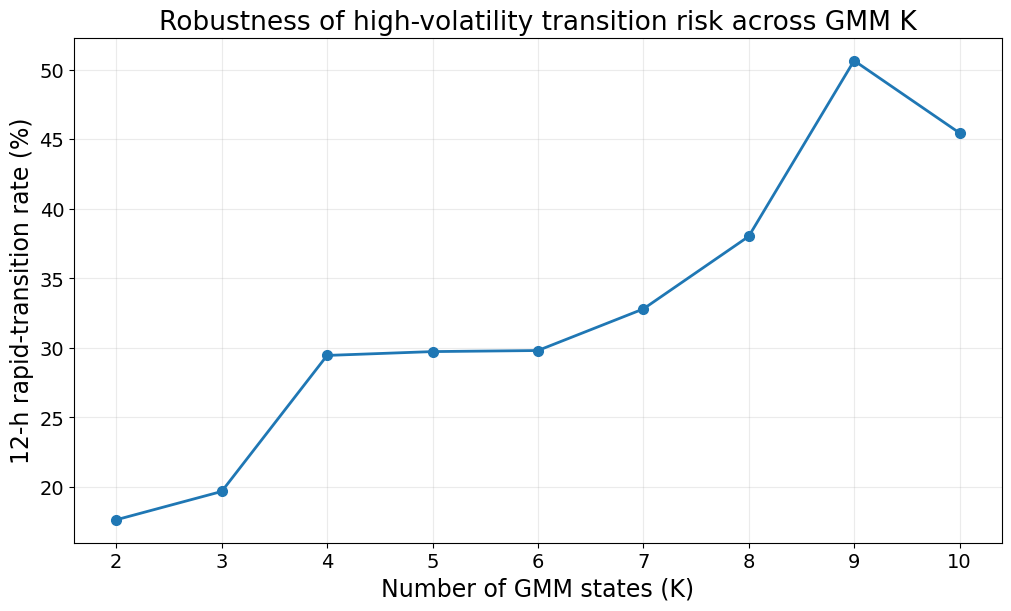

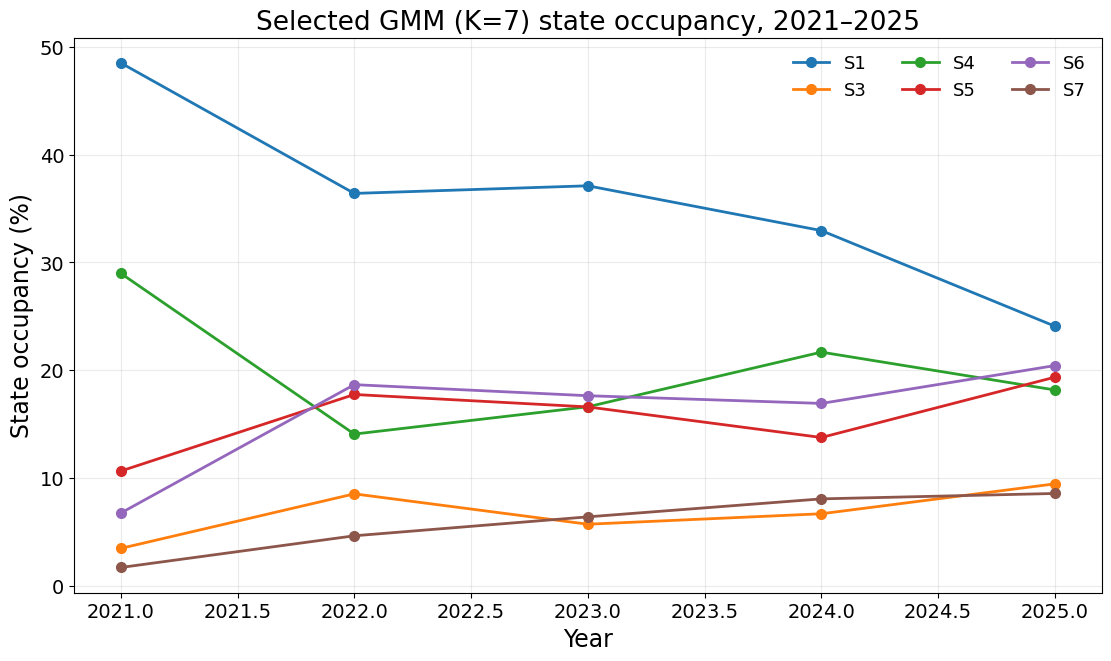

In [29]:
# ============================================================
# CELL 27B — GMM state-dependence robustness across K=2..10
# ============================================================
gmm_state_detail_rows = []
gmm_state_summary_rows = []

# Fixed confirmation targets used for this sensitivity.
reg6 = reg_confirm_pred[
    reg_confirm_pred["horizon_h"] == 6
][["phi_t", "y_delta", "pred_primary_single"]].copy()

cls12 = cls_confirm_pred[
    cls_confirm_pred["horizon_h"] == 12
][["y_event"]].copy()

for k in GMM_K_VALUES:
    gmm_k = gmm_models[k]

    raw_dev_k = gmm_k.predict(Z_dev_scaled)
    raw_conf_k = gmm_k.predict(Z_conf)

    # Order states only by DEVELOPMENT median current 24-h volatility.
    mapping_source = pd.DataFrame(
        {
            "raw_state": raw_dev_k,
            "phi_roll_std_24": final_features.loc[
                state_dev.index, "phi_roll_std_24"
            ].to_numpy(dtype=float),
        },
        index=state_dev.index,
    )

    raw_order = (
        mapping_source
        .groupby("raw_state")["phi_roll_std_24"]
        .median()
        .sort_values()
        .index
        .tolist()
    )
    rank_map = {
        int(raw): int(rank + 1)
        for rank, raw in enumerate(raw_order)
    }

    conf_assign_k = pd.DataFrame(index=state_confirm.index)
    conf_assign_k["raw_state"] = raw_conf_k
    conf_assign_k["state_rank"] = [
        rank_map[int(x)] for x in raw_conf_k
    ]

    # Development state volatility for interpretation.
    dev_state_vol = (
        mapping_source
        .groupby("raw_state")["phi_roll_std_24"]
        .median()
        .to_dict()
    )

    # 6-h skill by state.
    reg_k = reg6.join(
        conf_assign_k[["raw_state", "state_rank"]],
        how="inner",
    )

    # 12-h transition rate by state.
    cls_k = cls12.join(
        conf_assign_k[["raw_state", "state_rank"]],
        how="inner",
    )

    skill_by_rank = {}
    risk_by_rank = {}
    frac_by_rank = {}

    for raw_state, rank in sorted(rank_map.items(), key=lambda x: x[1]):
        dr = reg_k[reg_k["raw_state"] == raw_state]
        dc = cls_k[cls_k["raw_state"] == raw_state]

        if len(dr) > 0:
            skill = regression_metrics(
                dr["y_delta"],
                dr["pred_primary_single"],
                dr["phi_t"],
            )["skill_mse_vs_persistence"]
        else:
            skill = np.nan

        risk = float(dc["y_event"].mean()) if len(dc) else np.nan
        frac = float((raw_conf_k == raw_state).mean())

        skill_by_rank[rank] = skill
        risk_by_rank[rank] = risk
        frac_by_rank[rank] = frac

        gmm_state_detail_rows.append({
            "k": k,
            "raw_state": raw_state,
            "state_volatility_rank": rank,
            "development_median_phi_roll_std_24": float(
                dev_state_vol[raw_state]
            ),
            "confirmation_fraction": frac,
            "skill_6h": skill,
            "transition_rate_12h": risk,
        })

    ranks = np.array(sorted(skill_by_rank), dtype=float)
    skill_vals = np.array(
        [skill_by_rank[r] for r in sorted(skill_by_rank)],
        dtype=float,
    )
    risk_vals = np.array(
        [risk_by_rank[r] for r in sorted(risk_by_rank)],
        dtype=float,
    )

    valid_skill = np.isfinite(skill_vals)
    valid_risk = np.isfinite(risk_vals)

    rho_skill = (
        spearmanr(ranks[valid_skill], skill_vals[valid_skill]).statistic
        if valid_skill.sum() >= 3
        else np.nan
    )
    rho_risk = (
        spearmanr(ranks[valid_risk], risk_vals[valid_risk]).statistic
        if valid_risk.sum() >= 3
        else np.nan
    )

    high_rank = max(rank_map.values())

    gmm_state_summary_rows.append({
        "k": k,
        "high_volatility_state_rank": high_rank,
        "high_volatility_state_skill_6h": skill_by_rank.get(high_rank, np.nan),
        "high_volatility_state_transition_rate_12h": risk_by_rank.get(high_rank, np.nan),
        "skill_range_6h": (
            np.nanmax(skill_vals) - np.nanmin(skill_vals)
            if np.isfinite(skill_vals).any() else np.nan
        ),
        "transition_rate_range_12h": (
            np.nanmax(risk_vals) - np.nanmin(risk_vals)
            if np.isfinite(risk_vals).any() else np.nan
        ),
        "spearman_volatility_rank_vs_skill_6h": rho_skill,
        "spearman_volatility_rank_vs_transition_rate_12h": rho_risk,
        "min_confirmation_state_fraction": min(frac_by_rank.values()),
    })


gmm_state_sensitivity = pd.DataFrame(gmm_state_summary_rows)
gmm_state_sensitivity_detail = pd.DataFrame(gmm_state_detail_rows)

gmm_state_sensitivity.to_csv(
    TABLE_DIR / "gmm_state_dependence_sensitivity_summary.csv",
    index=False,
)
gmm_state_sensitivity_detail.to_csv(
    TABLE_DIR / "gmm_state_dependence_sensitivity_detail.csv",
    index=False,
)

display(gmm_state_sensitivity)


fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
ax.plot(
    gmm_state_sensitivity["k"],
    100 * gmm_state_sensitivity["high_volatility_state_skill_6h"],
    marker="o",
)
ax.axhline(0, linewidth=1)
ax.set_xlabel("Number of GMM states (K)")
ax.set_ylabel("6-h skill of highest-volatility state (%)")
ax.set_title("Robustness of state-dependent forecast skill across GMM K")
ax.set_xticks(GMM_K_VALUES)
ax.grid(alpha=0.25)
save_figure(fig, "Fig14B_gmm_k_sensitivity_skill")
plt.show()


fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
ax.plot(
    gmm_state_sensitivity["k"],
    100 * gmm_state_sensitivity["high_volatility_state_transition_rate_12h"],
    marker="o",
)
ax.set_xlabel("Number of GMM states (K)")
ax.set_ylabel("12-h rapid-transition rate (%)")
ax.set_title("Robustness of high-volatility transition risk across GMM K")
ax.set_xticks(GMM_K_VALUES)
ax.grid(alpha=0.25)
save_figure(fig, "Fig14C_gmm_k_sensitivity_transition_risk")
plt.show()


# Selected-K annual occupancy is a diagnostic for temporal/era stability.
annual_state = (
    state_assignment
    .assign(year=state_assignment.index.year)
    .groupby(["year", "state"])
    .size()
    .rename("n")
    .reset_index()
)

annual_total = (
    annual_state
    .groupby("year")["n"]
    .transform("sum")
)
annual_state["fraction"] = annual_state["n"] / annual_total
annual_state.to_csv(
    TABLE_DIR / "selected_gmm_annual_state_occupancy_2021_2025.csv",
    index=False,
)

fig, ax = plt.subplots(figsize=(11, 6.5), constrained_layout=True)
for state, ds in annual_state.groupby("state"):
    ax.plot(
        ds["year"],
        100 * ds["fraction"],
        marker="o",
        label=state,
    )
ax.set_xlabel("Year")
ax.set_ylabel("State occupancy (%)")
ax.set_title(f"Selected GMM (K={SELECTED_K}) state occupancy, 2021–2025")
ax.legend(ncol=3, frameon=False)
ax.grid(alpha=0.25)
save_figure(fig, "Fig14D_selected_gmm_state_occupancy")
plt.show()


In [30]:
# ============================================================
# CELL 28 — Statistical helper functions
# ============================================================
def weekly_groups(index):
    return pd.DatetimeIndex(index).to_period("W-SUN").astype(str)


def bootstrap_regression_skill(
    index,
    y,
    pred,
    reps=BOOTSTRAP_REPS,
    seed=SEED,
):
    y = np.asarray(y, dtype=float)
    pred = np.asarray(pred, dtype=float)

    tmp = pd.DataFrame({
        "week": weekly_groups(index),
        "sse_model": (y - pred) ** 2,
        "sse_pers": y ** 2,
    })

    blocks = (
        tmp.groupby("week")[["sse_model", "sse_pers"]]
        .sum()
        .to_numpy()
    )

    observed = 1 - blocks[:, 0].sum() / blocks[:, 1].sum()

    rng = np.random.default_rng(seed)
    boot = np.empty(reps)

    for b in range(reps):
        ix = rng.integers(0, len(blocks), size=len(blocks))
        sums = blocks[ix].sum(axis=0)
        boot[b] = 1 - sums[0] / sums[1]

    lo, hi = np.percentile(boot, [2.5, 97.5])
    return observed, lo, hi, len(blocks)


def bootstrap_classification(
    index,
    y,
    p,
    reps=BOOTSTRAP_REPS,
    seed=SEED,
):
    y = np.asarray(y, dtype=int)
    p = probability_clip(p)

    weeks = np.asarray(weekly_groups(index))
    unique = np.unique(weeks)
    rng = np.random.default_rng(seed)

    prs = []
    bri = []

    for _ in range(reps):
        sampled = rng.choice(unique, size=len(unique), replace=True)
        ix = np.concatenate([
            np.where(weeks == w)[0]
            for w in sampled
        ])

        yy = y[ix]
        pp = p[ix]

        if len(np.unique(yy)) < 2:
            continue

        prs.append(average_precision_score(yy, pp))
        bri.append(brier_score_loss(yy, pp))

    return {
        "pr_auc": average_precision_score(y, p),
        "pr_auc_ci_low": np.percentile(prs, 2.5),
        "pr_auc_ci_high": np.percentile(prs, 97.5),
        "brier": brier_score_loss(y, p),
        "brier_ci_low": np.percentile(bri, 2.5),
        "brier_ci_high": np.percentile(bri, 97.5),
        "week_blocks": len(unique),
    }


def bootstrap_event_rate(
    index,
    y,
    reps=BOOTSTRAP_REPS,
    seed=SEED,
):
    """Weekly block-bootstrap CI for state/decile transition incidence."""
    y = np.asarray(y, dtype=float)

    tmp = pd.DataFrame({
        "week": weekly_groups(index),
        "y": y,
    })

    groups = {
        week: ds["y"].to_numpy(dtype=float)
        for week, ds in tmp.groupby("week")
    }

    keys = np.array(list(groups.keys()))
    rng = np.random.default_rng(seed)

    boot = np.empty(reps)
    for b in range(reps):
        sampled = rng.choice(keys, size=len(keys), replace=True)
        vals = np.concatenate([groups[w] for w in sampled])
        boot[b] = np.nanmean(vals)

    observed = float(np.nanmean(y))
    lo, hi = np.nanpercentile(boot, [2.5, 97.5])
    return observed, lo, hi, len(keys)


def bootstrap_skill_difference(
    index,
    y,
    pred_reference,
    pred_candidate,
    reps=BOOTSTRAP_REPS,
    seed=SEED,
):
    """
    Paired weekly bootstrap of:
        SS_candidate - SS_reference

    Positive values mean the candidate is better.
    """
    y = np.asarray(y, dtype=float)
    pred_reference = np.asarray(pred_reference, dtype=float)
    pred_candidate = np.asarray(pred_candidate, dtype=float)

    tmp = pd.DataFrame({
        "week": weekly_groups(index),
        "sse_reference": (y - pred_reference) ** 2,
        "sse_candidate": (y - pred_candidate) ** 2,
        "sse_persistence": y ** 2,
    })

    blocks = (
        tmp.groupby("week")[
            ["sse_reference", "sse_candidate", "sse_persistence"]
        ]
        .sum()
        .to_numpy()
    )

    sums = blocks.sum(axis=0)
    observed = (
        (1 - sums[1] / sums[2])
        - (1 - sums[0] / sums[2])
    )

    rng = np.random.default_rng(seed)
    boot = np.empty(reps)

    for b in range(reps):
        ix = rng.integers(0, len(blocks), size=len(blocks))
        s = blocks[ix].sum(axis=0)

        skill_reference = 1 - s[0] / s[2]
        skill_candidate = 1 - s[1] / s[2]
        boot[b] = skill_candidate - skill_reference

    lo, hi = np.percentile(boot, [2.5, 97.5])
    return observed, lo, hi, len(blocks)


def newey_west_mean_test(loss_diff, max_lag):
    d = np.asarray(loss_diff, dtype=float)
    d = d[np.isfinite(d)]

    n = len(d)
    mean_d = d.mean()
    centered = d - mean_d

    gamma0 = np.dot(centered, centered) / n
    lrv = gamma0

    for lag in range(1, min(max_lag, n - 1) + 1):
        weight = 1 - lag / (max_lag + 1)
        gamma = np.dot(
            centered[lag:],
            centered[:-lag],
        ) / n
        lrv += 2 * weight * gamma

    var_mean = lrv / n

    if var_mean <= 0:
        return mean_d, np.nan, np.nan

    z = mean_d / math.sqrt(var_mean)
    return mean_d, z, 2 * norm.sf(abs(z))


def holm_adjust(pvals):
    pvals = np.asarray(pvals, dtype=float)
    m = len(pvals)
    order = np.argsort(pvals)

    out = np.empty(m)
    running = 0.0

    for rank, idx in enumerate(order):
        adj = (m - rank) * pvals[idx]
        running = max(running, adj)
        out[idx] = min(1.0, running)

    return out


In [31]:

# ============================================================
# CELL 29 — Continuous forecast CIs and HAC tests
# ============================================================
reg_ci_rows=[]; dm_rows=[]
for h in REG_HORIZONS:
    d=reg_confirm_pred[reg_confirm_pred["horizon_h"]==h]
    y=d["y_delta"].to_numpy(float)
    pred=d["pred_primary_single"].to_numpy(float)
    skill,lo,hi,nblocks=bootstrap_regression_skill(
        d.index,y,pred,reps=BOOTSTRAP_REPS,seed=SEED+h
    )
    reg_ci_rows.append({
        "horizon_h":h,"model":PRIMARY_REG_MODEL,"feature_set":PRIMARY_REG_FEATURE_SET,
        "skill_mse_vs_persistence":skill,"ci95_low":lo,"ci95_high":hi,
        "calendar_week_blocks":nblocks
    })
    persistence=np.zeros_like(y)
    seasonal=d["pred_seasonal24"].to_numpy(float)
    for name,(loss_ref,loss_candidate) in {
        "primary_vs_persistence":((y-persistence)**2,(y-pred)**2),
        "primary_vs_seasonal24":((y-seasonal)**2,(y-pred)**2),
    }.items():
        lag=max(DM_MIN_HAC_LAG,h-1)
        mean_d,z,pv=newey_west_mean_test(loss_ref-loss_candidate,lag)
        dm_rows.append({
            "comparison":name,"horizon_h":h,"hac_lag":lag,
            "mean_loss_reference_minus_candidate":mean_d,"z":z,"p_raw":pv
        })

reg_skill_ci=pd.DataFrame(reg_ci_rows)
dm_results=pd.DataFrame(dm_rows)
dm_results["p_holm"]=np.nan
for comp,idx in dm_results.groupby("comparison").groups.items():
    locs=list(idx)
    dm_results.loc[locs,"p_holm"]=holm_adjust(dm_results.loc[locs,"p_raw"].to_numpy())
reg_skill_ci.to_csv(TABLE_DIR/"regression_weekly_block_bootstrap_ci.csv",index=False)
dm_results.to_csv(TABLE_DIR/"regression_hac_loss_tests.csv",index=False)
display(reg_skill_ci)
display(dm_results)


,horizon_h,model,feature_set,skill_mse_vs_persistence,ci95_low,ci95_high,calendar_week_blocks
0,1,cat,A5_phi_rmse_rc_op,0.133541,0.085621,0.178792,262
1,3,cat,A5_phi_rmse_rc_op,0.171887,0.134805,0.203837,262
2,6,cat,A5_phi_rmse_rc_op,0.173239,0.149397,0.195940,262
3,12,cat,A5_phi_rmse_rc_op,0.122669,0.095869,0.154250,262
4,24,cat,A5_phi_rmse_rc_op,0.068940,0.029849,0.115317,262


,comparison,horizon_h,hac_lag,mean_loss_reference_minus_candidate,z,p_raw,p_holm
0,primary_vs_persistence,1,24,2.538288,3.862103,1.124150e-04,2.248300e-04
1,primary_vs_seasonal24,1,24,675.587146,6.910533,4.828344e-12,2.414172e-11
2,primary_vs_persistence,3,24,12.913268,4.454305,8.416549e-06,2.524965e-05
3,primary_vs_seasonal24,3,24,626.896588,6.711510,1.926203e-11,7.704812e-11
4,primary_vs_persistence,6,24,31.637560,5.656762,1.542555e-08,6.170221e-08
5,primary_vs_seasonal24,6,24,537.933186,6.282992,3.321174e-10,9.963522e-10
6,primary_vs_persistence,12,24,47.446459,7.376788,1.621538e-13,8.107690e-13
7,primary_vs_seasonal24,12,24,349.188950,5.632984,1.771179e-08,3.542358e-08
8,primary_vs_persistence,24,24,47.877245,3.503096,4.598829e-04,4.598829e-04
9,primary_vs_seasonal24,24,24,47.877245,3.503096,4.598829e-04,4.598829e-04


,horizon_h,model,pr_auc,pr_auc_ci_low,pr_auc_ci_high,brier,brier_ci_low,brier_ci_high,week_blocks
0,3,logistic_full,0.270612,0.228816,0.311381,0.053589,0.048410,0.059084,262
1,6,logistic_full,0.285357,0.238556,0.329845,0.057873,0.051329,0.064331,262
2,12,logistic_full,0.290069,0.229770,0.351973,0.054444,0.047122,0.062982,262
3,24,logistic_full,0.281025,0.202222,0.362300,0.048832,0.039745,0.058431,262


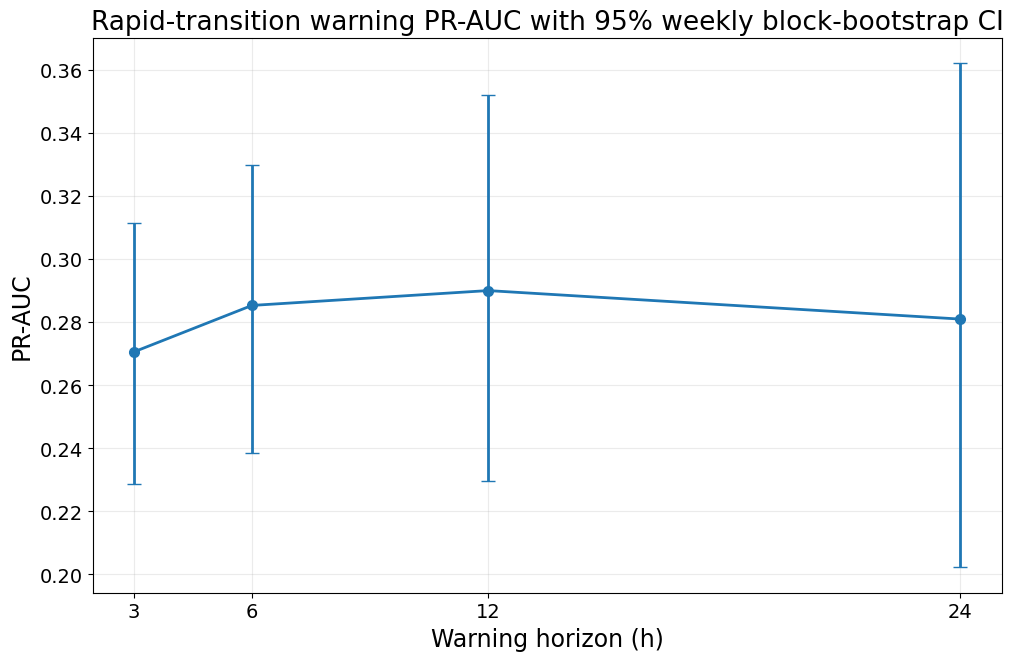

In [32]:

# ============================================================
# CELL 30 — Early-warning block-bootstrap CIs
# ============================================================
cls_ci_rows=[]
for h in CLS_HORIZONS:
    d=cls_confirm_pred[cls_confirm_pred["horizon_h"]==h]
    stats=bootstrap_classification(
        d.index,d["y_event"].to_numpy(int),d["prob_primary_warning"].to_numpy(float),
        reps=BOOTSTRAP_REPS,seed=SEED+100+h
    )
    cls_ci_rows.append({"horizon_h":h,"model":PRIMARY_CLS_MODEL,**stats})
cls_warning_ci=pd.DataFrame(cls_ci_rows)
cls_warning_ci.to_csv(TABLE_DIR/"classification_weekly_block_bootstrap_ci.csv",index=False)
display(cls_warning_ci)

fig,ax=plt.subplots(figsize=(10,6.5),constrained_layout=True)
x=cls_warning_ci["horizon_h"].to_numpy()
y=cls_warning_ci["pr_auc"].to_numpy()
yerr=np.vstack([
    y-cls_warning_ci["pr_auc_ci_low"].to_numpy(),
    cls_warning_ci["pr_auc_ci_high"].to_numpy()-y
])
ax.errorbar(x,y,yerr=yerr,marker="o",capsize=5)
ax.set_xlabel("Warning horizon (h)")
ax.set_ylabel("PR-AUC")
ax.set_title("Rapid-transition warning PR-AUC with 95% weekly block-bootstrap CI")
ax.set_xticks(CLS_HORIZONS); ax.grid(alpha=0.25)
save_figure(fig,"Fig15_warning_pr_auc_bootstrap_ci")
plt.show()


,state,horizon_h,skill_mse_vs_persistence,ci95_low,ci95_high,calendar_week_blocks,n_hours
0,S1,1,0.062557,0.055283,0.069989,259,15674
1,S3,1,0.072466,0.058073,0.087980,197,2956
2,S4,1,0.052989,0.043035,0.063157,259,8705
3,S5,1,0.055332,0.041966,0.068973,260,6829
4,S6,1,0.064953,0.051814,0.078756,257,7032
5,S7,1,0.289987,0.189664,0.356596,158,2561
6,S1,3,0.140538,0.126246,0.154951,259,15673
7,S3,3,0.160525,0.134806,0.185725,197,2956
8,S4,3,0.131261,0.111667,0.151278,259,8702
9,S5,3,0.100355,0.078500,0.120455,260,6827


,state,horizon_h,transition_rate,ci95_low,ci95_high,calendar_week_blocks,n_hours
0,S1,3,0.022714,0.019598,0.026122,259,15673
1,S3,3,0.021989,0.015560,0.029439,197,2956
2,S4,3,0.050908,0.043815,0.057895,259,8702
3,S5,3,0.091548,0.081000,0.103042,260,6827
4,S6,3,0.068554,0.058443,0.079360,257,7031
5,S7,3,0.302580,0.270204,0.333719,158,2558
6,S1,6,0.025715,0.021908,0.030427,259,15672
7,S3,6,0.023342,0.015776,0.032072,197,2956
8,S4,6,0.060725,0.051580,0.070798,259,8695
9,S5,6,0.094812,0.082908,0.106790,260,6824


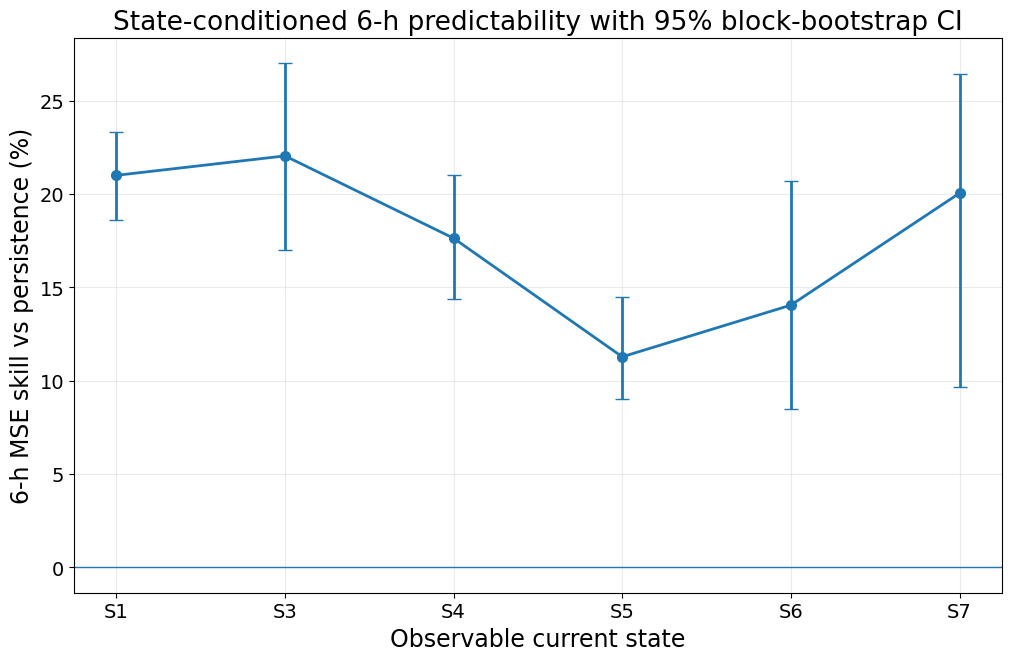

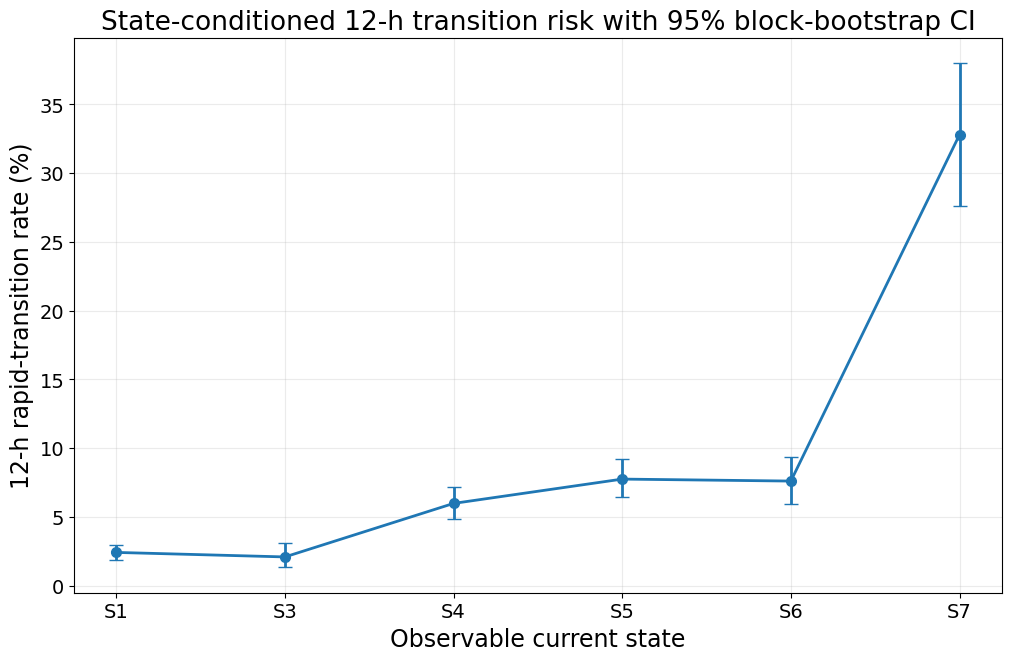

In [33]:
# ============================================================
# CELL 30B — State-conditioned weekly block-bootstrap uncertainty
# ============================================================
state_reg_ci_rows = []
state_risk_ci_rows = []

for h in REG_HORIZONS:
    d = reg_confirm_pred[
        reg_confirm_pred["horizon_h"] == h
    ].join(
        state_assignment[["state"]],
        how="left",
    ).dropna(subset=["state"])

    for state, ds in d.groupby("state"):
        skill, lo, hi, nblocks = bootstrap_regression_skill(
            ds.index,
            ds["y_delta"],
            ds["pred_primary_single"],
            reps=BOOTSTRAP_REPS,
            seed=SEED + 5000 + 100*h + sum(map(ord, state)),
        )

        state_reg_ci_rows.append({
            "state": state,
            "horizon_h": h,
            "skill_mse_vs_persistence": skill,
            "ci95_low": lo,
            "ci95_high": hi,
            "calendar_week_blocks": nblocks,
            "n_hours": len(ds),
        })


for h in CLS_HORIZONS:
    d = cls_confirm_pred[
        cls_confirm_pred["horizon_h"] == h
    ].join(
        state_assignment[["state"]],
        how="left",
    ).dropna(subset=["state"])

    for state, ds in d.groupby("state"):
        risk, lo, hi, nblocks = bootstrap_event_rate(
            ds.index,
            ds["y_event"],
            reps=BOOTSTRAP_REPS,
            seed=SEED + 7000 + 100*h + sum(map(ord, state)),
        )

        state_risk_ci_rows.append({
            "state": state,
            "horizon_h": h,
            "transition_rate": risk,
            "ci95_low": lo,
            "ci95_high": hi,
            "calendar_week_blocks": nblocks,
            "n_hours": len(ds),
        })


state_reg_ci = pd.DataFrame(state_reg_ci_rows)
state_risk_ci = pd.DataFrame(state_risk_ci_rows)

state_reg_ci.to_csv(
    TABLE_DIR / "state_conditioned_regression_skill_bootstrap_ci.csv",
    index=False,
)
state_risk_ci.to_csv(
    TABLE_DIR / "state_conditioned_transition_rate_bootstrap_ci.csv",
    index=False,
)

display(state_reg_ci)
display(state_risk_ci)


def state_sort_key(s):
    try:
        return int(str(s).replace("S", ""))
    except Exception:
        return str(s)


# Representative 6-h skill with uncertainty
plot_reg = (
    state_reg_ci[state_reg_ci["horizon_h"] == 6]
    .copy()
    .sort_values("state", key=lambda x: x.map(state_sort_key))
)

x = np.arange(len(plot_reg))
y = 100 * plot_reg["skill_mse_vs_persistence"].to_numpy()
yerr = np.vstack([
    y - 100 * plot_reg["ci95_low"].to_numpy(),
    100 * plot_reg["ci95_high"].to_numpy() - y,
])

fig, ax = plt.subplots(figsize=(10, 6.5), constrained_layout=True)
ax.errorbar(
    x,
    y,
    yerr=yerr,
    marker="o",
    capsize=5,
)
ax.axhline(0, linewidth=1)
ax.set_xticks(x)
ax.set_xticklabels(plot_reg["state"])
ax.set_xlabel("Observable current state")
ax.set_ylabel("6-h MSE skill vs persistence (%)")
ax.set_title("State-conditioned 6-h predictability with 95% block-bootstrap CI")
ax.grid(alpha=0.25)
save_figure(fig, "Fig15B_state_skill_6h_bootstrap_ci")
plt.show()


# Representative 12-h transition risk with uncertainty
plot_risk = (
    state_risk_ci[state_risk_ci["horizon_h"] == 12]
    .copy()
    .sort_values("state", key=lambda x: x.map(state_sort_key))
)

x = np.arange(len(plot_risk))
y = 100 * plot_risk["transition_rate"].to_numpy()
yerr = np.vstack([
    y - 100 * plot_risk["ci95_low"].to_numpy(),
    100 * plot_risk["ci95_high"].to_numpy() - y,
])

fig, ax = plt.subplots(figsize=(10, 6.5), constrained_layout=True)
ax.errorbar(
    x,
    y,
    yerr=yerr,
    marker="o",
    capsize=5,
)
ax.set_xticks(x)
ax.set_xticklabels(plot_risk["state"])
ax.set_xlabel("Observable current state")
ax.set_ylabel("12-h rapid-transition rate (%)")
ax.set_title("State-conditioned 12-h transition risk with 95% block-bootstrap CI")
ax.grid(alpha=0.25)
save_figure(fig, "Fig15C_state_transition_risk_12h_bootstrap_ci")
plt.show()


,volatility_decile,decile_number,horizon_h,n,dphi_mae,dphi_rmse,phi_mae,phi_rmse,phi_r2,skill_mse_vs_persistence,direction_accuracy
0,D1,1,1,2021,2.379551,3.083797,2.379551,3.083797,0.999666,0.065928,0.601602
1,D2,2,1,2721,2.509514,3.239377,2.509514,3.239377,0.999649,0.057220,0.578830
2,D3,3,1,3096,2.481935,3.206428,2.481935,3.206428,0.999665,0.073441,0.620216
3,D4,4,1,3592,2.519196,3.285351,2.519196,3.285351,0.999649,0.056279,0.597691
4,D5,5,1,3864,2.641779,3.443770,2.641779,3.443770,0.999616,0.056913,0.581279
5,D6,6,1,4623,2.628919,3.393853,2.628919,3.393853,0.999643,0.056895,0.588184
6,D7,7,1,5204,2.770785,3.683911,2.770785,3.683911,0.999553,0.058797,0.587561
7,D8,8,1,5864,2.860328,3.758127,2.860328,3.758127,0.999564,0.054772,0.577966
8,D9,9,1,6922,3.017400,4.076066,3.017400,4.076066,0.999463,0.077577,0.584051
9,D10,10,1,5782,3.984475,6.305592,3.984475,6.305592,0.998933,0.255588,0.605594


,volatility_decile,decile_number,horizon_h,n,transition_rate,mean_warning_probability
0,D1,1,3,2021,0.017813,0.018091
1,D2,2,3,2719,0.024641,0.021085
2,D3,3,3,3096,0.022287,0.022957
3,D4,4,3,3592,0.023664,0.024570
4,D5,5,3,3864,0.035973,0.026965
5,D6,6,3,4623,0.036340,0.028810
6,D7,7,3,5203,0.047280,0.031262
7,D8,8,3,5863,0.053897,0.036880
8,D9,9,3,6920,0.080058,0.046890
9,D10,10,3,5778,0.179993,0.135397


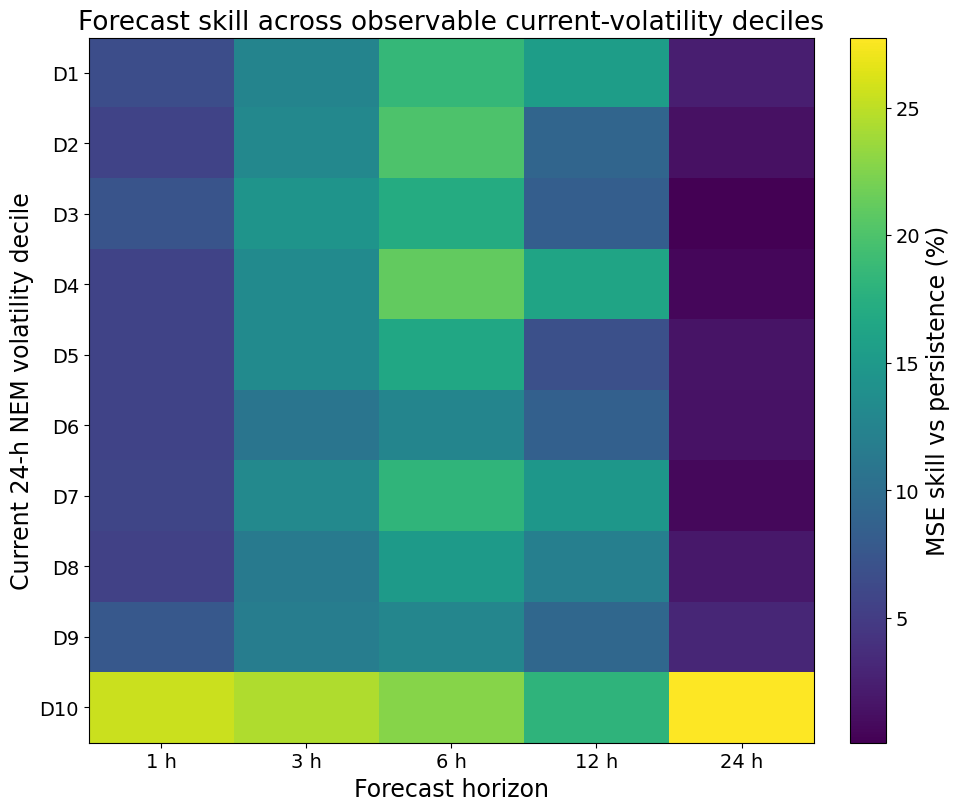

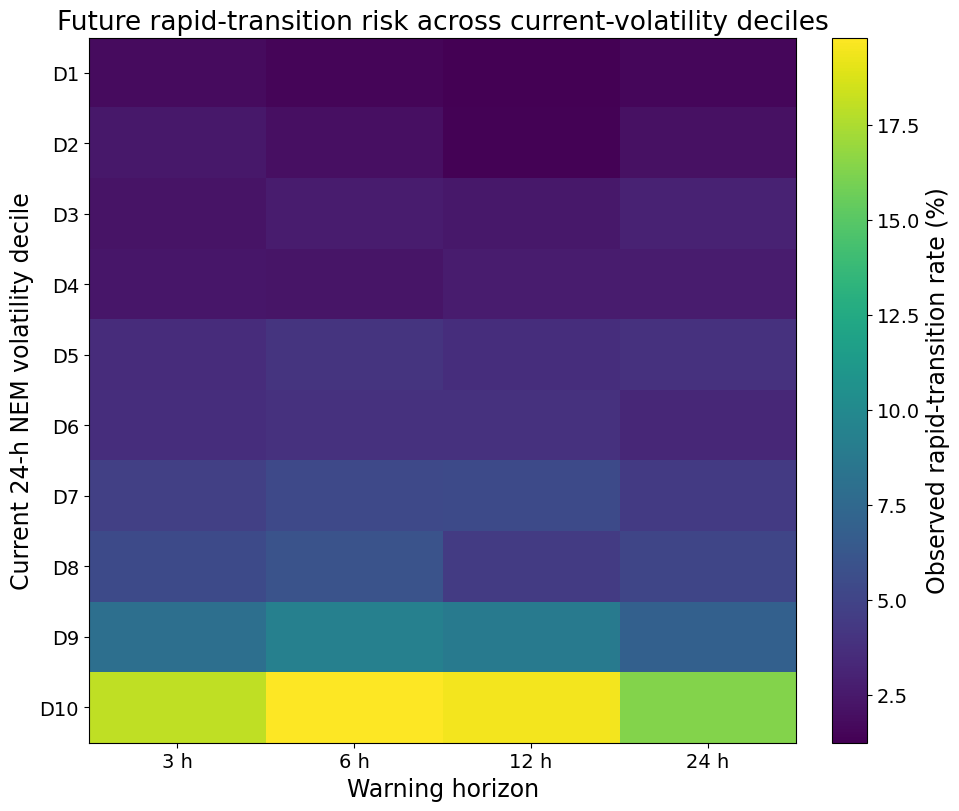

In [34]:
# ============================================================
# CELL 30C — Current 24-h volatility deciles: predictability and transition risk
# ============================================================
dev_vol = final_features.loc[
    (final_features.index >= MODEL_START)
    & (final_features.index <= DEV_END)
    & final_features["phi_roll_std_24"].notna(),
    "phi_roll_std_24",
].astype(float)

# Freeze development-only boundaries.
vol_q = dev_vol.quantile(np.arange(0.1, 1.0, 0.1)).to_numpy(dtype=float)
vol_edges = np.concatenate(([-np.inf], vol_q, [np.inf]))

# Guard against pathological duplicated boundaries.
vol_edges = np.unique(vol_edges)

VOL_DECILE_COUNT = len(vol_edges) - 1
vol_labels = [f"D{i}" for i in range(1, VOL_DECILE_COUNT + 1)]

vol_threshold_table = pd.DataFrame({
    "edge_index": np.arange(len(vol_edges)),
    "edge_value": vol_edges,
})
vol_threshold_table.to_csv(
    TABLE_DIR / "current_volatility_decile_edges_development.csv",
    index=False,
)


def assign_volatility_bin(series):
    return pd.cut(
        series.astype(float),
        bins=vol_edges,
        labels=vol_labels,
        include_lowest=True,
        right=True,
    )


confirm_vol_bin = assign_volatility_bin(
    final_features.loc[CONFIRM_START:CONFIRM_END, "phi_roll_std_24"]
)

vol_reg_rows = []
vol_risk_rows = []

for h in REG_HORIZONS:
    d = reg_confirm_pred[
        reg_confirm_pred["horizon_h"] == h
    ].copy()
    d["volatility_decile"] = confirm_vol_bin.reindex(d.index)

    for decile, ds in d.dropna(subset=["volatility_decile"]).groupby(
        "volatility_decile",
        observed=True,
    ):
        m = regression_metrics(
            ds["y_delta"],
            ds["pred_primary_single"],
            ds["phi_t"],
        )
        vol_reg_rows.append({
            "volatility_decile": str(decile),
            "decile_number": int(str(decile).replace("D", "")),
            "horizon_h": h,
            **m,
        })


for h in CLS_HORIZONS:
    d = cls_confirm_pred[
        cls_confirm_pred["horizon_h"] == h
    ].copy()
    d["volatility_decile"] = confirm_vol_bin.reindex(d.index)

    for decile, ds in d.dropna(subset=["volatility_decile"]).groupby(
        "volatility_decile",
        observed=True,
    ):
        vol_risk_rows.append({
            "volatility_decile": str(decile),
            "decile_number": int(str(decile).replace("D", "")),
            "horizon_h": h,
            "n": len(ds),
            "transition_rate": float(ds["y_event"].mean()),
            "mean_warning_probability": float(
                ds["prob_primary_warning"].mean()
            ),
        })


vol_reg_results = pd.DataFrame(vol_reg_rows)
vol_risk_results = pd.DataFrame(vol_risk_rows)

vol_reg_results.to_csv(
    TABLE_DIR / "current_volatility_decile_regression_skill.csv",
    index=False,
)
vol_risk_results.to_csv(
    TABLE_DIR / "current_volatility_decile_transition_risk.csv",
    index=False,
)

display(vol_reg_results)
display(vol_risk_results)


# All-horizon skill heatmap
skill_heat = (
    vol_reg_results
    .pivot(
        index="volatility_decile",
        columns="horizon_h",
        values="skill_mse_vs_persistence",
    )
    .reindex(vol_labels)
)

fig, ax = plt.subplots(figsize=(9.5, 8), constrained_layout=True)
im = ax.imshow(100 * skill_heat.values, aspect="auto")
ax.set_xticks(range(len(skill_heat.columns)))
ax.set_xticklabels([f"{h} h" for h in skill_heat.columns])
ax.set_yticks(range(len(skill_heat.index)))
ax.set_yticklabels(skill_heat.index)
ax.set_xlabel("Forecast horizon")
ax.set_ylabel("Current 24-h NEM volatility decile")
ax.set_title("Forecast skill across observable current-volatility deciles")
cbar = fig.colorbar(im, ax=ax)
cbar.set_label("MSE skill vs persistence (%)")
save_figure(fig, "Fig15D_current_volatility_decile_forecast_skill")
plt.show()


# All-horizon future transition-risk heatmap
risk_heat = (
    vol_risk_results
    .pivot(
        index="volatility_decile",
        columns="horizon_h",
        values="transition_rate",
    )
    .reindex(vol_labels)
)

fig, ax = plt.subplots(figsize=(9.5, 8), constrained_layout=True)
im = ax.imshow(100 * risk_heat.values, aspect="auto")
ax.set_xticks(range(len(risk_heat.columns)))
ax.set_xticklabels([f"{h} h" for h in risk_heat.columns])
ax.set_yticks(range(len(risk_heat.index)))
ax.set_yticklabels(risk_heat.index)
ax.set_xlabel("Warning horizon")
ax.set_ylabel("Current 24-h NEM volatility decile")
ax.set_title("Future rapid-transition risk across current-volatility deciles")
cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Observed rapid-transition rate (%)")
save_figure(fig, "Fig15E_current_volatility_decile_transition_risk")
plt.show()


,horizon_h,model,reference_feature_set,candidate_feature_set,reference_skill,candidate_skill,candidate_minus_reference_skill,skill_difference_ci95_low,skill_difference_ci95_high,calendar_week_blocks
0,1,cat,A2_phi_rmse,A5_phi_rmse_rc_op,0.112977,0.133541,0.020564,0.012430,0.028926,262
1,3,cat,A2_phi_rmse,A5_phi_rmse_rc_op,0.132283,0.171887,0.039604,0.027576,0.054127,262
2,6,cat,A2_phi_rmse,A5_phi_rmse_rc_op,0.131769,0.173239,0.041470,0.026824,0.058817,262
3,12,cat,A2_phi_rmse,A5_phi_rmse_rc_op,0.119738,0.122669,0.002930,-0.017429,0.026805,262
4,24,cat,A2_phi_rmse,A5_phi_rmse_rc_op,0.070482,0.068940,-0.001542,-0.011019,0.011192,262


,horizon_h,comparison,hac_lag,mean_loss_A2_minus_A5,z,p_raw,p_holm
0,1,A5_operational_Rc_vs_A2_phi_rmse,24,0.390873,6.405064,1.503067e-10,6.012269e-10
1,3,A5_operational_Rc_vs_A2_phi_rmse,24,2.975285,7.602824,2.897381e-14,1.448690e-13
2,6,A5_operational_Rc_vs_A2_phi_rmse,24,7.573452,6.329299,2.462782e-10,7.388347e-10
3,12,A5_operational_Rc_vs_A2_phi_rmse,24,1.133324,0.314650,7.530272e-01,1.000000e+00
4,24,A5_operational_Rc_vs_A2_phi_rmse,24,-1.070671,-0.317816,7.506244e-01,1.000000e+00


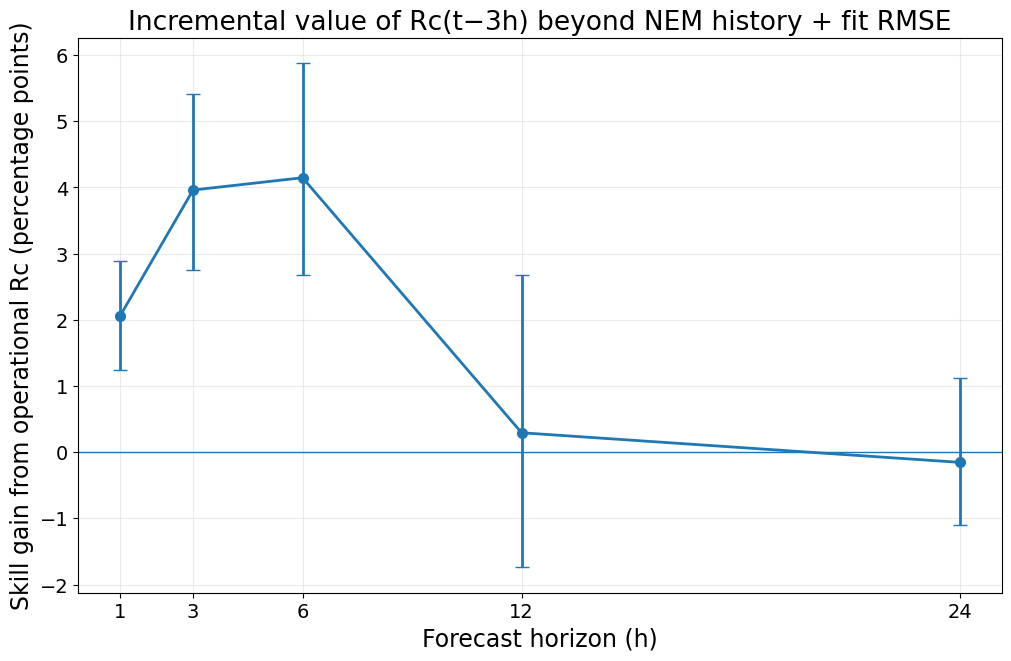

In [35]:
# ============================================================
# CELL 30D — Paired A5 vs A2 operational Rc significance
# ============================================================
RC_REFERENCE_SET = "A2_phi_rmse"
RC_CANDIDATE_SET = "A5_phi_rmse_rc_op"

rc_pair_rows = []
rc_pair_pred_parts = []
rc_hac_rows = []

for h in REG_HORIZONS:
    dev = final_features.loc[
        reg_eligible_mask(final_features, h, MODEL_START, DEV_END)
    ].copy()

    test = final_features.loc[
        reg_eligible_mask(final_features, h, CONFIRM_START, CONFIRM_END)
    ].copy()

    ref_model = make_regressor(PRIMARY_REG_MODEL)
    cand_model = make_regressor(PRIMARY_REG_MODEL)

    ref_cols = REG_FEATURE_SETS[RC_REFERENCE_SET]
    cand_cols = REG_FEATURE_SETS[RC_CANDIDATE_SET]

    ref_model.fit(
        dev[ref_cols],
        dev[f"dphi_{h}"],
    )
    cand_model.fit(
        dev[cand_cols],
        dev[f"dphi_{h}"],
    )

    pred_ref = ref_model.predict(test[ref_cols])
    pred_cand = cand_model.predict(test[cand_cols])

    m_ref = regression_metrics(
        test[f"dphi_{h}"],
        pred_ref,
        test["phi_t"],
    )
    m_cand = regression_metrics(
        test[f"dphi_{h}"],
        pred_cand,
        test["phi_t"],
    )

    skill_diff, ci_lo, ci_hi, nblocks = bootstrap_skill_difference(
        test.index,
        test[f"dphi_{h}"],
        pred_ref,
        pred_cand,
        reps=BOOTSTRAP_REPS,
        seed=SEED + 9000 + h,
    )

    loss_ref = (
        test[f"dphi_{h}"].to_numpy(dtype=float) - pred_ref
    ) ** 2
    loss_cand = (
        test[f"dphi_{h}"].to_numpy(dtype=float) - pred_cand
    ) ** 2

    hac_lag = max(DM_MIN_HAC_LAG, h - 1)
    mean_d, z, p_raw = newey_west_mean_test(
        loss_ref - loss_cand,
        hac_lag,
    )

    rc_pair_rows.append({
        "horizon_h": h,
        "model": PRIMARY_REG_MODEL,
        "reference_feature_set": RC_REFERENCE_SET,
        "candidate_feature_set": RC_CANDIDATE_SET,
        "reference_skill": m_ref["skill_mse_vs_persistence"],
        "candidate_skill": m_cand["skill_mse_vs_persistence"],
        "candidate_minus_reference_skill": skill_diff,
        "skill_difference_ci95_low": ci_lo,
        "skill_difference_ci95_high": ci_hi,
        "calendar_week_blocks": nblocks,
    })

    rc_hac_rows.append({
        "horizon_h": h,
        "comparison": "A5_operational_Rc_vs_A2_phi_rmse",
        "hac_lag": hac_lag,
        "mean_loss_A2_minus_A5": mean_d,
        "z": z,
        "p_raw": p_raw,
    })

    q = pd.DataFrame(index=test.index)
    q["horizon_h"] = h
    q["y_delta"] = test[f"dphi_{h}"].astype(float)
    q["pred_A2_phi_rmse"] = pred_ref
    q["pred_A5_phi_rmse_rc_op"] = pred_cand
    rc_pair_pred_parts.append(q)

    joblib.dump(
        ref_model,
        MODEL_DIR / f"rc_ablation_A2_{PRIMARY_REG_MODEL}_h{h}.joblib",
    )
    joblib.dump(
        cand_model,
        MODEL_DIR / f"rc_ablation_A5_{PRIMARY_REG_MODEL}_h{h}.joblib",
    )

    del ref_model, cand_model, dev, test
    gc.collect()


rc_incremental_results = pd.DataFrame(rc_pair_rows)
rc_hac_results = pd.DataFrame(rc_hac_rows)

rc_hac_results["p_holm"] = holm_adjust(
    rc_hac_results["p_raw"].to_numpy(dtype=float)
)

rc_pair_predictions = pd.concat(
    rc_pair_pred_parts
).sort_index()

rc_incremental_results.to_csv(
    TABLE_DIR / "operational_rc_incremental_skill_bootstrap.csv",
    index=False,
)
rc_hac_results.to_csv(
    TABLE_DIR / "operational_rc_incremental_hac_tests.csv",
    index=False,
)
save_frame(
    rc_pair_predictions,
    PRED_DIR / "operational_rc_A2_vs_A5_confirmation_predictions.parquet",
)

display(rc_incremental_results)
display(rc_hac_results)


x = rc_incremental_results["horizon_h"].to_numpy()
y = 100 * rc_incremental_results[
    "candidate_minus_reference_skill"
].to_numpy()

yerr = np.vstack([
    y - 100 * rc_incremental_results[
        "skill_difference_ci95_low"
    ].to_numpy(),
    100 * rc_incremental_results[
        "skill_difference_ci95_high"
    ].to_numpy() - y,
])

fig, ax = plt.subplots(figsize=(10, 6.5), constrained_layout=True)
ax.errorbar(
    x,
    y,
    yerr=yerr,
    marker="o",
    capsize=5,
)
ax.axhline(0, linewidth=1)
ax.set_xlabel("Forecast horizon (h)")
ax.set_ylabel("Skill gain from operational Rc (percentage points)")
ax.set_title("Incremental value of Rc(t−3h) beyond NEM history + fit RMSE")
ax.set_xticks(REG_HORIZONS)
ax.grid(alpha=0.25)
save_figure(fig, "Fig15F_operational_rc_incremental_skill")
plt.show()


In [36]:
# ============================================================
# CELL 31 — SHAP helpers and scientifically aligned explanatory systems
# ============================================================
def sample_df(df, n, seed):
    return df if len(df) <= n else df.sample(n=n, random_state=seed)


def tree_shap(model, X):
    explainer = shap.TreeExplainer(model)
    values = explainer.shap_values(X)

    if isinstance(values, list):
        values = values[-1]

    return np.asarray(values)


def linear_pipeline_shap(pipe, X, background_X=None, background_n=1000):
    """
    Exact linear-model SHAP on the transformed feature space of the
    imputer + scaler + logistic-regression pipeline.
    """
    imputer = pipe.named_steps["imputer"]
    scaler = pipe.named_steps["scaler"]
    model = pipe.named_steps["model"]

    Xt = imputer.transform(X)
    Xt = scaler.transform(Xt)

    if background_X is None:
        background_X = X

    Xbg = imputer.transform(background_X)
    Xbg = scaler.transform(Xbg)

    rng = np.random.default_rng(SEED)
    if len(Xbg) > background_n:
        bg_idx = rng.choice(len(Xbg), background_n, replace=False)
        background = Xbg[bg_idx]
    else:
        background = Xbg

    try:
        explainer = shap.LinearExplainer(
            model,
            background,
        )
        values = explainer.shap_values(Xt)

        if isinstance(values, list):
            values = values[-1]

        return np.asarray(values)

    except Exception as exc:
        # Version-robust exact linear fallback under a mean-background
        # interventional reference: contribution_j = beta_j (x_j - E[x_j]).
        warnings.warn(
            f"shap.LinearExplainer fallback used: {exc}"
        )
        coef = np.asarray(model.coef_).reshape(-1)
        bg_mean = np.nanmean(background, axis=0)
        return (Xt - bg_mean) * coef


def feature_family(feature):
    if feature.startswith("phi_"):
        return "NEM history"
    if feature.startswith("rmse_"):
        return "Fit RMSE"
    if feature.startswith("nm_") or feature == "n_active_nm":
        return "NM network"
    if feature.startswith("kappa_"):
        return "Kappa network"
    if feature in RC_OPERATIONAL:
        return "Rc operational"
    if feature in RC_CURRENT:
        return "Rc current"
    return "Other"


# ------------------------------------------------------------
# Regression XAI MUST explain the actual development-selected
# primary model and ONLY the predictors that model uses.
# ------------------------------------------------------------
REG_SHAP_FEATURES = REG_FEATURE_SETS[PRIMARY_REG_FEATURE_SET]


# ------------------------------------------------------------
# Classification XAI:
# - if one individual model is primary, explain that exact model;
# - if the probability ensemble is primary, explain the strongest
#   individual development-CV member and state this explicitly.
# ------------------------------------------------------------
if PRIMARY_CLS_MODEL == "mean_probability_ensemble":
    individual_rank = cls_rank[
        cls_rank["model"].isin([
            "logistic_full",
            "lgbm",
            "xgb",
            "cat",
        ])
    ].sort_values(
        ["mean_pr_auc_all_horizons", "min_pr_auc_any_horizon"],
        ascending=False,
    )

    CLS_EXPLAIN_MODEL = str(individual_rank.iloc[0]["model"])
    XAI_SYSTEM_NOTE = (
        "The primary warning system is a mean probability ensemble. "
        f"SHAP is therefore reported for its strongest individual "
        f"development-CV member: {CLS_EXPLAIN_MODEL}."
    )
else:
    CLS_EXPLAIN_MODEL = PRIMARY_CLS_MODEL
    XAI_SYSTEM_NOTE = (
        f"Classification SHAP explains the exact primary warning model: "
        f"{CLS_EXPLAIN_MODEL}."
    )

CLS_SHAP_FEATURES = CLS_FEATURE_SETS["C3_full_operational"]


def classification_shap_values(model_name, fitted_model, X, background_X=None):
    if model_name == "logistic_full":
        return linear_pipeline_shap(
            fitted_model,
            X[CLS_SHAP_FEATURES],
            background_X=(
                None
                if background_X is None
                else background_X[CLS_SHAP_FEATURES]
            ),
        )

    return tree_shap(
        fitted_model,
        X[CLS_SHAP_FEATURES],
    )


with open(LOG_DIR / "xai_system_note.txt", "w") as f:
    f.write(
        "Regression SHAP explains the exact primary model: "
        f"{PRIMARY_REG_MODEL} / {PRIMARY_REG_FEATURE_SET}.\n"
        + XAI_SYSTEM_NOTE
    )

print(
    "Regression SHAP:",
    PRIMARY_REG_MODEL,
    PRIMARY_REG_FEATURE_SET,
)
print("Classification SHAP:", CLS_EXPLAIN_MODEL)
print(XAI_SYSTEM_NOTE)


Regression SHAP: cat A5_phi_rmse_rc_op
Classification SHAP: logistic_full
Classification SHAP explains the exact primary warning model: logistic_full.


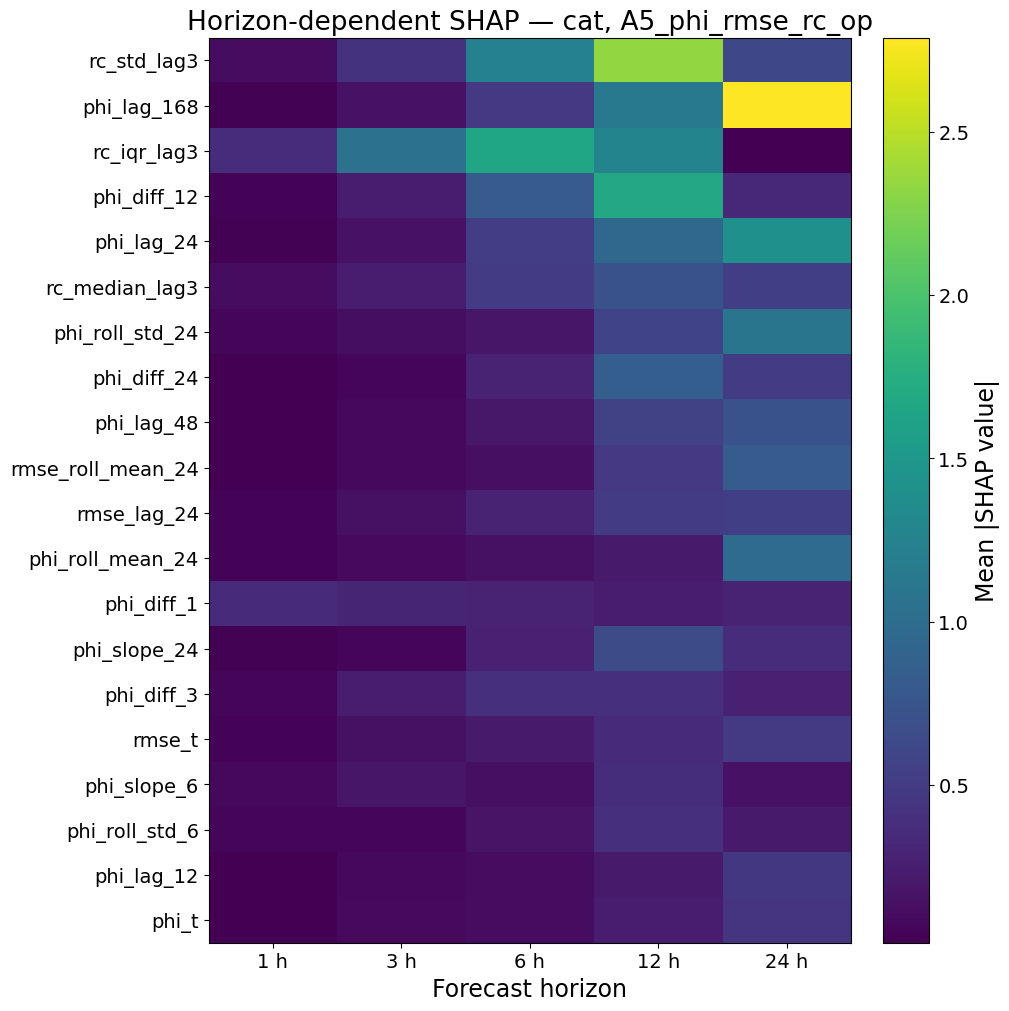

In [37]:
# ============================================================
# CELL 32 — Horizon-dependent regression SHAP
# CORRECTED: explains the actual selected primary regression model
# ============================================================
reg_shap_rows = []

for h in REG_HORIZONS:
    test = final_features.loc[
        reg_eligible_mask(
            final_features,
            h,
            CONFIRM_START,
            CONFIRM_END,
        )
    ].copy()

    X = sample_df(
        test[REG_SHAP_FEATURES],
        SHAP_GLOBAL_N,
        SEED + h,
    )

    # IMPORTANT:
    # ("primary", h) is the exact selected feature-set model,
    # not the full A6 benchmark model.
    model = final_reg_models[("primary", h)]

    sv = tree_shap(
        model,
        X,
    )

    imp = np.nanmean(
        np.abs(sv),
        axis=0,
    )

    for feature, value in zip(
        REG_SHAP_FEATURES,
        imp,
    ):
        reg_shap_rows.append({
            "horizon_h": h,
            "feature": feature,
            "family": feature_family(feature),
            "mean_abs_shap": float(value),
            "explained_model": PRIMARY_REG_MODEL,
            "explained_feature_set": PRIMARY_REG_FEATURE_SET,
        })


reg_shap = pd.DataFrame(reg_shap_rows)
reg_shap.to_csv(
    SHAP_DIR / "regression_shap_horizon.csv",
    index=False,
)

top_features = (
    reg_shap
    .groupby("feature")["mean_abs_shap"]
    .mean()
    .sort_values(ascending=False)
    .head(20)
    .index
)

heat = (
    reg_shap[
        reg_shap["feature"].isin(top_features)
    ]
    .pivot(
        index="feature",
        columns="horizon_h",
        values="mean_abs_shap",
    )
    .reindex(top_features)
)

fig, ax = plt.subplots(
    figsize=(10, 10),
    constrained_layout=True,
)
im = ax.imshow(
    heat.values,
    aspect="auto",
)

ax.set_xticks(range(len(heat.columns)))
ax.set_xticklabels(
    [f"{h} h" for h in heat.columns]
)

ax.set_yticks(range(len(heat.index)))
ax.set_yticklabels(heat.index)

ax.set_xlabel("Forecast horizon")
ax.set_title(
    f"Horizon-dependent SHAP — "
    f"{PRIMARY_REG_MODEL}, {PRIMARY_REG_FEATURE_SET}"
)

cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Mean |SHAP value|")

save_figure(
    fig,
    "Fig16_regression_shap_horizon_heatmap",
)
plt.show()


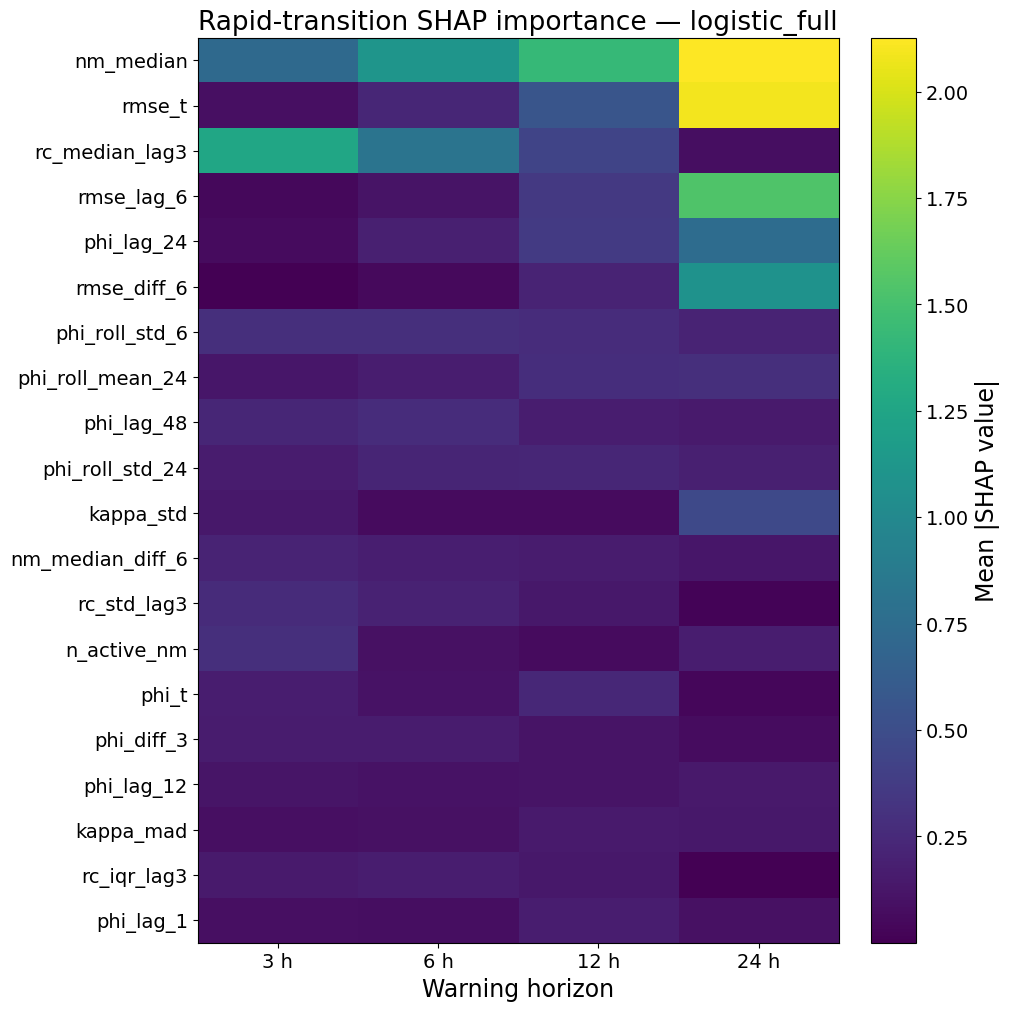

In [38]:
# ============================================================
# CELL 33 — Horizon-dependent transition-warning SHAP
# ============================================================
cls_shap_rows = []

for h in CLS_HORIZONS:
    test = final_features.loc[
        cls_eligible_mask(
            final_features,
            h,
            CONFIRM_START,
            CONFIRM_END,
        )
    ].copy()

    X = sample_df(
        test[CLS_SHAP_FEATURES],
        SHAP_GLOBAL_N,
        SEED + 1000 + h,
    )

    fitted_model = final_cls_models[
        (CLS_EXPLAIN_MODEL, h)
    ]

    background_X = sample_df(
        final_features.loc[MODEL_START:DEV_END, CLS_SHAP_FEATURES],
        1000,
        SEED + 2000 + h,
    )

    sv = classification_shap_values(
        CLS_EXPLAIN_MODEL,
        fitted_model,
        X,
        background_X=background_X,
    )

    imp = np.nanmean(
        np.abs(sv),
        axis=0,
    )

    for feature, value in zip(
        CLS_SHAP_FEATURES,
        imp,
    ):
        cls_shap_rows.append({
            "horizon_h": h,
            "feature": feature,
            "family": feature_family(feature),
            "mean_abs_shap": float(value),
            "explained_model": CLS_EXPLAIN_MODEL,
            "primary_warning_system": PRIMARY_CLS_MODEL,
        })


cls_shap = pd.DataFrame(cls_shap_rows)
cls_shap.to_csv(
    SHAP_DIR / "classification_shap_horizon.csv",
    index=False,
)

top_features = (
    cls_shap
    .groupby("feature")["mean_abs_shap"]
    .mean()
    .sort_values(ascending=False)
    .head(20)
    .index
)

heat = (
    cls_shap[
        cls_shap["feature"].isin(top_features)
    ]
    .pivot(
        index="feature",
        columns="horizon_h",
        values="mean_abs_shap",
    )
    .reindex(top_features)
)

fig, ax = plt.subplots(
    figsize=(10, 10),
    constrained_layout=True,
)

im = ax.imshow(
    heat.values,
    aspect="auto",
)

ax.set_xticks(range(len(heat.columns)))
ax.set_xticklabels(
    [f"{h} h" for h in heat.columns]
)

ax.set_yticks(range(len(heat.index)))
ax.set_yticklabels(heat.index)

ax.set_xlabel("Warning horizon")
ax.set_title(
    f"Rapid-transition SHAP importance — {CLS_EXPLAIN_MODEL}"
)

cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Mean |SHAP value|")

save_figure(
    fig,
    "Fig17_classification_shap_horizon_heatmap",
)
plt.show()


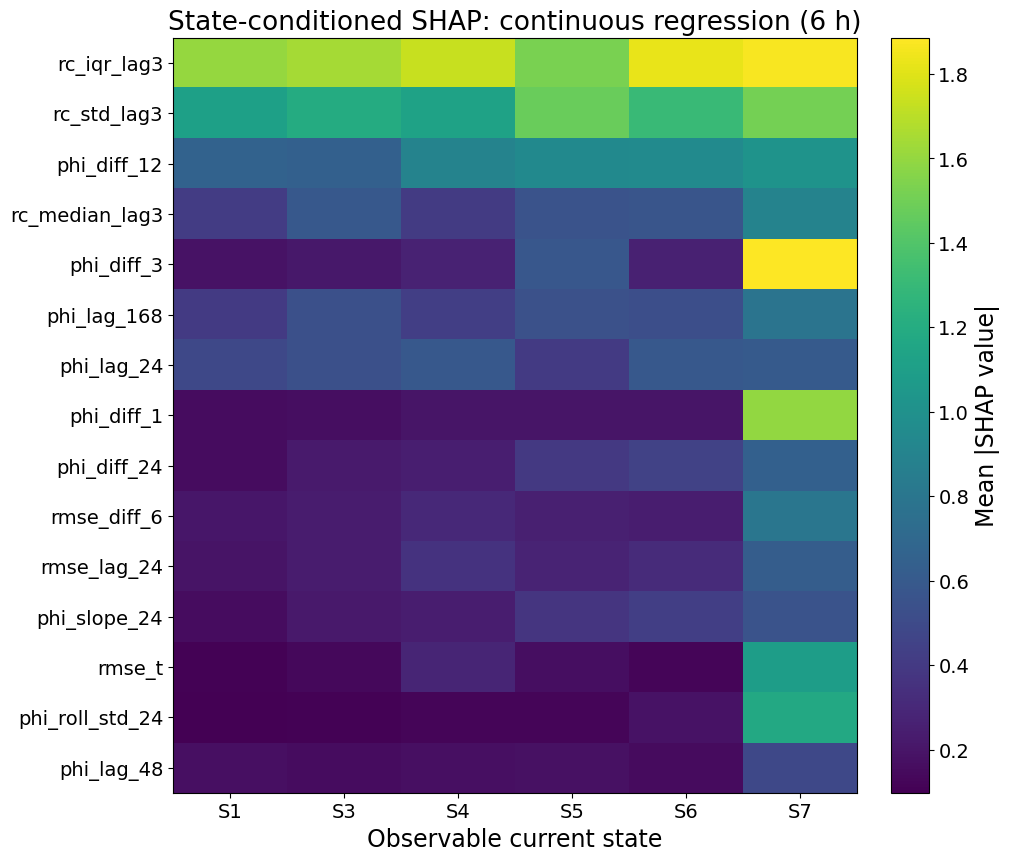

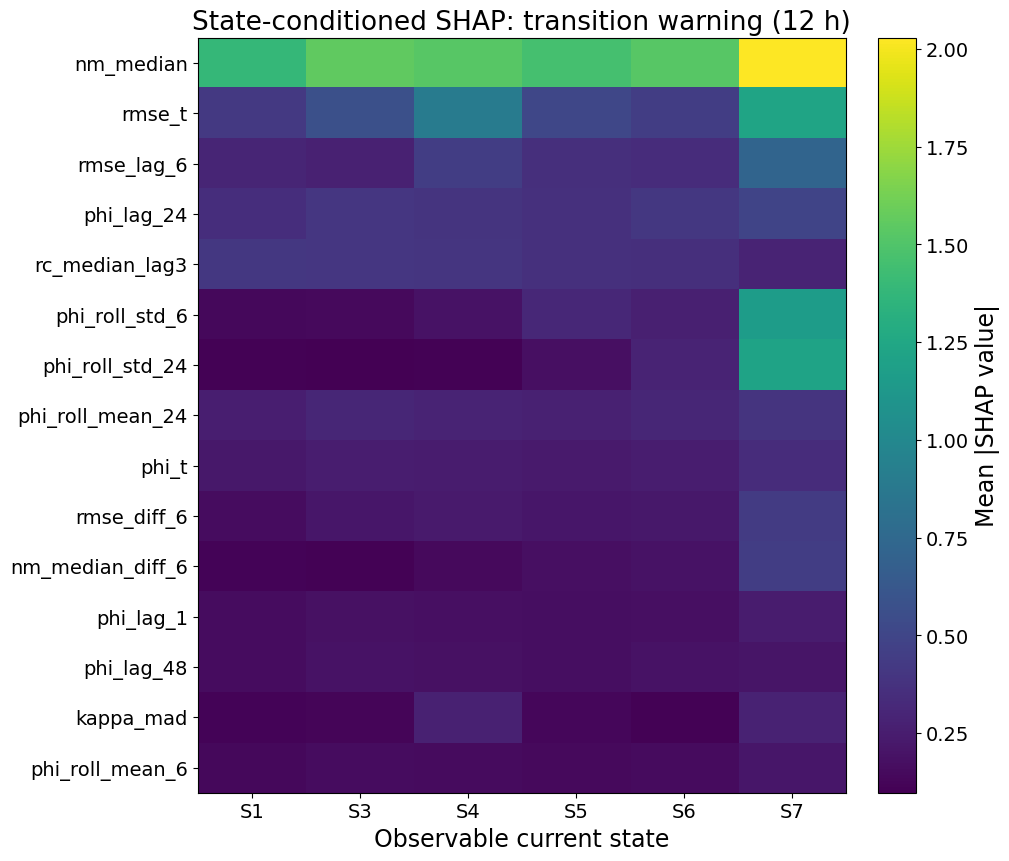

In [39]:
# ============================================================
# CELL 34 — State-conditioned SHAP at representative horizons
# CORRECTED: regression SHAP uses the exact primary regression model
# ============================================================
state_shap_rows = []

# ------------------------------------------------------------
# Regression: representative 6-h horizon.
# ------------------------------------------------------------
h = STATE_SHAP_REG_HORIZON

test = final_features.loc[
    reg_eligible_mask(
        final_features,
        h,
        CONFIRM_START,
        CONFIRM_END,
    )
].join(
    state_assignment[["state"]],
    how="left",
).dropna(subset=["state"])

reg_model = final_reg_models[
    ("primary", h)
]

for state, ds in test.groupby("state"):
    X = sample_df(
        ds[REG_SHAP_FEATURES],
        SHAP_STATE_N,
        SEED + h + sum(map(ord, state)),
    )

    sv = tree_shap(
        reg_model,
        X,
    )

    imp = np.nanmean(
        np.abs(sv),
        axis=0,
    )

    for feature, value in zip(
        REG_SHAP_FEATURES,
        imp,
    ):
        state_shap_rows.append({
            "task": "continuous_regression",
            "horizon_h": h,
            "state": state,
            "feature": feature,
            "family": feature_family(feature),
            "mean_abs_shap": float(value),
            "explained_model": PRIMARY_REG_MODEL,
            "explained_feature_set": PRIMARY_REG_FEATURE_SET,
        })


# ------------------------------------------------------------
# Classification: representative 12-h warning horizon.
# ------------------------------------------------------------
h = STATE_SHAP_CLS_HORIZON

test = final_features.loc[
    cls_eligible_mask(
        final_features,
        h,
        CONFIRM_START,
        CONFIRM_END,
    )
].join(
    state_assignment[["state"]],
    how="left",
).dropna(subset=["state"])

cls_model = final_cls_models[
    (CLS_EXPLAIN_MODEL, h)
]

for state, ds in test.groupby("state"):
    X = sample_df(
        ds[CLS_SHAP_FEATURES],
        SHAP_STATE_N,
        SEED + h + sum(map(ord, state)),
    )

    background_X = sample_df(
        final_features.loc[MODEL_START:DEV_END, CLS_SHAP_FEATURES],
        1000,
        SEED + 3000 + h,
    )

    sv = classification_shap_values(
        CLS_EXPLAIN_MODEL,
        cls_model,
        X,
        background_X=background_X,
    )

    imp = np.nanmean(
        np.abs(sv),
        axis=0,
    )

    for feature, value in zip(
        CLS_SHAP_FEATURES,
        imp,
    ):
        state_shap_rows.append({
            "task": "transition_warning",
            "horizon_h": h,
            "state": state,
            "feature": feature,
            "family": feature_family(feature),
            "mean_abs_shap": float(value),
            "explained_model": CLS_EXPLAIN_MODEL,
            "primary_warning_system": PRIMARY_CLS_MODEL,
        })


state_shap = pd.DataFrame(state_shap_rows)

state_shap.to_csv(
    SHAP_DIR / "state_conditioned_shap.csv",
    index=False,
)


for task, h in [
    ("continuous_regression", STATE_SHAP_REG_HORIZON),
    ("transition_warning", STATE_SHAP_CLS_HORIZON),
]:
    d = state_shap[
        (state_shap["task"] == task)
        & (state_shap["horizon_h"] == h)
    ]

    top = (
        d.groupby("feature")["mean_abs_shap"]
        .mean()
        .sort_values(ascending=False)
        .head(15)
        .index
    )

    heat = (
        d[
            d["feature"].isin(top)
        ]
        .pivot(
            index="feature",
            columns="state",
            values="mean_abs_shap",
        )
        .reindex(top)
    )

    fig, ax = plt.subplots(
        figsize=(10, 8.5),
        constrained_layout=True,
    )

    im = ax.imshow(
        heat.values,
        aspect="auto",
    )

    ax.set_xticks(
        range(len(heat.columns))
    )
    ax.set_xticklabels(
        heat.columns
    )

    ax.set_yticks(
        range(len(heat.index))
    )
    ax.set_yticklabels(
        heat.index
    )

    ax.set_xlabel(
        "Observable current state"
    )
    ax.set_title(
        f"State-conditioned SHAP: "
        f"{task.replace('_', ' ')} ({h} h)"
    )

    cbar = fig.colorbar(
        im,
        ax=ax,
    )
    cbar.set_label(
        "Mean |SHAP value|"
    )

    save_figure(
        fig,
        f"Fig18_state_shap_{task}_h{h}",
    )
    plt.show()


In [40]:

# ============================================================
# CELL 35 — Build train-through-2025 features
# ============================================================
DEPLOY_FEATURE_PATH=CACHE_DIR/"features_train1964_2025_jan2026.parquet"
if RESUME and (DEPLOY_FEATURE_PATH.exists() or DEPLOY_FEATURE_PATH.with_suffix(".pkl").exists()):
    deploy_features=load_frame(DEPLOY_FEATURE_PATH)
else:
    deploy_features,deploy_nm_base,deploy_kap_base=build_feature_frame(
        master,MODEL_START,CONFIRM_END,MODEL_START,DEPLOY_END
    )
    save_frame(deploy_features,DEPLOY_FEATURE_PATH)
    pd.DataFrame({
        "station":STATIONS,
        "nm_training_median_1964_2025":[deploy_nm_base[f"nm_{s}"] for s in STATIONS],
        "kappa_training_median_1964_2025":[deploy_kap_base[f"kap_{s}"] for s in STATIONS],
    }).to_csv(TABLE_DIR/"deployment_station_normalization_1964_2025.csv",index=False)
print(deploy_features.index.min(),"to",deploy_features.index.max())


1964-01-01 00:00:00 to 2026-01-31 23:00:00


In [41]:
# ============================================================
# CELL 36 — January 2026 continuous + warning evaluation
# FINAL Q1 VERSION: frozen methodology + temporal-OOF recalibration
# ============================================================
deploy_reg_rows = []
deploy_reg_parts = []
deploy_cls_rows = []
deploy_cls_parts = []
deploy_calibration_audit_rows = []
deploy_event_rows = []
deploy_event_detail_parts = []

# ------------------------------------------------------------
# Continuous forecasting — unchanged methodology.
# ------------------------------------------------------------
for h in REG_HORIZONS:
    train = deploy_features.loc[
        reg_eligible_mask(
            deploy_features,
            h,
            MODEL_START,
            CONFIRM_END,
        )
    ].copy()

    test = deploy_features.loc[
        reg_eligible_mask(
            deploy_features,
            h,
            DEPLOY_START,
            DEPLOY_END,
        )
    ].copy()

    model = make_regressor(
        PRIMARY_REG_MODEL
    )

    cols = REG_FEATURE_SETS[
        PRIMARY_REG_FEATURE_SET
    ]

    model.fit(
        train[cols],
        train[f"dphi_{h}"],
    )

    pred = model.predict(
        test[cols]
    )

    deploy_reg_rows.append(
        reg_metric_row(
            PRIMARY_REG_MODEL,
            PRIMARY_REG_FEATURE_SET,
            h,
            test,
            pred,
        )
    )

    p = pd.DataFrame(
        index=test.index
    )

    p["horizon_h"] = h
    p["phi_t"] = test["phi_t"].astype(float)
    p["y_delta"] = test[f"dphi_{h}"].astype(float)
    p["pred_delta"] = pred

    deploy_reg_parts.append(p)

    joblib.dump(
        model,
        MODEL_DIR / f"deployment_reg_primary_h{h}.joblib",
    )

    del model, train, test
    gc.collect()


# ------------------------------------------------------------
# January-2026 warning calibration folds.
#
# Methodology is frozen; the calibration pool is simply updated with all
# information available through 2025. 2026 is never used for fitting.
# ------------------------------------------------------------
DEPLOY_CALIBRATION_FOLDS = [
    dict(f) for f in FOLDS
]

DEPLOY_CALIBRATION_FOLDS.append({
    "fold": 7,
    "train_start": MODEL_START,
    "train_end": DEV_END,
    "val_start": CONFIRM_START,
    "val_end": CONFIRM_END,
})


# ------------------------------------------------------------
# Rapid-transition warning.
# ------------------------------------------------------------
for h in CLS_HORIZONS:
    train = deploy_features.loc[
        cls_eligible_mask(
            deploy_features,
            h,
            MODEL_START,
            CONFIRM_END,
        )
    ].copy()

    test = deploy_features.loc[
        cls_eligible_mask(
            deploy_features,
            h,
            DEPLOY_START,
            DEPLOY_END,
        )
    ].copy()

    event_threshold = float(
        train[f"max_abs_excursion_{h}"].quantile(0.95)
    )

    y_test = (
        test[f"max_abs_excursion_{h}"].to_numpy(dtype=float)
        > event_threshold
    ).astype(int)

    # OOF calibration entirely within 1964–2025.
    calibrator, alert_thr, deploy_oof, deploy_audit = temporal_oof_calibration(
        system_name=PRIMARY_CLS_MODEL,
        feature_frame=deploy_features.loc[MODEL_START:CONFIRM_END],
        h=h,
        event_threshold=event_threshold,
        folds=DEPLOY_CALIBRATION_FOLDS,
        audit_label="deployment_training_1964_2025",
    )

    deploy_calibration_audit_rows.append(deploy_audit)

    # Fit selected system once on all data available through 2025.
    fitted_primary = fit_raw_warning_system(
        PRIMARY_CLS_MODEL,
        train,
        h,
        event_threshold,
    )

    raw_prob = predict_raw_warning_system(
        PRIMARY_CLS_MODEL,
        fitted_primary,
        test,
    )

    primary_prob = calibrator.predict(
        raw_prob
    )

    deploy_cls_rows.append({
        "model": PRIMARY_CLS_MODEL,
        "feature_set": PRIMARY_CLS_FEATURE_SET,
        "probability_status": "temporal_oof_calibrated_primary",
        "horizon_h": h,
        "event_threshold_mv": event_threshold,
        **classification_metrics(
            y_test,
            primary_prob,
            threshold=alert_thr,
        ),
    })

    p = pd.DataFrame(
        index=test.index
    )
    p["horizon_h"] = h
    p["y_event"] = y_test
    p["event_threshold_mv"] = event_threshold
    p["max_abs_excursion"] = test[
        f"max_abs_excursion_{h}"
    ].astype(float)
    p["prob_raw_primary"] = raw_prob
    p["prob_primary_warning"] = primary_prob
    p["alert_threshold"] = float(alert_thr)
    p["alert_primary"] = (
        primary_prob >= float(alert_thr)
    ).astype(int)

    deploy_cls_parts.append(p)

    joblib.dump(
        fitted_primary,
        MODEL_DIR / f"deployment_cls_primary_{PRIMARY_CLS_MODEL}_h{h}.joblib",
    )
    joblib.dump(
        calibrator,
        MODEL_DIR / f"deployment_cls_primary_{PRIMARY_CLS_MODEL}_h{h}_oof_platt.joblib",
    )

    # Event-level deployment check.
    event_summary, event_detail = evaluate_event_level_warning(
        pred_df=p,
        h=h,
        event_threshold=event_threshold,
        alert_threshold=float(alert_thr),
        phi_series=master["phi_mv"],
        period_start=DEPLOY_START,
        period_end=DEPLOY_END,
    )

    deploy_event_rows.append(event_summary)

    if not event_detail.empty:
        event_detail["horizon_h"] = h
        deploy_event_detail_parts.append(event_detail)

    del train, test, fitted_primary, calibrator
    gc.collect()


deploy_reg_metrics = pd.DataFrame(deploy_reg_rows)
deploy_cls_metrics = pd.DataFrame(deploy_cls_rows)

deploy_reg_pred = pd.concat(
    deploy_reg_parts
).sort_index()

deploy_cls_pred = pd.concat(
    deploy_cls_parts
).sort_index()

deploy_calibration_audit = pd.DataFrame(
    deploy_calibration_audit_rows
)

deploy_event_summary = pd.DataFrame(
    deploy_event_rows
)

if deploy_event_detail_parts:
    deploy_event_detail = pd.concat(
        deploy_event_detail_parts,
        ignore_index=True,
    )
else:
    deploy_event_detail = pd.DataFrame()


deploy_reg_metrics.to_csv(
    TABLE_DIR / "january_2026_regression_metrics.csv",
    index=False,
)
deploy_cls_metrics.to_csv(
    TABLE_DIR / "january_2026_classification_metrics.csv",
    index=False,
)
deploy_calibration_audit.to_csv(
    TABLE_DIR / "january_2026_temporal_oof_calibration_audit.csv",
    index=False,
)
deploy_event_summary.to_csv(
    TABLE_DIR / "january_2026_event_level_warning.csv",
    index=False,
)
deploy_event_detail.to_csv(
    TABLE_DIR / "january_2026_event_level_transition_details.csv",
    index=False,
)

save_frame(
    deploy_reg_pred,
    PRED_DIR / "january_2026_regression_predictions.parquet",
)
save_frame(
    deploy_cls_pred,
    PRED_DIR / "january_2026_classification_predictions.parquet",
)

display(deploy_reg_metrics)
display(deploy_cls_metrics)
display(deploy_event_summary)


,model,feature_set,horizon_h,n,dphi_mae,dphi_rmse,phi_mae,phi_rmse,phi_r2,skill_mse_vs_persistence,direction_accuracy
0,cat,A5_phi_rmse_rc_op,1,743,4.676306,16.108507,4.676306,16.108507,0.983709,0.168848,0.598909
1,cat,A5_phi_rmse_rc_op,3,741,9.829318,38.862889,9.829318,38.862889,0.905281,0.124695,0.635007
2,cat,A5_phi_rmse_rc_op,6,738,15.625971,60.171381,15.625971,60.171381,0.773362,0.091381,0.695355
3,cat,A5_phi_rmse_rc_op,12,732,24.292657,81.768128,24.292657,81.768128,0.582871,0.069218,0.710383
4,cat,A5_phi_rmse_rc_op,24,720,37.578933,106.573156,37.578933,106.573156,0.297452,0.140348,0.687065


,model,feature_set,probability_status,horizon_h,event_threshold_mv,n,event_rate,decision_threshold,pr_auc,roc_auc,precision,recall,specificity,f1,brier,ece10
0,logistic_full,C3_full_operational,temporal_oof_calibrated_primary,3,13.600000,741,0.139001,0.120552,0.598431,0.825304,0.360976,0.718447,0.794671,0.480519,0.085715,0.032988
1,logistic_full,C3_full_operational,temporal_oof_calibrated_primary,6,20.799999,738,0.147696,0.121108,0.605243,0.823471,0.307985,0.743119,0.710652,0.435484,0.087626,0.040650
2,logistic_full,C3_full_operational,temporal_oof_calibrated_primary,12,32.200001,732,0.165301,0.122253,0.718036,0.820928,0.305994,0.801653,0.639935,0.442922,0.078878,0.047739
3,logistic_full,C3_full_operational,temporal_oof_calibrated_primary,24,49.299999,720,0.177778,0.152441,0.654043,0.780010,0.327465,0.726562,0.677365,0.451456,0.095613,0.053359


,horizon_h,event_threshold_mv,alert_probability_threshold,n_transition_events,n_detected_events,n_missed_events,event_detection_rate,n_alert_episodes,n_false_alert_episodes,false_alarm_ratio,median_lead_time_h,lead_time_q25_h,lead_time_q75_h
0,3,13.600000,0.120552,33,7,26,0.212121,39,31,0.794872,3.0,2.00,3.00
1,6,20.799999,0.121108,22,8,14,0.363636,46,36,0.782609,4.0,1.75,5.25
2,12,32.200001,0.122253,11,7,4,0.636364,49,36,0.734694,8.0,7.00,8.00
3,24,49.299999,0.152441,6,5,1,0.833333,38,29,0.763158,14.0,2.00,15.00


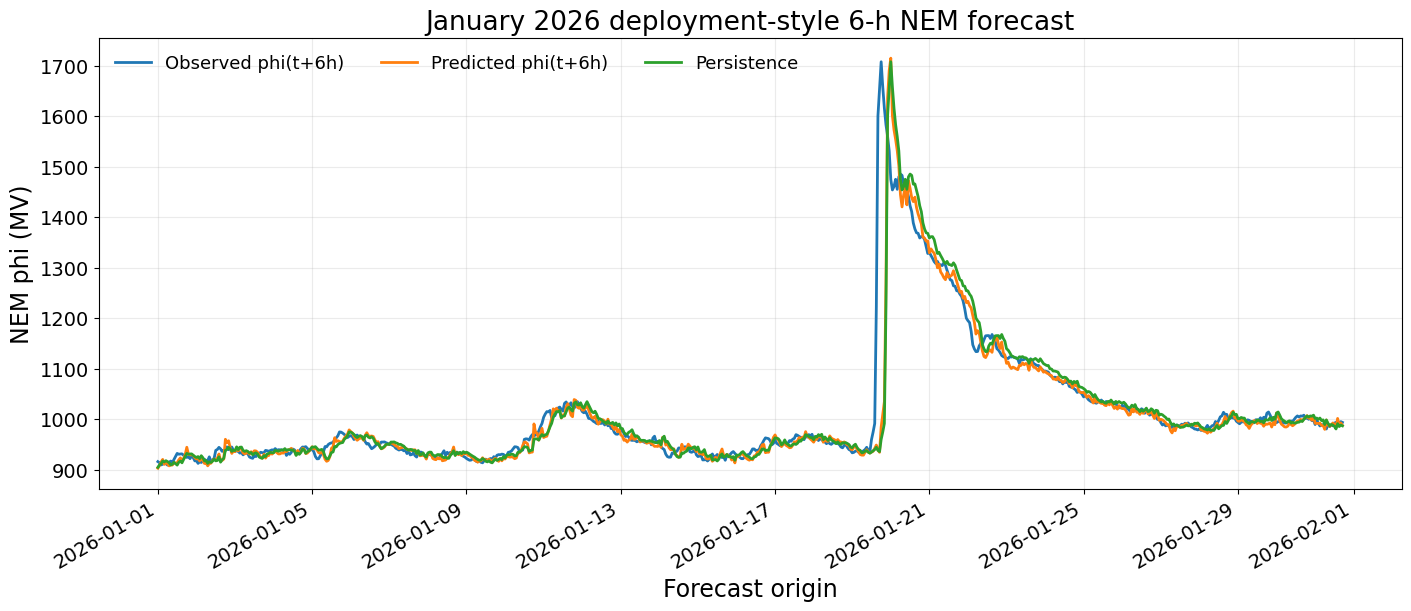

In [42]:

# ============================================================
# CELL 37 — Journal deployment figure: 6-h NEM trajectory
# ============================================================
h=6
d=deploy_reg_pred[deploy_reg_pred["horizon_h"]==h].copy()
if not d.empty:
    observed=d["phi_t"]+d["y_delta"]
    predicted=d["phi_t"]+d["pred_delta"]
    fig,ax=plt.subplots(figsize=(14,6),constrained_layout=True)
    ax.plot(d.index,observed,label="Observed phi(t+6h)")
    ax.plot(d.index,predicted,label="Predicted phi(t+6h)")
    ax.plot(d.index,d["phi_t"],label="Persistence")
    ax.set_xlabel("Forecast origin")
    ax.set_ylabel("NEM phi (MV)")
    ax.set_title("January 2026 deployment-style 6-h NEM forecast")
    ax.legend(frameon=False,ncol=3)
    ax.grid(alpha=0.25)
    fig.autofmt_xdate(rotation=30)
    save_figure(fig,"Fig19_january2026_6h_forecast")
    plt.show()


In [43]:
# ============================================================
# CELL 38 — Paper tables and automatic result summary
# FINAL Q1 VERSION
# ============================================================
reg_confirm_metrics.to_csv(
    TABLE_DIR / "PAPER_Table_continuous_forecasting.csv",
    index=False,
)

cls_confirm_metrics.to_csv(
    TABLE_DIR / "PAPER_Table_transition_warning.csv",
    index=False,
)

state_reg_results.to_csv(
    TABLE_DIR / "PAPER_Table_state_conditioned_skill.csv",
    index=False,
)

state_cls_results.to_csv(
    TABLE_DIR / "PAPER_Table_state_conditioned_transition.csv",
    index=False,
)

reg_skill_ci.to_csv(
    TABLE_DIR / "PAPER_Table_regression_skill_CI.csv",
    index=False,
)

cls_warning_ci.to_csv(
    TABLE_DIR / "PAPER_Table_warning_PR_AUC_CI.csv",
    index=False,
)

event_warning_summary.to_csv(
    TABLE_DIR / "PAPER_Table_event_level_early_warning.csv",
    index=False,
)

state_reg_ci.to_csv(
    TABLE_DIR / "PAPER_Table_state_conditioned_skill_CI.csv",
    index=False,
)

state_risk_ci.to_csv(
    TABLE_DIR / "PAPER_Table_state_conditioned_transition_risk_CI.csv",
    index=False,
)

rc_incremental_results.to_csv(
    TABLE_DIR / "PAPER_Table_operational_Rc_incremental_value.csv",
    index=False,
)

rc_hac_results.to_csv(
    TABLE_DIR / "PAPER_Table_operational_Rc_HAC_tests.csv",
    index=False,
)

vol_reg_results.to_csv(
    TABLE_DIR / "PAPER_Table_current_volatility_predictability.csv",
    index=False,
)

vol_risk_results.to_csv(
    TABLE_DIR / "PAPER_Table_current_volatility_transition_risk.csv",
    index=False,
)

reg_cv_summary.to_csv(
    TABLE_DIR / "PAPER_Supplement_regression_ablation.csv",
    index=False,
)

cls_cv_summary.to_csv(
    TABLE_DIR / "PAPER_Supplement_classification_ablation.csv",
    index=False,
)

gmm_state_sensitivity.to_csv(
    TABLE_DIR / "PAPER_Supplement_GMM_state_sensitivity.csv",
    index=False,
)


summary = []
summary.append("NEM Q1 COMPLETE RUN SUMMARY — FINAL CORRECTED PIPELINE")
summary.append("=" * 78)
summary.append(f"Primary continuous model: {PRIMARY_REG_MODEL}")
summary.append(f"Primary continuous feature set: {PRIMARY_REG_FEATURE_SET}")
summary.append(f"Primary rapid-transition system: {PRIMARY_CLS_MODEL}")
summary.append(
    "Warning probabilities: temporal-OOF Platt calibrated; "
    "alert threshold selected from temporal OOF development predictions."
)
summary.append(
    f"Working descriptive GMM state count: K={SELECTED_K} "
    "(exact physical regime count is NOT claimed)."
)
summary.append("")

summary.append("2021–2025 continuous skill vs persistence:")
for _, r in reg_confirm_metrics[
    (reg_confirm_metrics["model"] == PRIMARY_REG_MODEL)
    & (reg_confirm_metrics["feature_set"] == PRIMARY_REG_FEATURE_SET)
].sort_values("horizon_h").iterrows():
    summary.append(
        f"  h={int(r.horizon_h):2d} h : "
        f"skill={100*r.skill_mse_vs_persistence:.2f}% "
        f"| dphi RMSE={r.dphi_rmse:.3f}"
    )

summary.append("")
summary.append("2021–2025 calibrated rapid-transition warning:")
for h in CLS_HORIZONS:
    d = cls_confirm_pred[
        cls_confirm_pred["horizon_h"] == h
    ]
    m = classification_metrics(
        d["y_event"],
        d["prob_primary_warning"],
        threshold=float(ALERT_THRESHOLDS[h]),
    )
    summary.append(
        f"  h={h:2d} h : "
        f"PR-AUC={m['pr_auc']:.3f} | "
        f"ROC-AUC={m['roc_auc']:.3f} | "
        f"Brier={m['brier']:.4f} | "
        f"event rate={100*m['event_rate']:.2f}% | "
        f"alert threshold={ALERT_THRESHOLDS[h]:.3f}"
    )

summary.append("")
summary.append("Event-level early warning:")
for _, r in event_warning_summary.sort_values("horizon_h").iterrows():
    summary.append(
        f"  h={int(r.horizon_h):2d} h : "
        f"detected={100*r.event_detection_rate:.1f}% | "
        f"false-alarm ratio={100*r.false_alarm_ratio:.1f}% | "
        f"median lead={r.median_lead_time_h:.2f} h"
    )

summary.append("")
summary.append(
    "Interpret GMM partitions as statistical observable states, not as "
    "CME/Forbush/storm classes without independent external validation."
)
summary.append(
    "Use GMM K-sensitivity and current-volatility-decile analyses to support "
    "state-dependent predictability without relying on one exact K."
)
summary.append(
    "Regression SHAP explains the exact primary regression model and its "
    "actual selected feature set."
)
summary.append(
    "SHAP is predictive attribution, not causal evidence."
)

summary_text = "\n".join(summary)
print(summary_text)

with open(
    LOG_DIR / "RUN_SUMMARY.txt",
    "w",
) as f:
    f.write(summary_text)


NEM Q1 COMPLETE RUN SUMMARY — FINAL CORRECTED PIPELINE
Primary continuous model: cat
Primary continuous feature set: A5_phi_rmse_rc_op
Primary rapid-transition system: logistic_full
Warning probabilities: temporal-OOF Platt calibrated; alert threshold selected from temporal OOF development predictions.
Working descriptive GMM state count: K=7 (exact physical regime count is NOT claimed).

2021–2025 continuous skill vs persistence:
  h= 1 h : skill=13.35% | dphi RMSE=4.058
  h= 3 h : skill=17.19% | dphi RMSE=7.888
  h= 6 h : skill=17.32% | dphi RMSE=12.288
  h=12 h : skill=12.27% | dphi RMSE=18.421
  h=24 h : skill=6.89% | dphi RMSE=25.428

2021–2025 calibrated rapid-transition warning:
  h= 3 h : PR-AUC=0.271 | ROC-AUC=0.762 | Brier=0.0536 | event rate=6.27% | alert threshold=0.127
  h= 6 h : PR-AUC=0.285 | ROC-AUC=0.752 | Brier=0.0579 | event rate=6.91% | alert threshold=0.124
  h=12 h : PR-AUC=0.290 | ROC-AUC=0.762 | Brier=0.0544 | event rate=6.55% | alert threshold=0.128
  h=24 h : 

In [44]:
# ============================================================
# CELL 39 — Full reproducibility manifest
# ============================================================
import sklearn, lightgbm, xgboost, catboost

manifest = {
    "title": "When Is the Hourly Near-Earth Cosmic-Ray Modulation Index Predictable?",
    "seed": SEED,
    "dataset_dir": str(DATA_DIR),

    "development": [
        str(MODEL_START),
        str(DEV_END),
    ],

    "confirmation": [
        str(CONFIRM_START),
        str(CONFIRM_END),
    ],

    "deployment": [
        str(DEPLOY_START),
        str(DEPLOY_END),
    ],

    "regression_horizons_h": REG_HORIZONS,
    "classification_horizons_h": CLS_HORIZONS,
    "minimum_active_nm": MIN_ACTIVE_NM,

    "regression_feature_sets": REG_FEATURE_SETS,
    "classification_feature_sets": CLS_FEATURE_SETS,
    "state_features": STATE_FEATURES,

    "primary_regression_model": PRIMARY_REG_MODEL,
    "primary_regression_feature_set": PRIMARY_REG_FEATURE_SET,

    "primary_classification_system": PRIMARY_CLS_MODEL,
    "primary_classification_selection_metric": (
        "mean development temporal-CV PR-AUC across 3/6/12/24 h"
    ),
    "classification_candidates": CLS_PRIMARY_CANDIDATES,

    "classification_probability_calibration": (
        "Platt scaling fitted on pooled strictly temporal out-of-fold "
        "predictions within the training/development period"
    ),

    "alert_threshold_selection": (
        "maximize F1 using temporally OOF calibrated development predictions; "
        "threshold frozen before confirmation evaluation"
    ),

    "event_definition": (
        "max_{1<=s<=h}|phi(t+s)-phi(t)| > training-period Q95"
    ),

    "event_level_evaluation": (
        "independent transition onsets from backward max excursion using the "
        "same threshold; alert counted as hit only within h hours before onset"
    ),

    "operational_rc": "Rc summary features shifted by 3 hours",

    "operational_rc_incremental_test": (
        "paired A5(phi+RMSE+Rc(t-3h)) vs A2(phi+RMSE), "
        "weekly block bootstrap + HAC/Newey-West + Holm correction"
    ),

    "state_analysis": {
        "working_selected_gmm_k": SELECTED_K,
        "gmm_k_values_sensitivity": GMM_K_VALUES,
        "exact_physical_regime_count_claimed": False,
        "robustness": (
            "GMM state-dependence repeated across K plus KMeans ARI "
            "and annual occupancy diagnostic"
        ),
        "state_uncertainty": (
            "calendar-week block-bootstrap confidence intervals"
        ),
        "transparent_noncluster_sensitivity": (
            "development-frozen current 24-h NEM volatility deciles"
        ),
    },

    "xai": {
        "regression": (
            f"SHAP on exact primary model {PRIMARY_REG_MODEL} / "
            f"{PRIMARY_REG_FEATURE_SET}"
        ),
        "classification": XAI_SYSTEM_NOTE,
        "causal_claim": False,
    },

    "bootstrap_reps": BOOTSTRAP_REPS,

    "python": platform.python_version(),

    "packages": {
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "sklearn": sklearn.__version__,
        "lightgbm": lightgbm.__version__,
        "xgboost": xgboost.__version__,
        "catboost": catboost.__version__,
        "shap": shap.__version__,
    },
}

with open(
    LOG_DIR / "run_manifest.json",
    "w",
) as f:
    json.dump(
        manifest,
        f,
        indent=2,
    )

print(
    json.dumps(
        manifest,
        indent=2,
    )
)


{
  "title": "When Is the Hourly Near-Earth Cosmic-Ray Modulation Index Predictable?",
  "seed": 42,
  "dataset_dir": "/kaggle/input/datasets/sadiajahanmoon/cosmicray/Hourlyphiv3",
  "development": [
    "1964-01-01 00:00:00",
    "2020-12-31 23:00:00"
  ],
  "confirmation": [
    "2021-01-01 00:00:00",
    "2025-12-31 23:00:00"
  ],
  "deployment": [
    "2026-01-01 00:00:00",
    "2026-01-31 23:00:00"
  ],
  "regression_horizons_h": [
    1,
    3,
    6,
    12,
    24
  ],
  "classification_horizons_h": [
    3,
    6,
    12,
    24
  ],
  "minimum_active_nm": 5,
  "regression_feature_sets": {
    "A1_phi": [
      "phi_t",
      "phi_lag_1",
      "phi_lag_3",
      "phi_lag_6",
      "phi_lag_12",
      "phi_lag_24",
      "phi_lag_48",
      "phi_lag_72",
      "phi_lag_168",
      "phi_diff_1",
      "phi_diff_3",
      "phi_diff_6",
      "phi_diff_12",
      "phi_diff_24",
      "phi_roll_mean_6",
      "phi_roll_std_6",
      "phi_slope_6",
      "phi_roll_mean_24",
      "